# Combined Pilot Analysis (Mar 6 + Mar 18)

Overview stats and per-config visualizations aggregating all teams that played the same environment.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from collections import defaultdict

from shared import EXPORTS_DIR
from shared.constants import (
    ROLE_MAP, ROLE_NAMES, ROLE_SHORT, ROLE_COLORS, ROLE_CHAR_TO_IDX,
    GAME_ROLE_TO_IDX, ACTION_SYMBOLS, TURNS_PER_STAGE, MAX_STAGES,
    FIGHTER, TANK, MEDIC, F, T, M,
)
from shared.parsing import parse_inferred_roles, parse_deviate_roles, parse_stat_optimal_roles
from shared.data_loading import load_all_exports, to_dataframe, PlayerRound, RoundRecord, StageRecord

## 1. Load Data

In [11]:
EXPORTS = [
    EXPORTS_DIR / 'bayesian-role-specialization-2026-03-06-09-54-19',
    EXPORTS_DIR / 'bayesian-role-specialization-2026-03-18-15-47-09',
]

records = load_all_exports(data_dirs=EXPORTS)
df = to_dataframe(records)

# Add convenience columns
df['envId'] = df['config'].apply(lambda c: c.get('envId', ''))
df['optRolesId'] = df['config'].apply(lambda c: c.get('optimalRolesId', ''))

human = df[df.round_type == 'human'].copy()
bot = df[df.round_type == 'bot'].copy()

print(f'Total: {len(df)} player-rounds ({len(human)} human, {len(bot)} bot)')
print(f'Games: {df.game_id.nunique()}, Exports: {df.export_name.nunique()}')

Loaded bayesian-role-specialization-2026-03-06-09-54-19: 96 player-rounds
Loaded bayesian-role-specialization-2026-03-18-15-47-09: 240 player-rounds
Total: 336 player-rounds from 2 exports
Total: 336 player-rounds (252 human, 84 bot)
Games: 14, Exports: 2


## 2. Summary Statistics

In [12]:
# --- Outcome rates ---
# One outcome per team-round (deduplicate by game_id + round_number)
team_rounds = df.drop_duplicates(subset=['game_id', 'round_number'])
human_tr = team_rounds[team_rounds.round_type == 'human']
bot_tr = team_rounds[team_rounds.round_type == 'bot']

def outcome_table(label, subset):
    total = len(subset)
    wins = (subset.outcome == 'WIN').sum()
    losses = (subset.outcome == 'LOSE').sum()
    timeouts = (subset.outcome == 'TIMEOUT').sum()
    print(f'\n{label} ({total} team-rounds):')
    print(f'  Win:     {wins:3d} ({100*wins/total:.1f}%)')
    print(f'  Lose:    {losses:3d} ({100*losses/total:.1f}%)')
    print(f'  Timeout: {timeouts:3d} ({100*timeouts/total:.1f}%)')

outcome_table('Human rounds', human_tr)
outcome_table('Bot rounds', bot_tr)


Human rounds (84 team-rounds):
  Win:      72 (85.7%)
  Lose:      4 (4.8%)
  Timeout:   8 (9.5%)

Bot rounds (28 team-rounds):
  Win:       9 (32.1%)
  Lose:     12 (42.9%)
  Timeout:   7 (25.0%)


In [13]:
# --- Stat-optimal role adherence (human rounds) ---
# For each player-round, check how often they chose their stat-optimal role
adherence_data = []
for _, row in human.iterrows():
    optimal = row['optimal_roles']
    pid = row['player_id']
    if pid >= len(optimal):
        continue
    my_optimal = optimal[pid]
    roles = row['role_idxs']
    for si, r in enumerate(roles):
        adherence_data.append({
            'stage': si + 1,
            'chose_optimal': int(r == my_optimal),
            'stat_profile_id': row['stat_profile_id'],
        })

adh_df = pd.DataFrame(adherence_data)
print('Stat-optimal role adherence (human rounds):')
print(f'  Overall: {adh_df.chose_optimal.mean():.1%}')
print(f'  By stage:')
for stage, group in adh_df.groupby('stage'):
    print(f'    Stage {stage}: {group.chose_optimal.mean():.1%} (n={len(group)})')
print(f'  By stat profile:')
for sp, group in adh_df.groupby('stat_profile_id'):
    print(f'    {sp}: {group.chose_optimal.mean():.1%} (n={len(group)})')

Stat-optimal role adherence (human rounds):
  Overall: 60.8%
  By stage:
    Stage 1: 58.7% (n=252)
    Stage 2: 64.7% (n=252)
    Stage 3: 59.8% (n=249)
    Stage 4: 63.4% (n=101)
    Stage 5: 47.2% (n=36)
  By stat profile:
    114_222_222: 67.3% (n=159)
    222_222_222: 57.9% (n=126)
    411_141_114: 58.7% (n=475)
    411_222_222: 63.1% (n=130)


In [14]:
# --- Inference accuracy ---
# Inference at stage N is about stage N-1 roles
# Group by round type to check against actual roles (human) or fixed bot roles

def compute_inference_accuracy(records, round_type='human'):
    """Compute inference accuracy across all player-rounds of given type.
    
    For human rounds: group by game_id + round_number to get all 3 players' stages,
    then check each player's inferences against the others' previous-stage roles.
    
    For bot rounds: check against the bots' fixed roles from config.
    """
    results = {'correct': 0, 'total': 0, 'by_stage': defaultdict(lambda: [0, 0])}
    
    subset = [r for r in records if r.round.round_type == round_type]
    
    if round_type == 'bot':
        for pr in subset:
            rnd = pr.round
            config = rnd.config
            human_role_pos = config.get('humanRole', 0)
            bot_players = config.get('botPlayers', [])
            bot_indices = [i for i in range(3) if i != human_role_pos]
            bot_fixed = {}
            for i, bi in enumerate(bot_indices):
                if i < len(bot_players):
                    bot_fixed[bi] = bot_players[i]['strategy']['role']
            
            for stage in rnd.stages:
                if not stage.inferred_roles:
                    continue
                for target_pos, inferred_role in stage.inferred_roles.items():
                    if target_pos in bot_fixed:
                        results['total'] += 1
                        results['by_stage'][stage.stage][1] += 1
                        if inferred_role == bot_fixed[target_pos]:
                            results['correct'] += 1
                            results['by_stage'][stage.stage][0] += 1
    else:
        # Group players by (game_id, round_number)
        teams = defaultdict(list)
        for pr in subset:
            teams[(pr.game_id, pr.round.round_number)].append(pr)
        
        for key, team_prs in teams.items():
            # Build lookup: player_id -> list of stage roles
            player_stages = {}
            for pr in team_prs:
                player_stages[pr.player_id] = pr.round.stages
            
            for pr in team_prs:
                for si, stage in enumerate(pr.round.stages):
                    if si == 0 or not stage.inferred_roles:
                        continue
                    for target_pos, inferred_role in stage.inferred_roles.items():
                        if target_pos in player_stages and si - 1 < len(player_stages[target_pos]):
                            actual_role = player_stages[target_pos][si - 1].role_idx
                            results['total'] += 1
                            results['by_stage'][stage.stage][1] += 1
                            if inferred_role == actual_role:
                                results['correct'] += 1
                                results['by_stage'][stage.stage][0] += 1
    
    return results

for rt in ['human', 'bot']:
    res = compute_inference_accuracy(records, rt)
    pct = 100 * res['correct'] / max(1, res['total'])
    print(f'\n{rt.upper()} round inference accuracy: {res["correct"]}/{res["total"]} ({pct:.1f}%) [chance=33.3%]')
    for s in sorted(res['by_stage']):
        c, t = res['by_stage'][s]
        print(f'  Stage {s}: {c}/{t} ({100*c/max(1,t):.1f}%)')


HUMAN round inference accuracy: 694/1140 (60.9%) [chance=33.3%]
  Stage 2: 293/436 (67.2%)
  Stage 3: 244/442 (55.2%)
  Stage 4: 116/196 (59.2%)
  Stage 5: 41/66 (62.1%)

BOT round inference accuracy: 132/265 (49.8%) [chance=33.3%]
  Stage 2: 49/96 (51.0%)
  Stage 3: 43/94 (45.7%)
  Stage 4: 19/42 (45.2%)
  Stage 5: 21/33 (63.6%)


## 3. Per-Config Visualizations

For each environment config, show all teams' plays side by side.

### 3a. Visualization helpers

In [15]:
# Player colors (consistent: P1=red, P2=blue, P3=green)
PLAYER_COLORS = ['#e74c3c', '#3498db', '#2ecc71']
MARKERS = ['o', 's', '^']

COLOR_CORRECT = '#2ecc71'
COLOR_INCORRECT = '#e74c3c'
OUTCOME_COLOR = {'WIN': 'green', 'LOSE': 'red', 'TIMEOUT': 'orange'}


def _flatten_turns(pr):
    """Flatten a PlayerRound's stages into a list of per-turn dicts."""
    tlist = []
    for stage in pr.round.stages:
        for turn in stage.turns:
            tlist.append({
                'role': stage.role_idx,
                'action': turn.get('action', '?'),
                'teamHealth': turn.get('teamHealth', 0),
                'enemyHealth': turn.get('enemyHealth', 0),
                'inferredRoles': stage.inferred_roles,
                'stage': stage.stage,
            })
    return tlist


def plot_team_human(fig, team_prs, round_label=''):
    """Plot a human round for one team: roles, inferences, health (3 panels)."""
    rnd = team_prs[0].round
    config = rnd.config
    intent = rnd.enemy_intent_sequence
    optimal = rnd.optimal_roles
    
    players = {pr.player_id: pr for pr in team_prs}
    player_turns = {pid: _flatten_turns(pr) for pid, pr in players.items()}
    
    # Derive n from actual turn data (max across players)
    n = max(len(t) for t in player_turns.values()) if player_turns else 0
    if n == 0:
        return
    tn = list(range(1, n + 1))
    
    gs = fig.add_gridspec(3, 1, height_ratios=[3, 2, 1.5], hspace=0.35)
    ax_r = fig.add_subplot(gs[0])
    ax_i = fig.add_subplot(gs[1])
    ax_h = fig.add_subplot(gs[2])
    
    # --- Panel 1: Role choices ---
    for pid in sorted(players.keys()):
        turns_data = player_turns.get(pid, [])
        roles = [t['role'] for t in turns_data]
        actions = [t['action'] for t in turns_data]
        if not roles or all(r == -1 for r in roles):
            continue
        
        ps = players[pid].round.player_stats
        sl = f"({ps.get('STR','?')}/{ps.get('DEF','?')}/{ps.get('SUP','?')})" if ps else ''
        
        player_tn = list(range(1, len(roles) + 1))
        ax_r.plot(player_tn, roles, marker=MARKERS[pid], color=PLAYER_COLORS[pid],
                  label=f'P{pid+1} {sl}', markersize=8, linewidth=2, zorder=10)
        
        for i, (x, r, a) in enumerate(zip(player_tn, roles, actions)):
            if r != -1 and a != '?':
                lbl = ACTION_SYMBOLS.get(a, '?')
                ax_r.text(x, r + 0.18 + pid * 0.12, lbl, fontsize=7, fontweight='bold',
                          color=PLAYER_COLORS[pid], ha='center', va='bottom',
                          bbox=dict(boxstyle='round,pad=0.08', facecolor='white',
                                    edgecolor=PLAYER_COLORS[pid], alpha=0.85, linewidth=0.5))
    
    # Enemy attack shading
    for i, ch in enumerate(intent[:n]):
        if ch == '1':
            ax_r.axvspan(i + 0.7, i + 1.3, alpha=0.1, color='red')
    
    # Per-player optimal role reference lines
    if optimal:
        for p, o in enumerate(optimal):
            if p < 3:
                ax_r.axhline(y=o, color=PLAYER_COLORS[p], linestyle='--', alpha=0.3)
    
    ax_r.set_ylim(-0.5, 3)
    ax_r.set_yticks([0, 1, 2])
    ax_r.set_yticklabels(['Fighter', 'Tank', 'Medic'])
    ax_r.set_xlim(0.5, n + 0.5)
    ax_r.set_xticks(tn)
    ax_r.grid(True, alpha=0.3)
    ax_r.legend(loc='upper right', fontsize=8)
    
    outcome = rnd.outcome
    oc = OUTCOME_COLOR.get(outcome, 'black')
    config_id = config.get('optimalRolesId', 'N/A')
    stat_profile = rnd.stat_profile_id
    game_id = team_prs[0].game_id
    ax_r.set_title(f'Config: {config_id} | Stats: {stat_profile} | {round_label} | {outcome}\n'
                   f'Game: {game_id}',
                   color=oc, fontweight='bold', fontsize=9)
    
    # --- Panel 2: Inferences (6 rows: all pairwise) ---
    inf_labels = ['P1→P2', 'P1→P3', 'P2→P1', 'P2→P3', 'P3→P1', 'P3→P2']
    inf_rows = [(0, 1), (0, 2), (1, 0), (1, 2), (2, 0), (2, 1)]
    
    for pid in sorted(players.keys()):
        turns_data = player_turns.get(pid, [])
        prev_stage = 0
        for ti, t in enumerate(turns_data):
            stage = t['stage']
            if stage > prev_stage and prev_stage > 0:
                inferred = t['inferredRoles']
                for target, ir in inferred.items():
                    if (pid, target) in inf_rows:
                        ri = inf_rows.index((pid, target))
                        target_turns = player_turns.get(target, [])
                        actual = target_turns[ti - 1]['role'] if ti > 0 and ti - 1 < len(target_turns) else -1
                        if actual != -1:
                            correct = ir == actual
                            c = COLOR_CORRECT if correct else COLOR_INCORRECT
                        else:
                            c = '#999'
                        ax_i.text(ti + 1, ri, ROLE_SHORT.get(ir, '?'), fontsize=8, fontweight='bold',
                                  color=c, ha='center', va='center',
                                  bbox=dict(boxstyle='round,pad=0.12', facecolor='white',
                                            edgecolor=c, alpha=0.9))
                ax_r.axvline(x=ti + 0.5, color=PLAYER_COLORS[pid], linestyle=':', alpha=0.3)
                ax_i.axvline(x=ti + 0.5, color=PLAYER_COLORS[pid], linestyle=':', alpha=0.3)
            prev_stage = stage
    
    ax_i.set_ylim(-0.5, 5.5)
    ax_i.set_yticks(range(6))
    ax_i.set_yticklabels(inf_labels, fontsize=8)
    ax_i.set_xlim(0.5, n + 0.5)
    ax_i.set_xticks(tn)
    ax_i.set_title('Inferences (green=correct, red=incorrect)', fontsize=9)
    ax_i.grid(True, alpha=0.2)
    
    # --- Panel 3: Health bars with turn 0 ---
    max_th = config.get('maxTeamHealth', 10)
    max_eh = config.get('maxEnemyHealth', 30)
    first_pid = sorted(players.keys())[0]
    first_turns = player_turns[first_pid]
    actual_n = len(first_turns)
    th = [max_th] + [t['teamHealth'] for t in first_turns]
    eh = [max_eh] + [t['enemyHealth'] for t in first_turns]
    health_x = list(range(0, actual_n + 1))
    w = 0.35
    x_arr = np.array(health_x)
    ax_h.bar(x_arr - w / 2, th, w, label='Team HP', color='#3498db', alpha=0.7)
    ax_h.bar(x_arr + w / 2, eh, w, label='Enemy HP', color='#e74c3c', alpha=0.7)
    ax_h.set_xlim(-0.5, actual_n + 0.5)
    ax_h.set_xticks(health_x)
    ax_h.set_xticklabels(['Start'] + [str(i) for i in range(1, actual_n + 1)], fontsize=7)
    ax_h.set_xlabel('Turn')
    ax_h.set_ylabel('Health')
    ax_h.legend(loc='upper right', fontsize=8)
    ax_h.grid(True, alpha=0.3, axis='y')


def plot_team_bot(fig, team_prs, round_label=''):
    """Plot a bot round for one team (1 human + 2 bots)."""
    pr = team_prs[0]
    rnd = pr.round
    config = rnd.config
    intent = rnd.enemy_intent_sequence
    human_pos = config.get('humanRole', 0)
    bot_players = config.get('botPlayers', [])
    bot_positions = [i for i in range(3) if i != human_pos]
    bot_roles_idx = [bp['strategy']['role'] for bp in bot_players]
    
    human_stat_opt = rnd.optimal_roles[0] if rnd.optimal_roles else -1
    human_dev_opt = rnd.deviate_roles[0] if rnd.deviate_roles else -1
    
    human_turns = _flatten_turns(pr)
    n = len(human_turns)
    if n == 0:
        return
    tn = list(range(1, n + 1))
    
    gs = fig.add_gridspec(3, 1, height_ratios=[3, 2, 1.5], hspace=0.35)
    ax_r = fig.add_subplot(gs[0])
    ax_i = fig.add_subplot(gs[1])
    ax_h = fig.add_subplot(gs[2])
    
    # --- Panel 1: Role choices ---
    human_roles = [t['role'] for t in human_turns]
    human_actions = [t['action'] for t in human_turns]
    ps = rnd.player_stats
    sl = f"({ps.get('STR','?')}/{ps.get('DEF','?')}/{ps.get('SUP','?')})" if ps else ''
    
    ax_r.plot(tn, human_roles, marker=MARKERS[human_pos],
              color=PLAYER_COLORS[human_pos],
              label=f'P{human_pos+1} [HUMAN] {sl}', markersize=8, linewidth=2, zorder=10)
    
    for i, (x, r, a) in enumerate(zip(tn, human_roles, human_actions)):
        if r != -1 and a != '?':
            lbl = ACTION_SYMBOLS.get(a, '?')
            ax_r.text(x, r + 0.2, lbl, fontsize=7, fontweight='bold',
                      color=PLAYER_COLORS[human_pos], ha='center', va='bottom',
                      bbox=dict(boxstyle='round,pad=0.08', facecolor='white',
                                edgecolor=PLAYER_COLORS[human_pos], alpha=0.85, linewidth=0.5))
    
    for bi, bpos in enumerate(bot_positions):
        bot_role = bot_roles_idx[bi]
        ax_r.plot(tn, [bot_role] * n, marker=MARKERS[bpos], color=PLAYER_COLORS[bpos],
                  label=f'P{bpos+1} [BOT: {ROLE_NAMES[bot_role]}]',
                  markersize=6, linewidth=1.5, alpha=0.5, linestyle='--', zorder=5)
    
    for i, ch in enumerate(intent[:n]):
        if ch == '1':
            ax_r.axvspan(i + 0.7, i + 1.3, alpha=0.1, color='red')
    
    if human_stat_opt >= 0:
        ax_r.axhline(y=human_stat_opt, color='gray', linestyle='--', alpha=0.5, linewidth=1.5,
                     label=f'Stat-opt: {ROLE_NAMES[human_stat_opt]}')
    if human_dev_opt >= 0:
        ax_r.axhline(y=human_dev_opt, color='purple', linestyle=':', alpha=0.7, linewidth=2.5,
                     label=f'Dev-opt: {ROLE_NAMES[human_dev_opt]}')
    
    ax_r.set_ylim(-0.5, 3)
    ax_r.set_yticks([0, 1, 2])
    ax_r.set_yticklabels(['Fighter', 'Tank', 'Medic'])
    ax_r.set_xlim(0.5, n + 0.5)
    ax_r.set_xticks(tn)
    ax_r.grid(True, alpha=0.3)
    ax_r.legend(loc='upper right', fontsize=7, ncol=2)
    
    outcome = rnd.outcome
    oc = OUTCOME_COLOR.get(outcome, 'black')
    config_id = rnd.optimal_deviate_roles_id or 'N/A'
    stat_profile = rnd.stat_profile_id
    game_id = pr.game_id
    ax_r.set_title(f'BOT ROUND | Config: {config_id} | Stats: {stat_profile} | {round_label} | {outcome}\n'
                   f'Game: {game_id}',
                   color=oc, fontweight='bold', fontsize=9)
    
    # --- Panel 2: Inferences (human -> each bot) ---
    inf_labels = [f'Human→P{bp+1}' for bp in bot_positions]
    
    prev_stage = 0
    for ti, t in enumerate(human_turns):
        stage = t['stage']
        if stage > prev_stage and prev_stage > 0:
            inferred = t['inferredRoles']
            for target_pos, ir in inferred.items():
                if target_pos in bot_positions:
                    ri = bot_positions.index(target_pos)
                    actual = bot_roles_idx[ri]
                    correct = ir == actual
                    c = COLOR_CORRECT if correct else COLOR_INCORRECT
                    ax_i.text(ti + 1, ri, ROLE_SHORT.get(ir, '?'), fontsize=9, fontweight='bold',
                              color=c, ha='center', va='center',
                              bbox=dict(boxstyle='round,pad=0.12', facecolor='white',
                                        edgecolor=c, alpha=0.9))
            ax_r.axvline(x=ti + 0.5, color=PLAYER_COLORS[human_pos], linestyle=':', alpha=0.3)
            ax_i.axvline(x=ti + 0.5, color=PLAYER_COLORS[human_pos], linestyle=':', alpha=0.3)
        prev_stage = stage
    
    ax_i.set_ylim(-0.5, len(inf_labels) - 0.5)
    ax_i.set_yticks(range(len(inf_labels)))
    ax_i.set_yticklabels(inf_labels, fontsize=8)
    ax_i.set_xlim(0.5, n + 0.5)
    ax_i.set_xticks(tn)
    ax_i.set_title('Inferences about bots (green=correct, red=incorrect)', fontsize=9)
    ax_i.grid(True, alpha=0.2)
    
    # --- Panel 3: Health bars with turn 0 ---
    max_th = config.get('maxTeamHealth', 10)
    max_eh = config.get('maxEnemyHealth', 30)
    th = [max_th] + [t['teamHealth'] for t in human_turns]
    eh = [max_eh] + [t['enemyHealth'] for t in human_turns]
    health_x = list(range(0, n + 1))
    w = 0.35
    x_arr = np.array(health_x)
    ax_h.bar(x_arr - w / 2, th, w, label='Team HP', color='#3498db', alpha=0.7)
    ax_h.bar(x_arr + w / 2, eh, w, label='Enemy HP', color='#e74c3c', alpha=0.7)
    ax_h.set_xlim(-0.5, n + 0.5)
    ax_h.set_xticks(health_x)
    ax_h.set_xticklabels(['Start'] + [str(i) for i in range(1, n + 1)], fontsize=7)
    ax_h.set_xlabel('Turn')
    ax_h.set_ylabel('Health')
    ax_h.legend(loc='upper right', fontsize=8)
    ax_h.grid(True, alpha=0.3, axis='y')

In [16]:
def plot_config_overview(config_key, team_groups, round_type='human'):
    """Plot all teams that played the same config.
    
    Each team gets its own figure with 3 vertically stacked panels
    (roles, inferences, health).
    """
    n_teams = len(team_groups)
    if n_teams == 0:
        return
    
    # Config summary header
    sample_rnd = team_groups[0][0].round
    optimal = [ROLE_SHORT[r] for r in sample_rnd.optimal_roles]
    intent = sample_rnd.enemy_intent_sequence
    
    header = f'{round_type.upper()} | {config_key} | optimal={"".join(optimal)} | intent={intent}'
    if round_type == 'bot' and sample_rnd.deviate_roles:
        deviate = [ROLE_SHORT[r] for r in sample_rnd.deviate_roles]
        header += f' | deviate={"".join(deviate)}'
    
    outcomes = [tg[0].round.outcome for tg in team_groups]
    wins = outcomes.count('WIN')
    print(f'  Win rate: {wins}/{n_teams} ({100*wins/n_teams:.0f}%)')
    
    for i, team_prs in enumerate(team_groups):
        rnd = team_prs[0].round
        round_label = f'Round {rnd.round_number}'
        
        fig = plt.figure(figsize=(14, 8))
        fig.suptitle(f'{header}\nTeam {i+1}/{n_teams}', fontsize=10, fontweight='bold')
        
        if round_type == 'human':
            plot_team_human(fig, team_prs, round_label=round_label)
        else:
            plot_team_bot(fig, team_prs, round_label=round_label)
        
        fig.tight_layout()
        plt.show()

### 3b. Group records by config and plot

In [17]:
def group_into_teams(records, round_type='human'):
    """Group PlayerRound records into teams by config.
    
    Returns: dict mapping config_key -> list of teams,
             where each team is a list of PlayerRound (one per player).
    """
    # First group by (game_id, round_number) to get teams
    round_groups = defaultdict(list)
    for r in records:
        if r.round.round_type != round_type:
            continue
        round_groups[(r.game_id, r.round.round_number)].append(r)
    
    # Then group teams by config key
    config_teams = defaultdict(list)
    for key, team_prs in round_groups.items():
        rnd = team_prs[0].round
        if round_type == 'human':
            config_key = f'{rnd.stat_profile_id} / {rnd.config.get("optimalRolesId", "")}'
        else:
            config_key = f'{rnd.stat_profile_id} / {rnd.optimal_deviate_roles_id}'
        config_teams[config_key].append(team_prs)
    
    return dict(config_teams)

### Human rounds


114_222_222 / MFF: 14 teams
  Win rate: 13/14 (93%)


/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


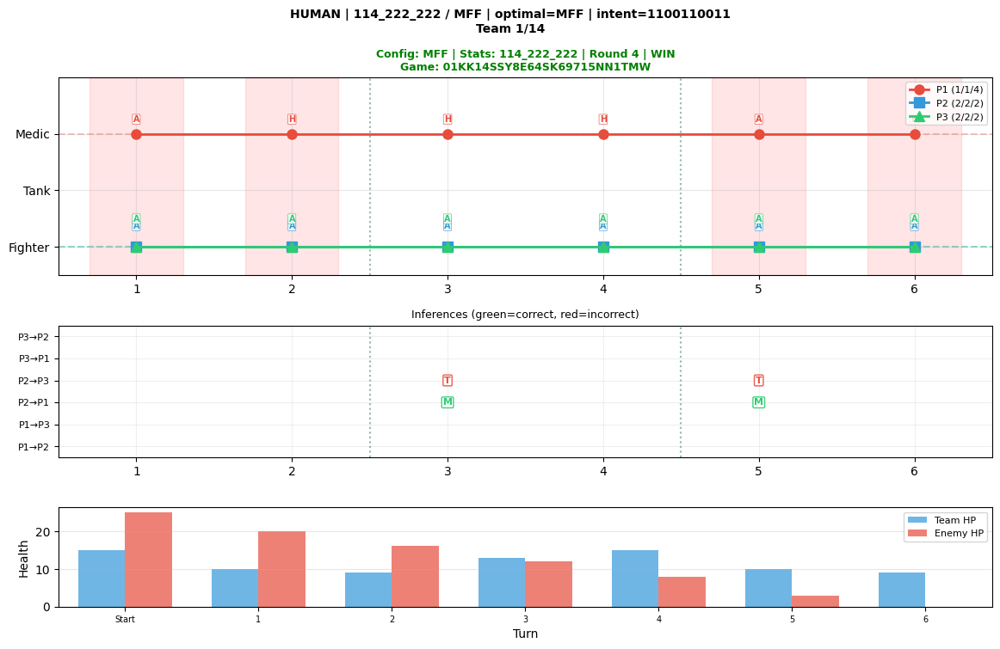

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


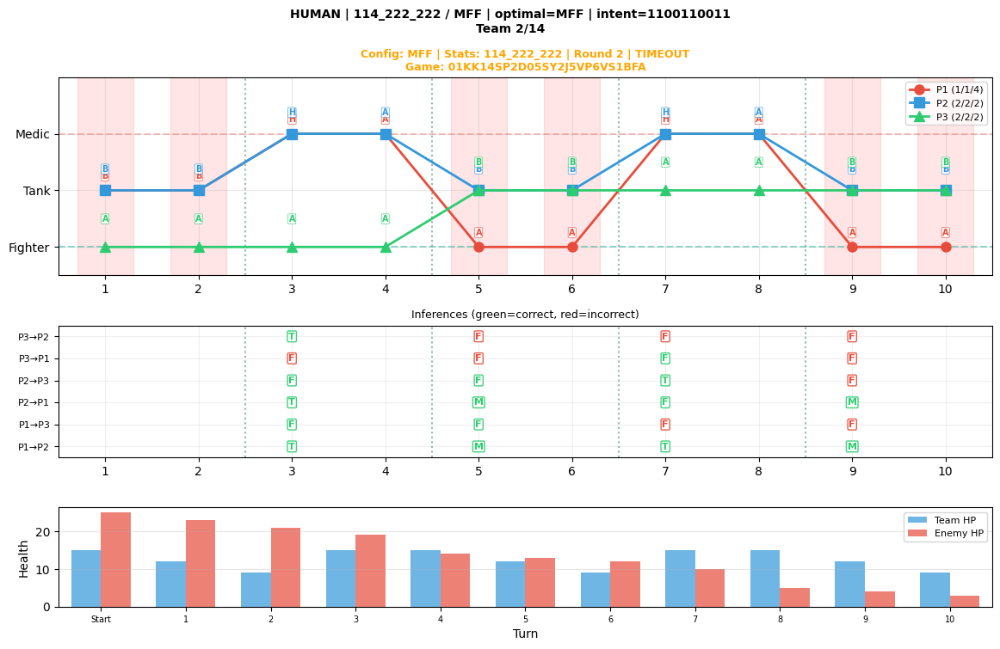

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


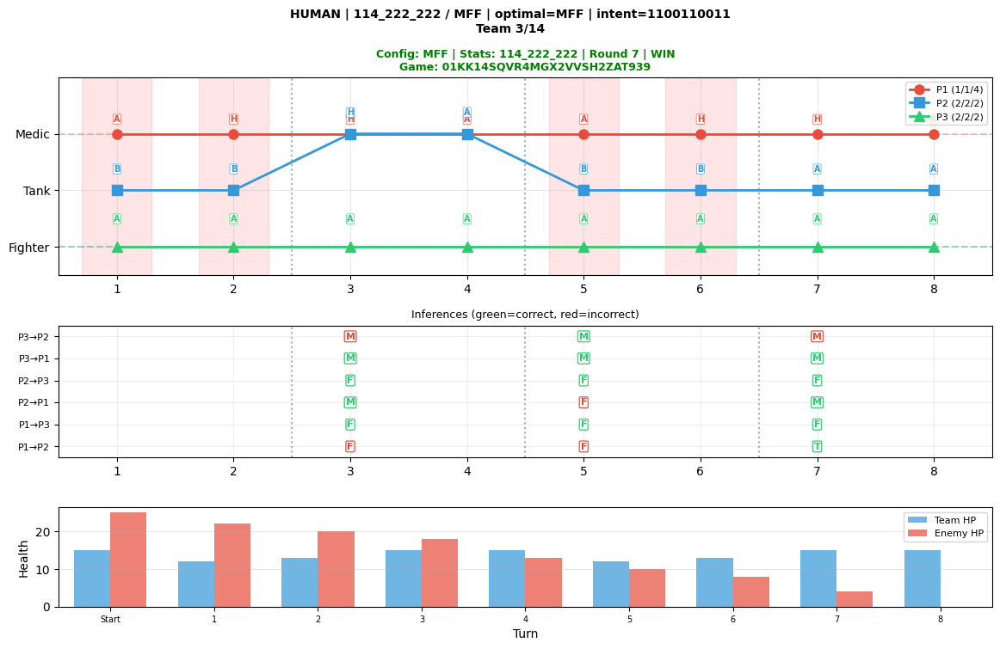

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


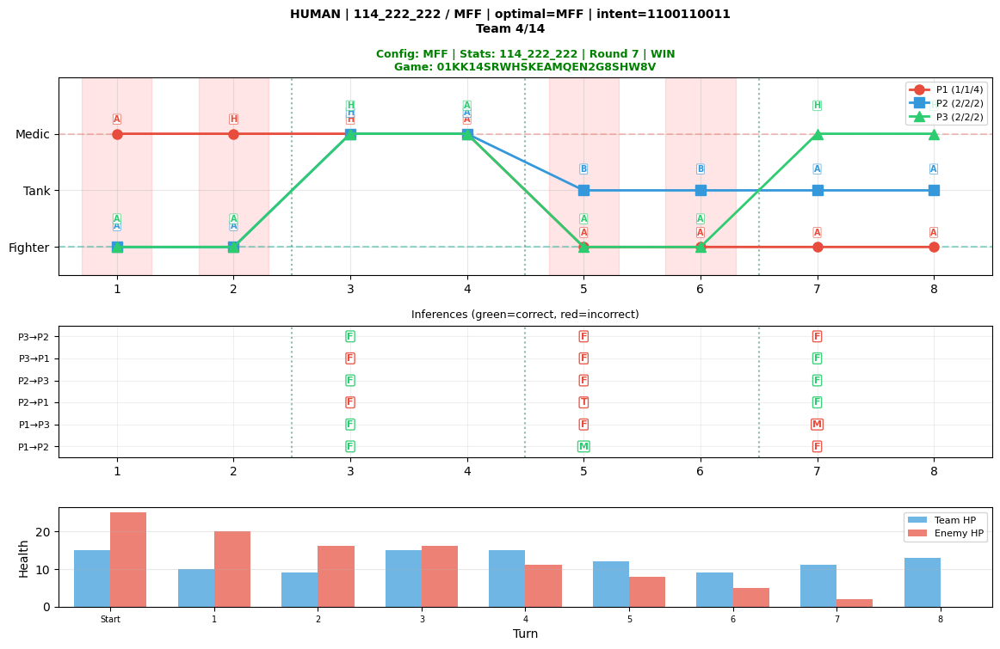

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


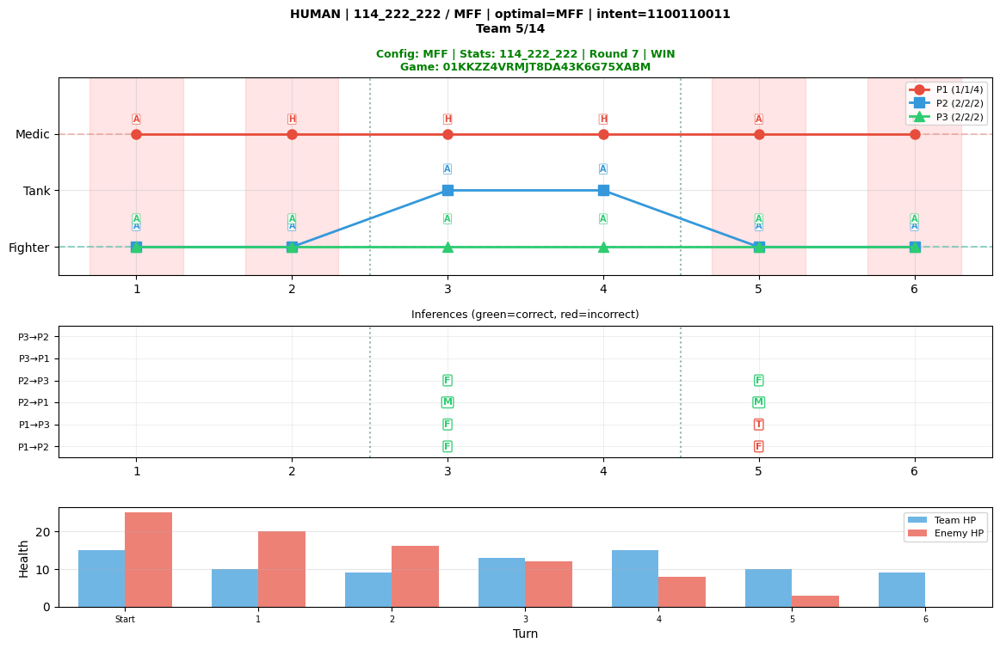

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


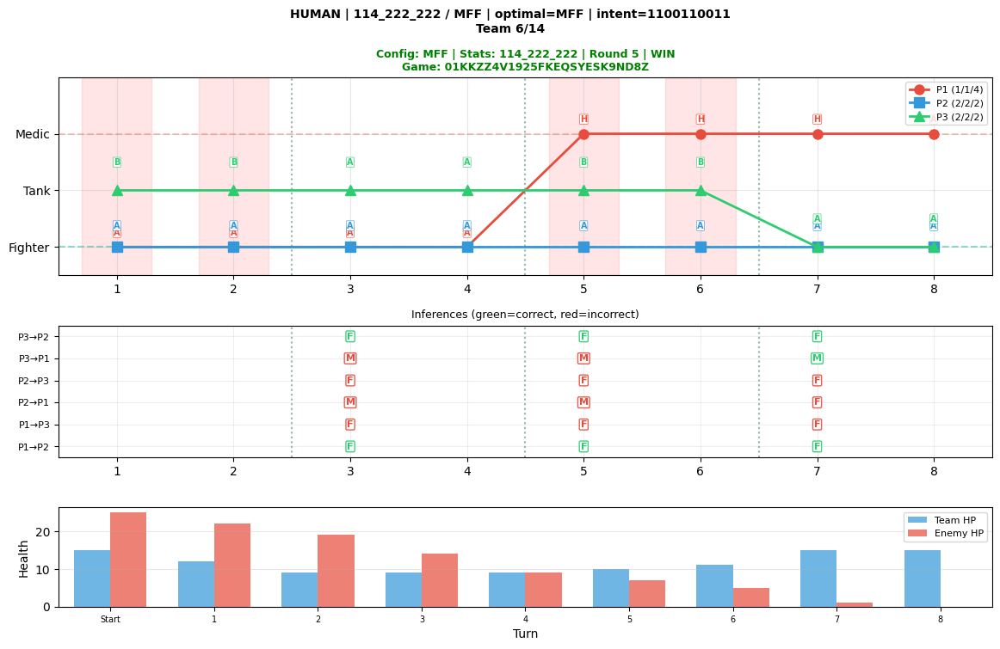

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


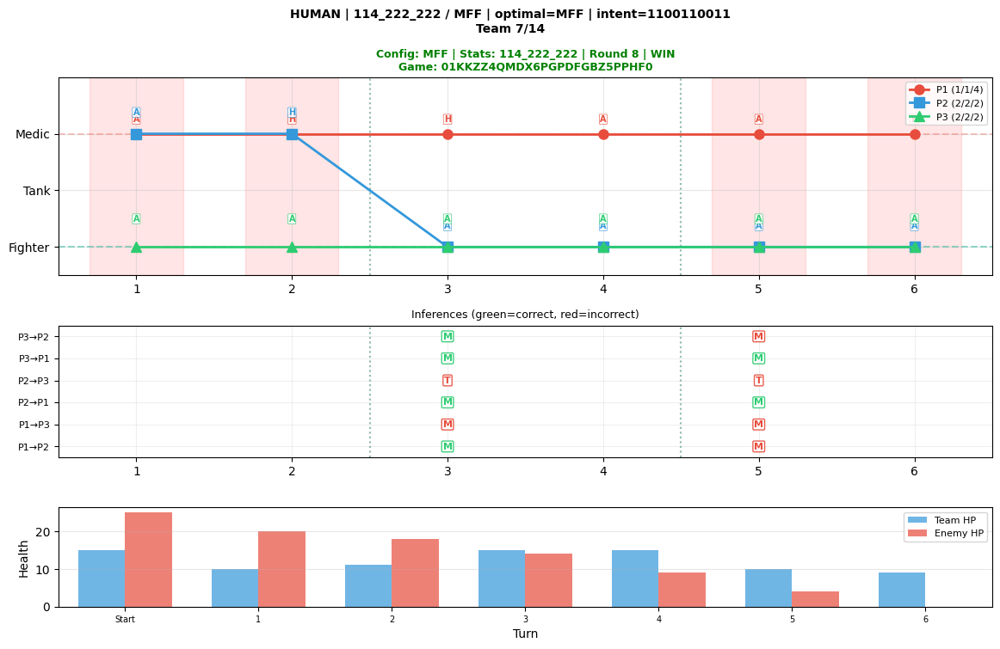

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


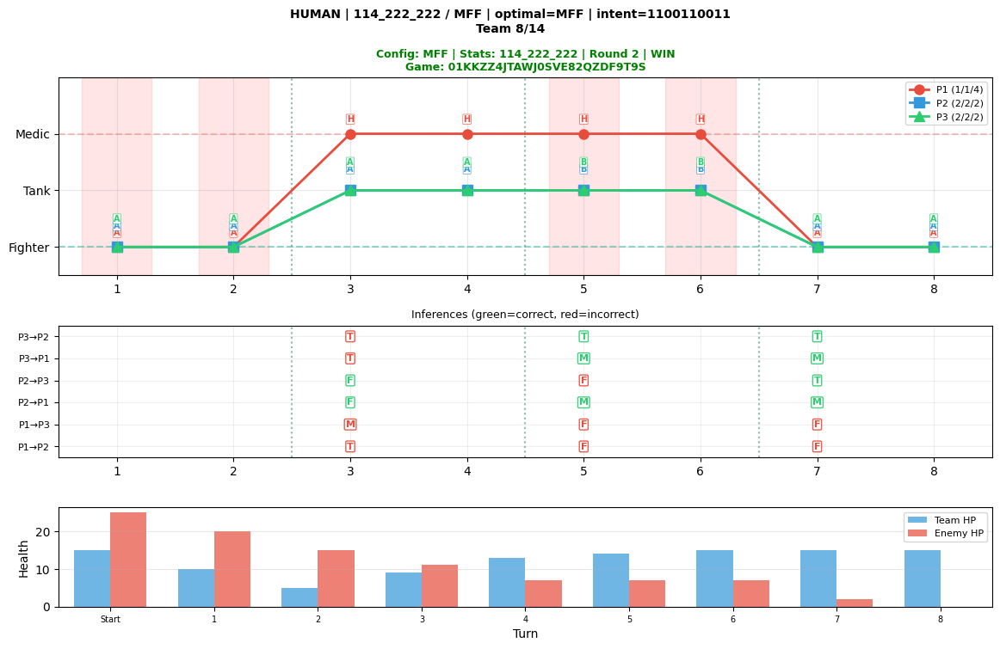

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


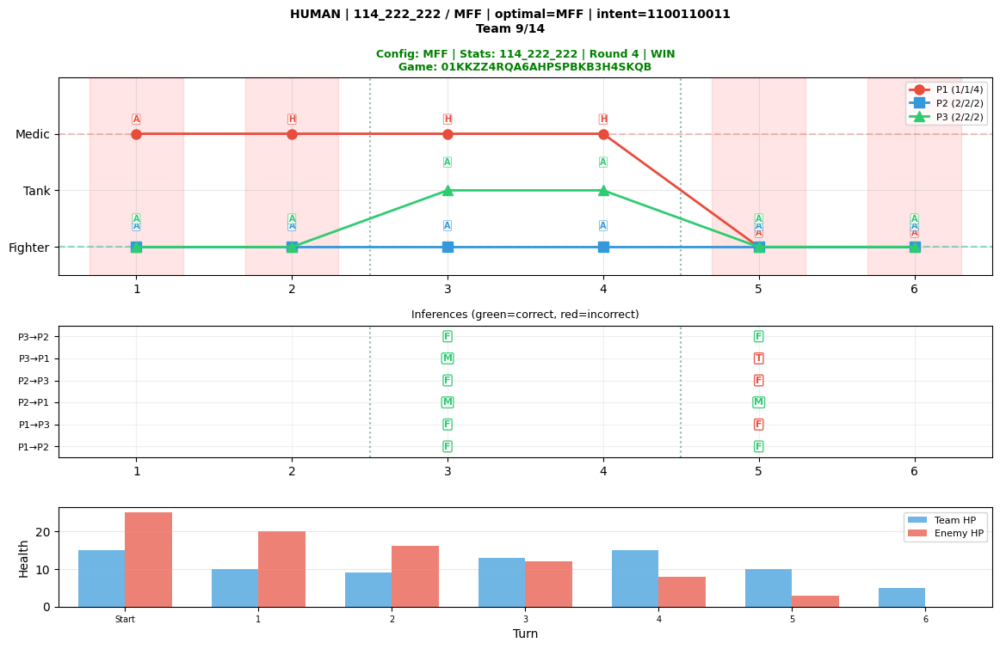

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


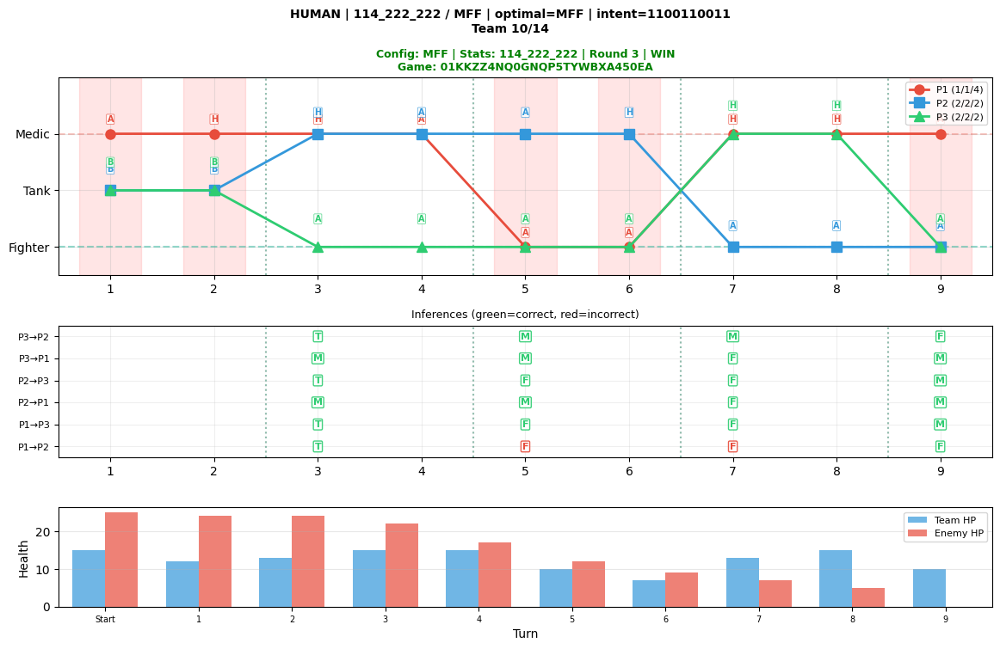

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


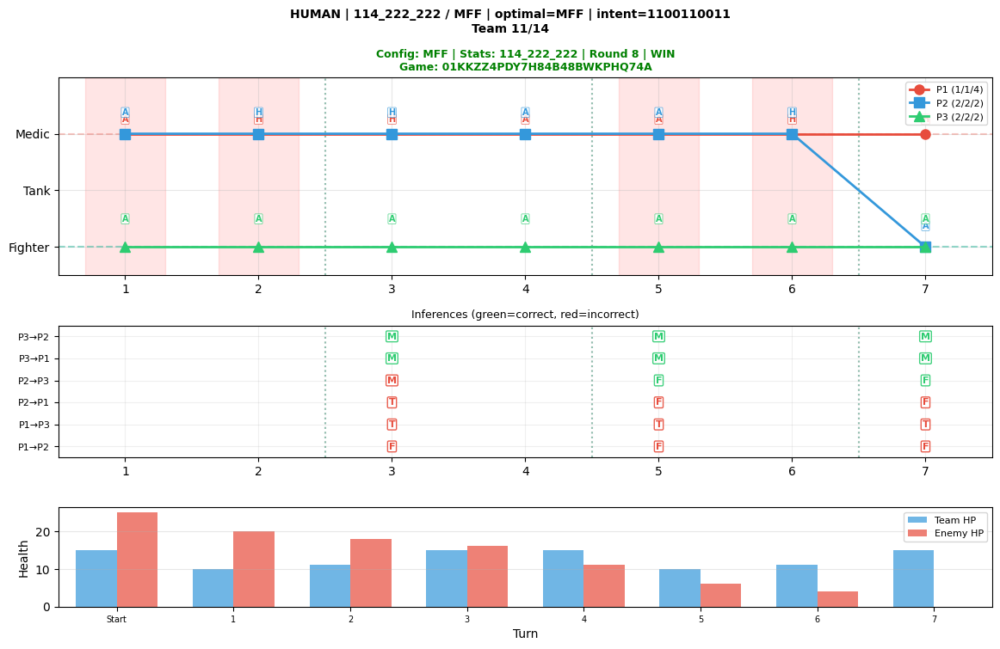

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


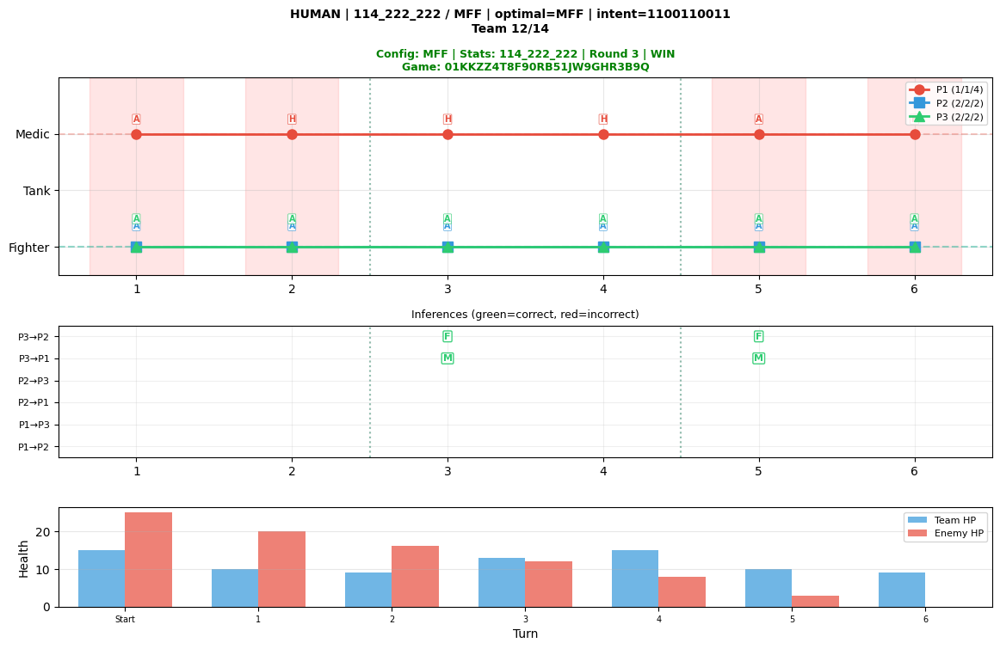

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


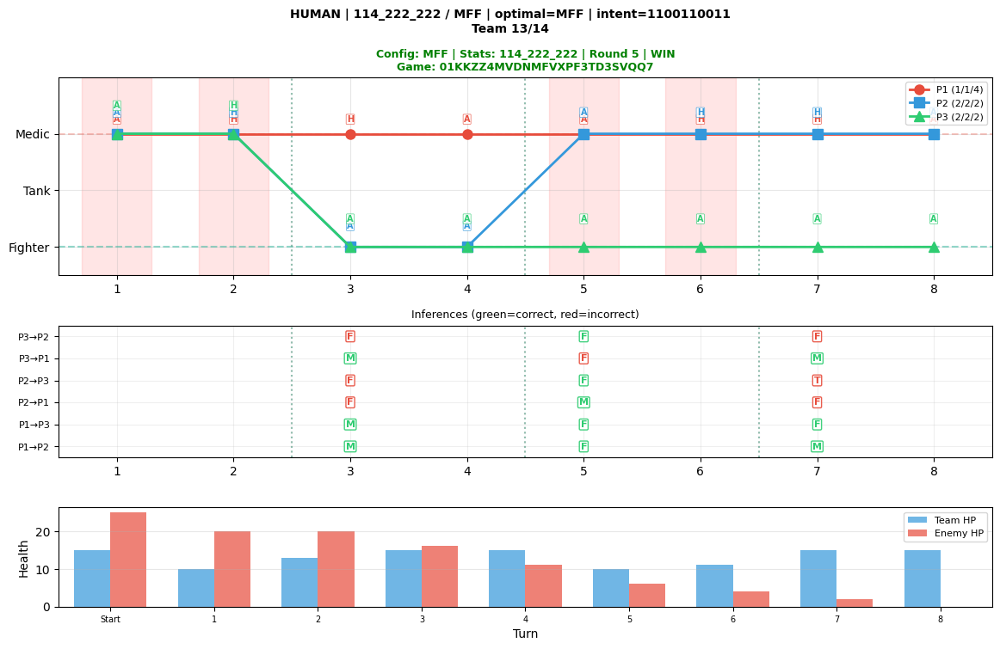

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


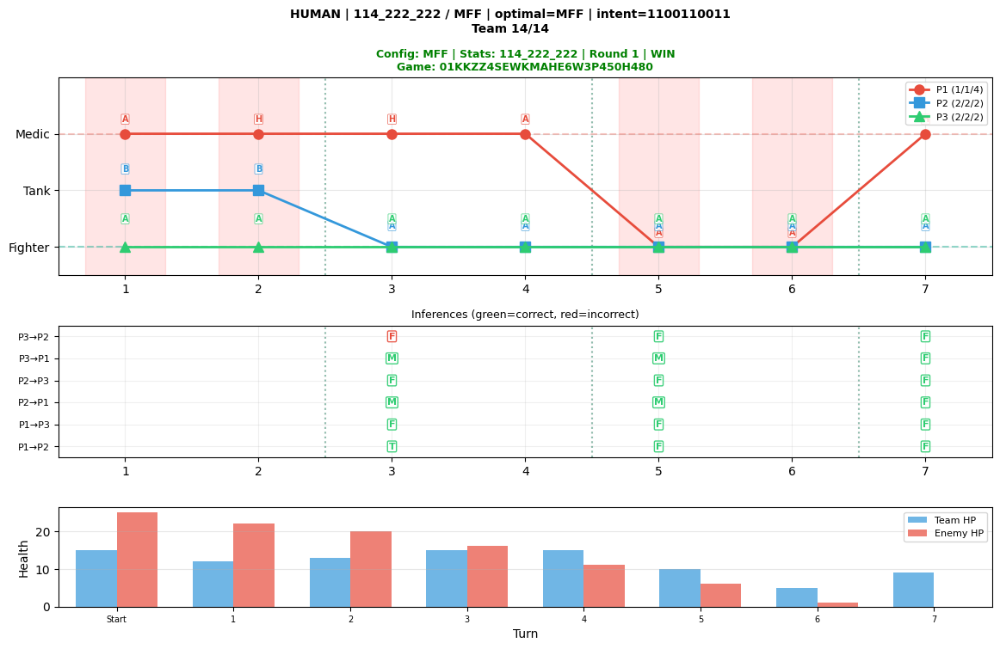

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



222_222_222 / FFF: 14 teams
  Win rate: 14/14 (100%)


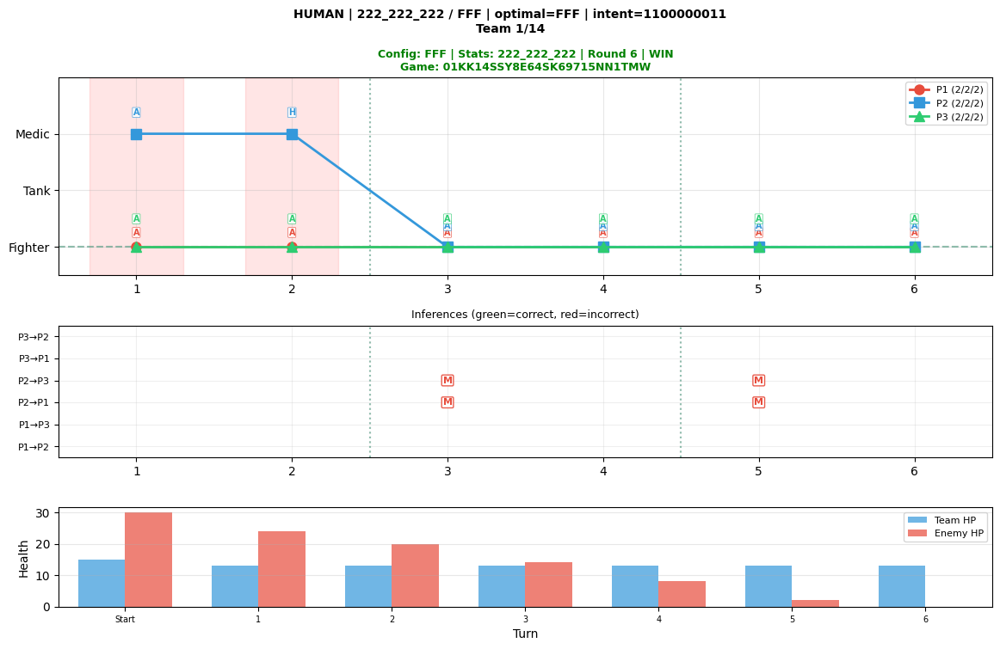

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


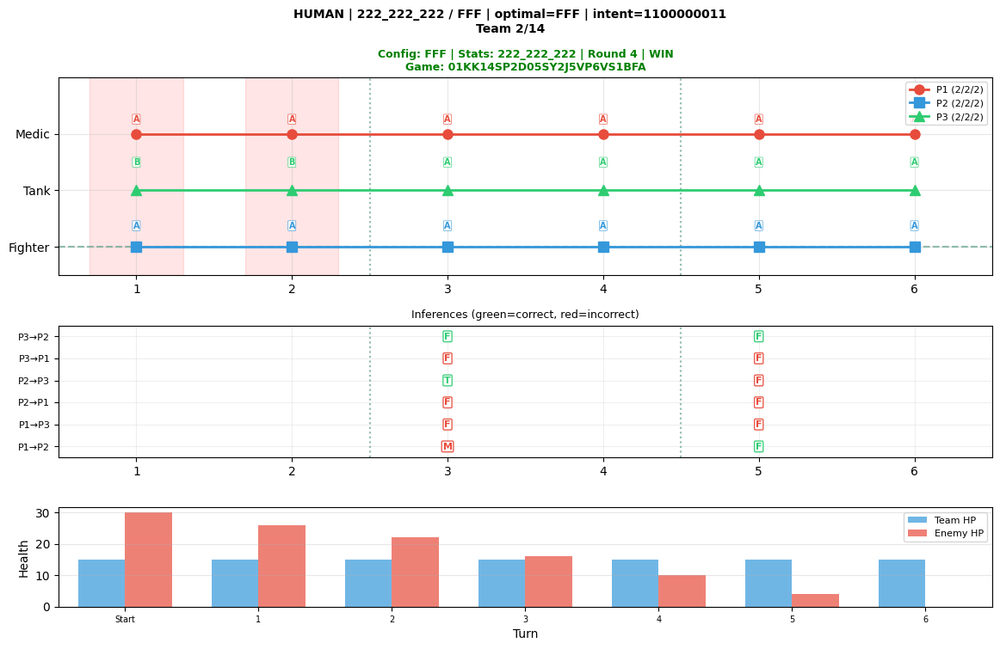

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


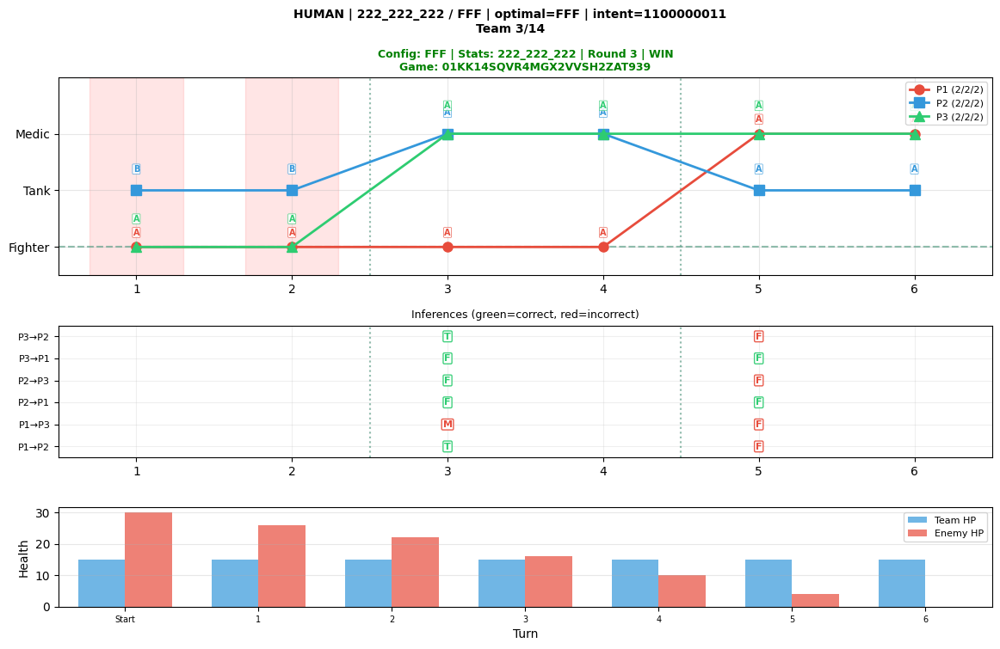

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


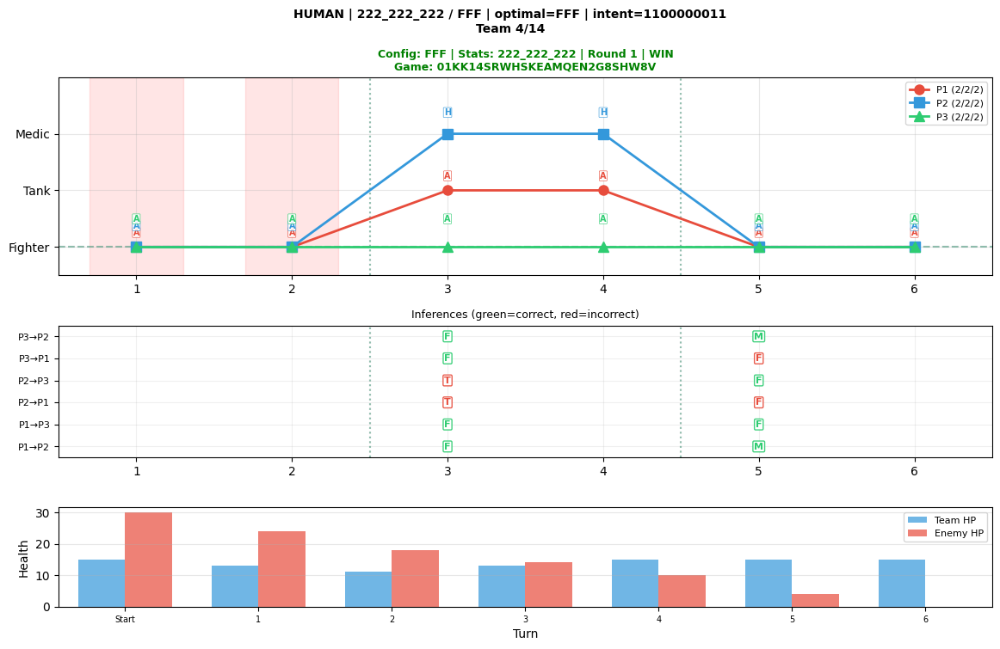

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


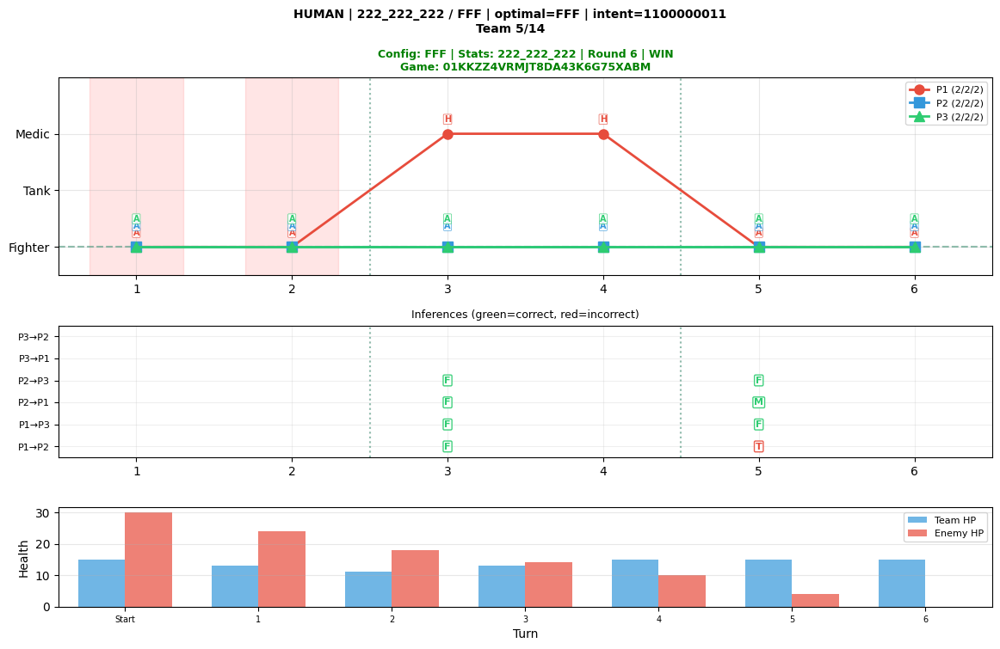

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


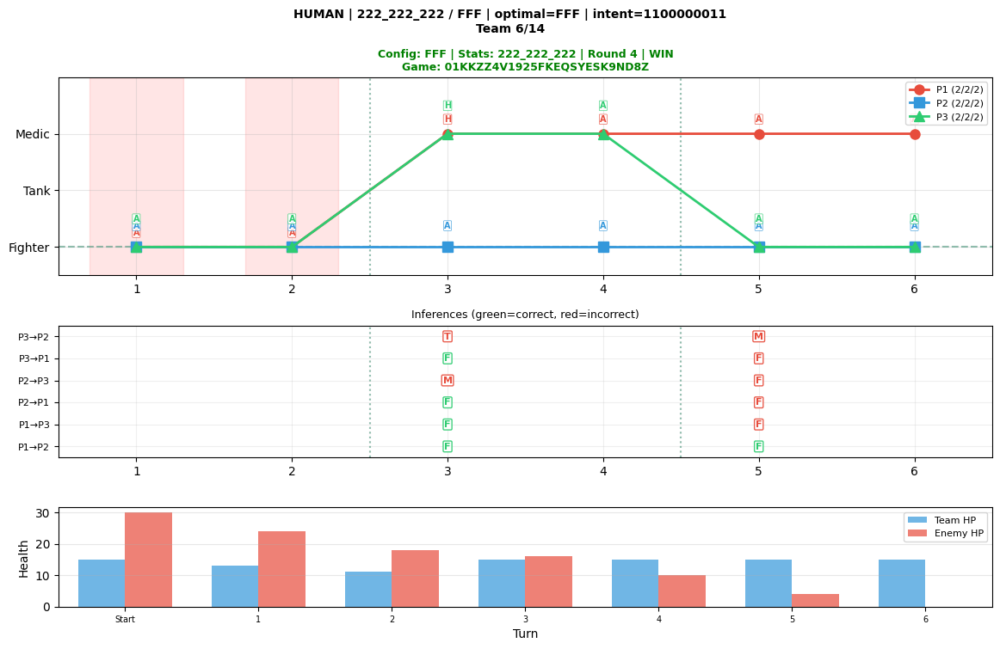

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


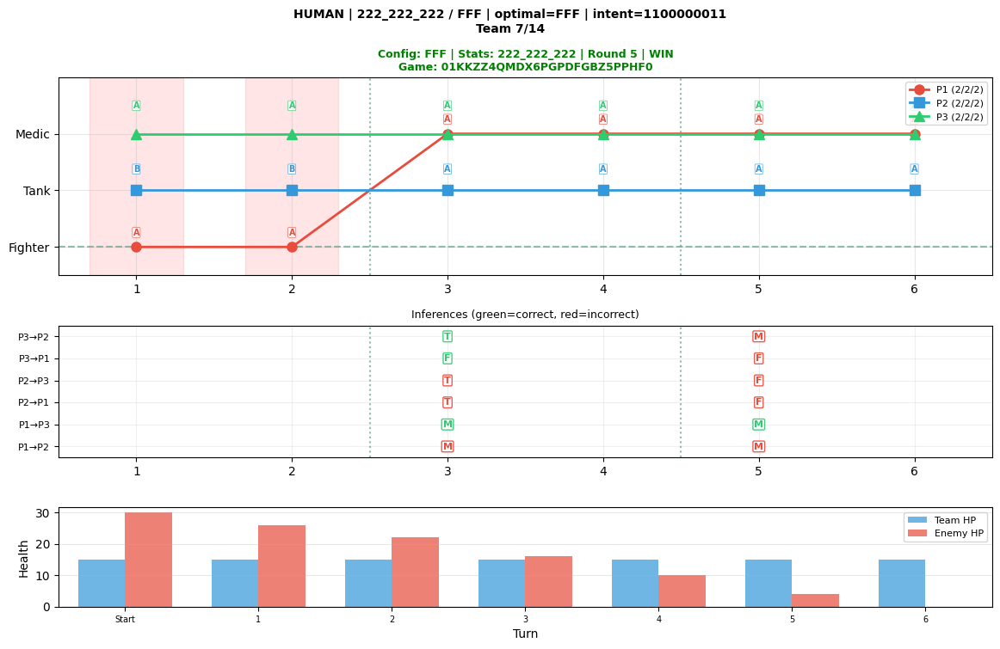

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


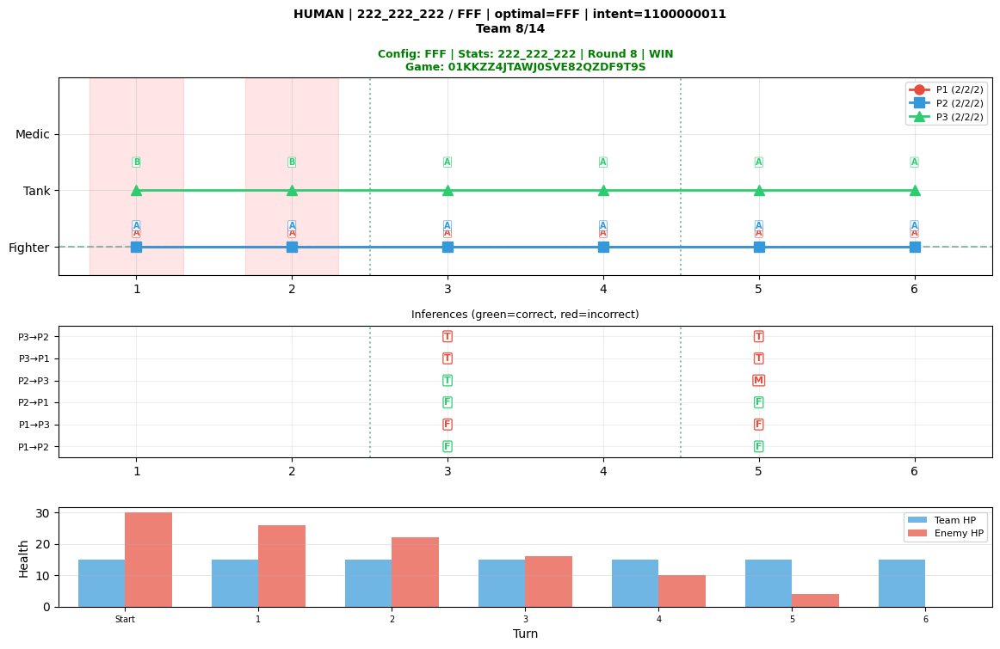

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


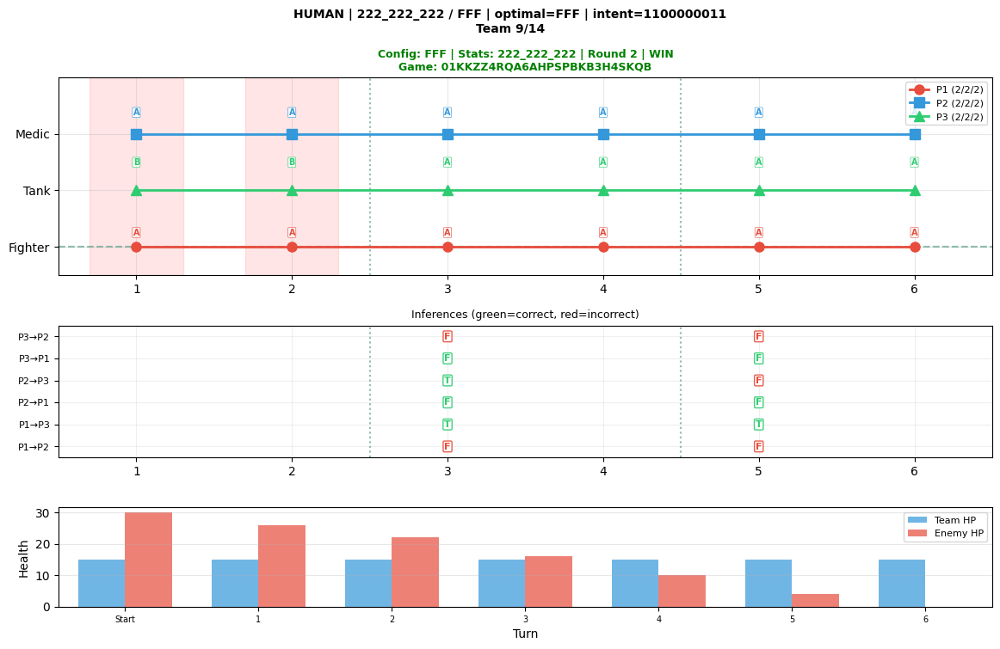

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


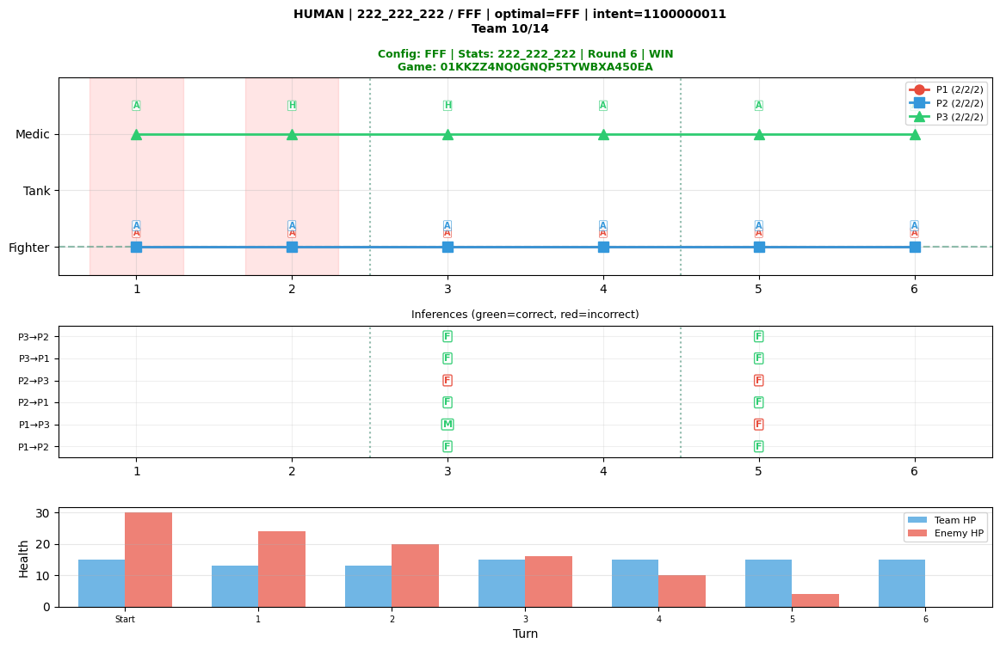

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


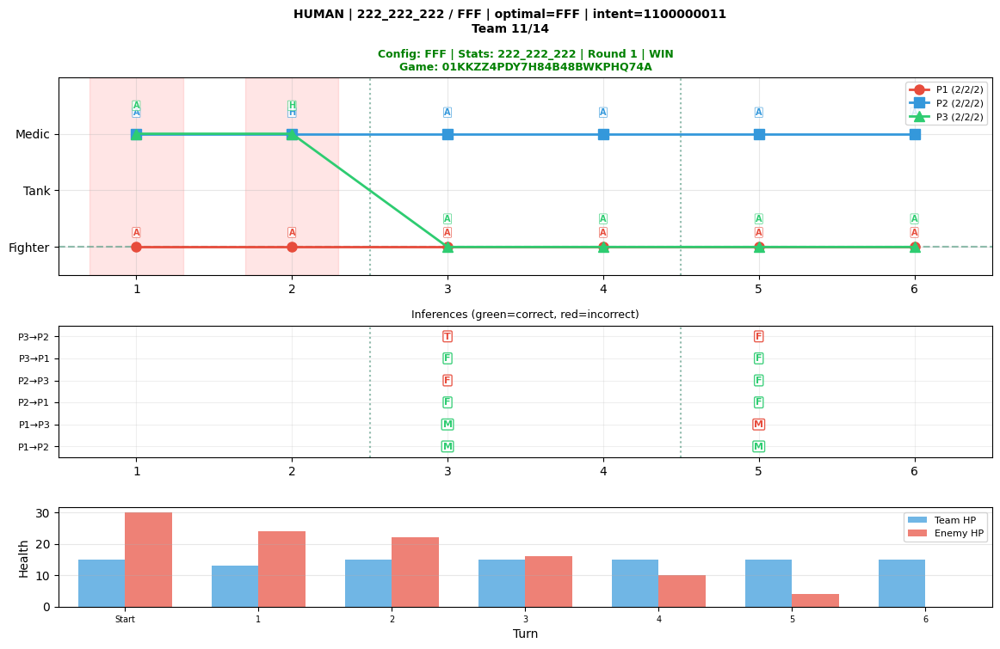

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


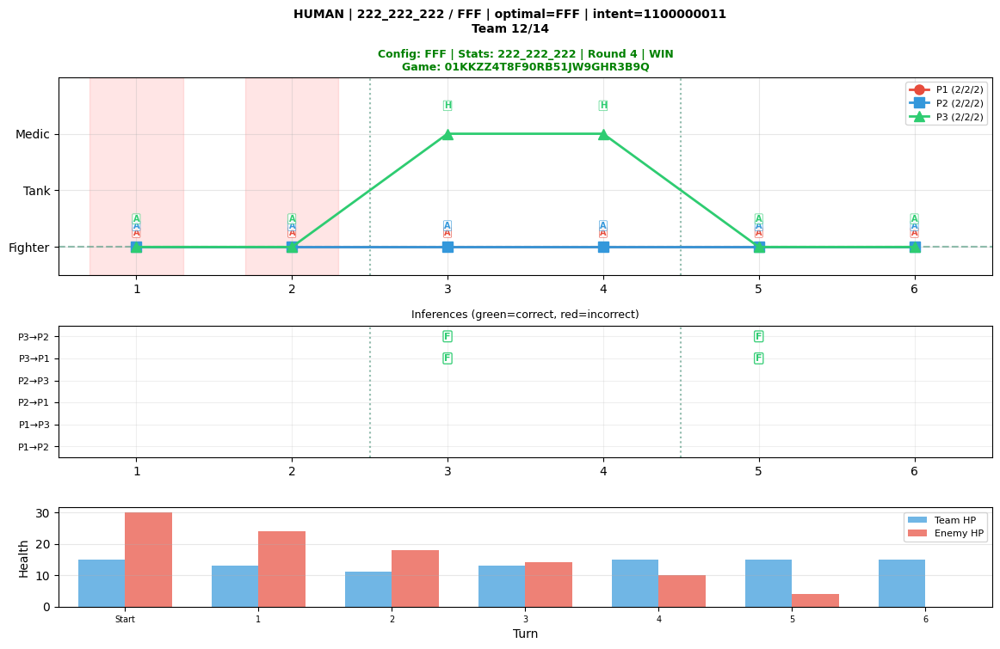

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


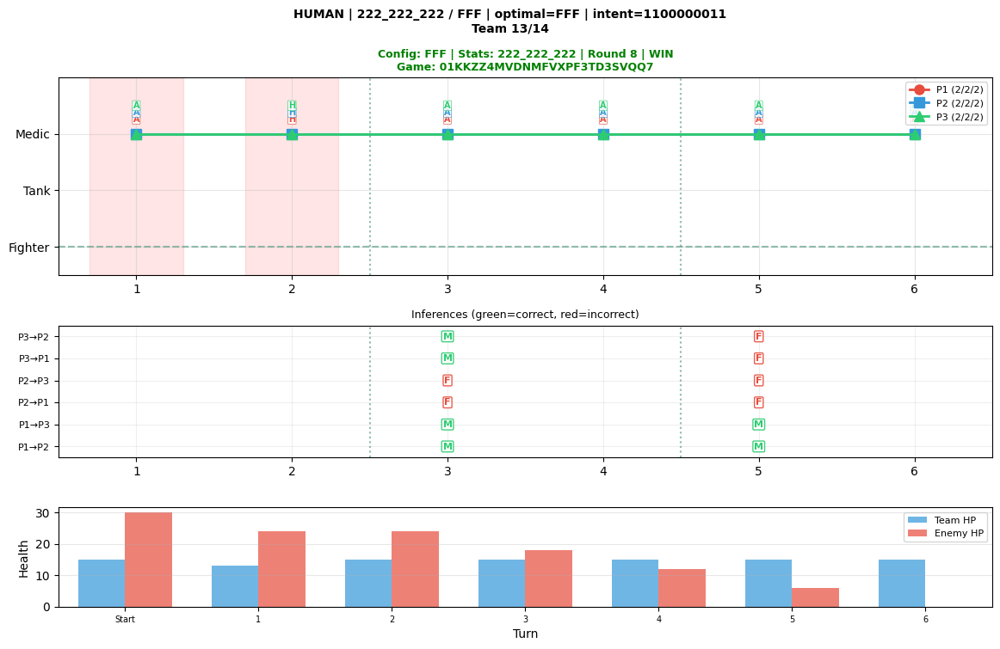

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


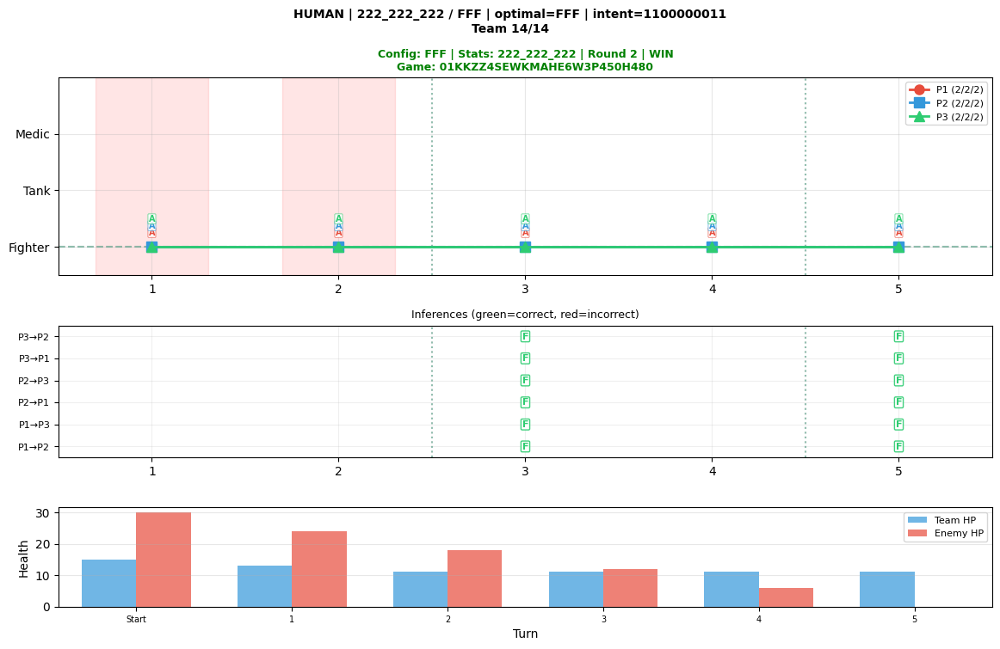

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



411_141_114 / FFM: 14 teams
  Win rate: 13/14 (93%)


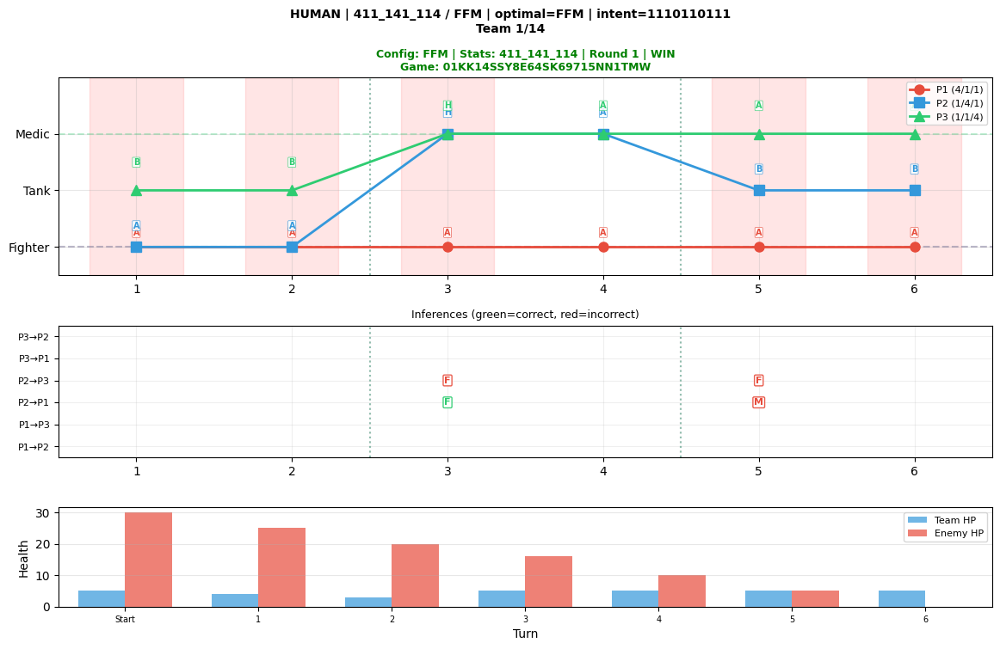

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


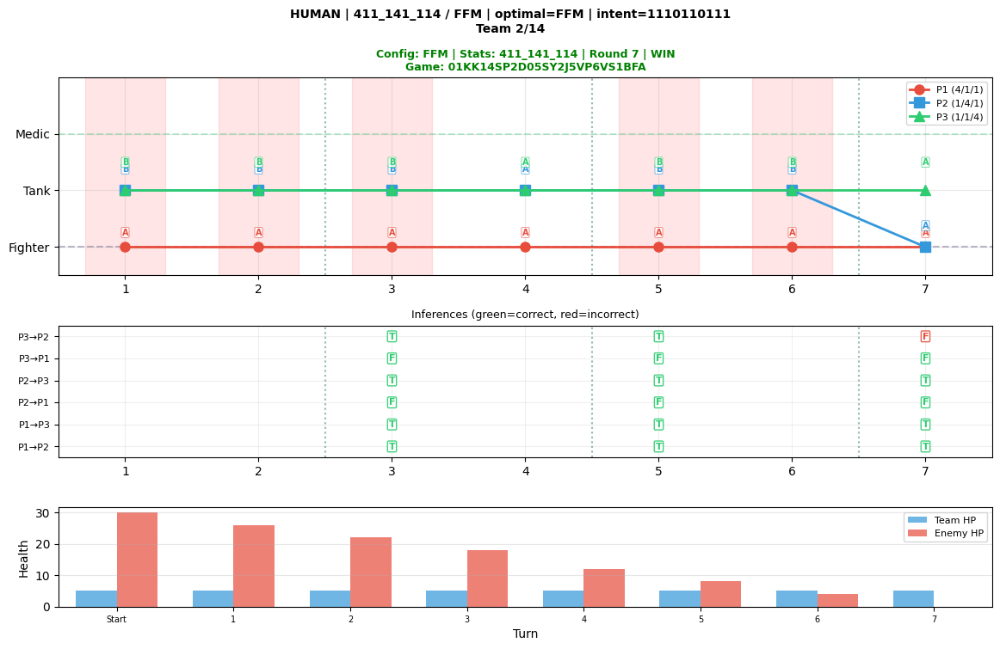

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


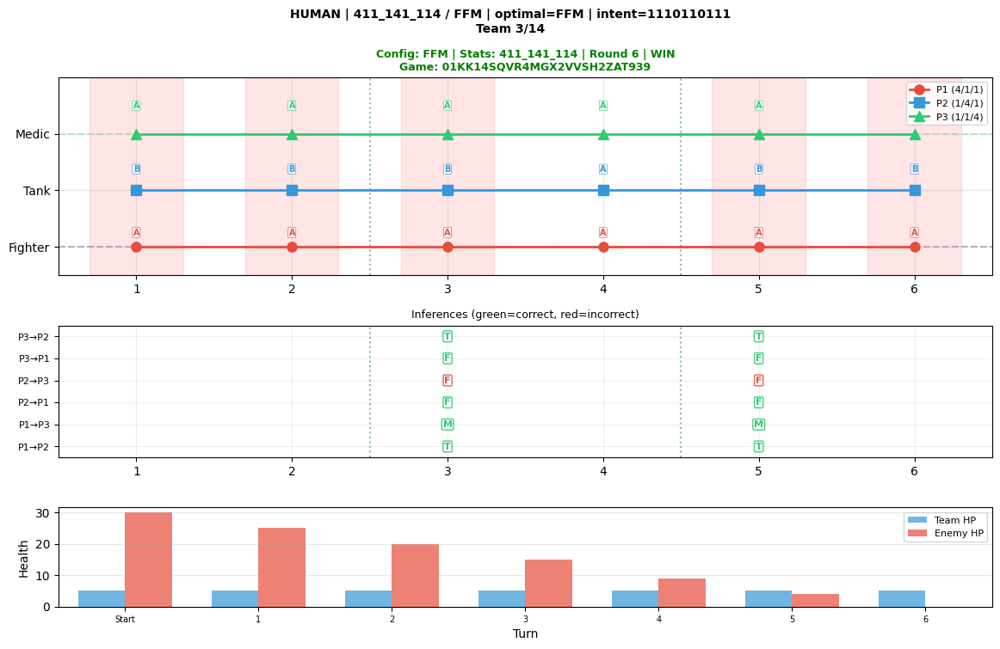

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


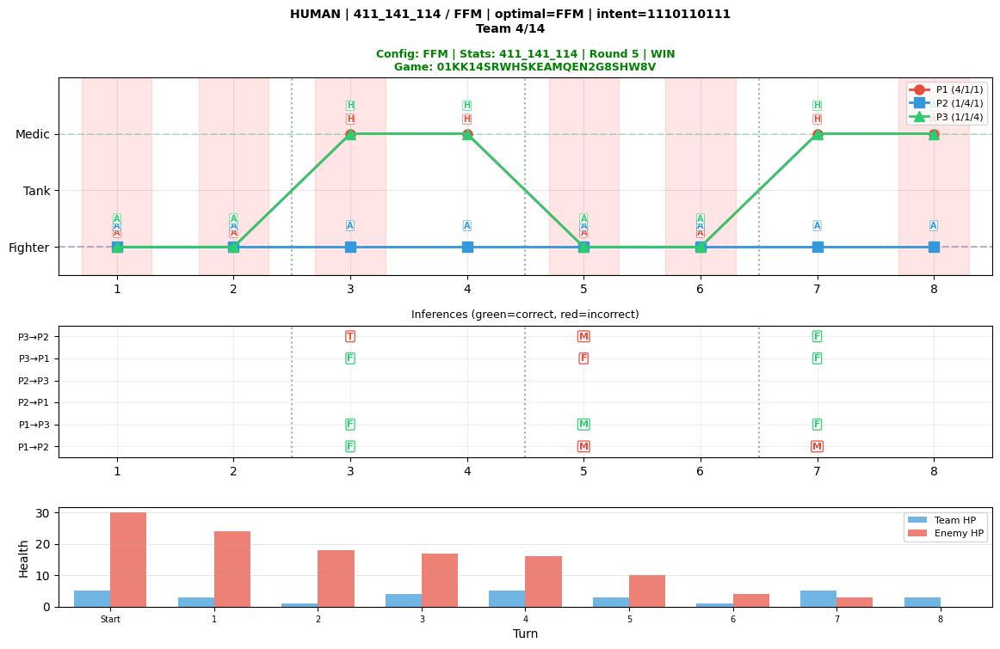

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


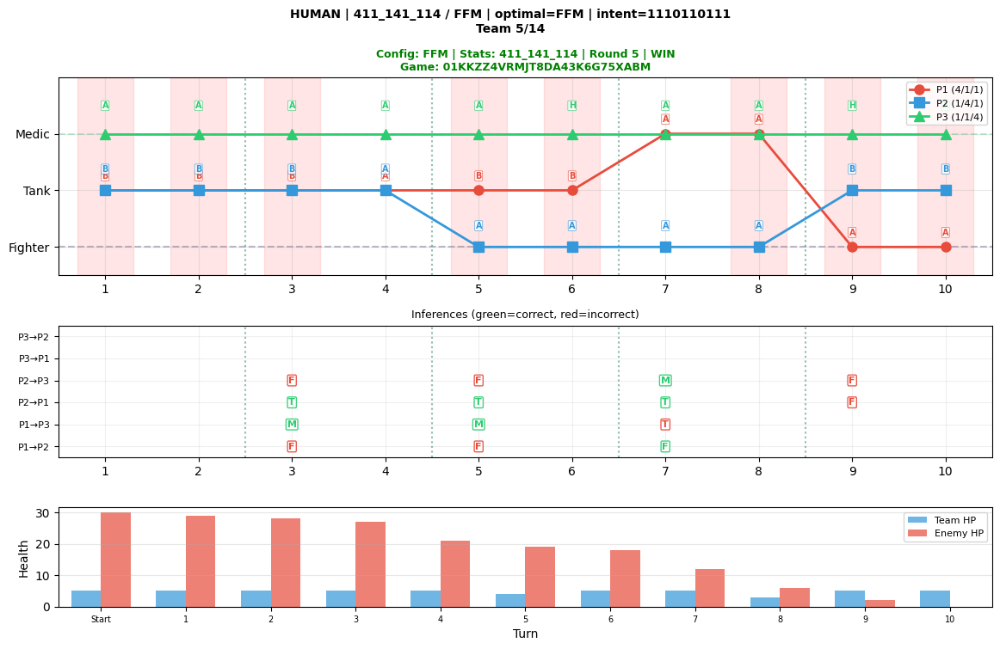

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


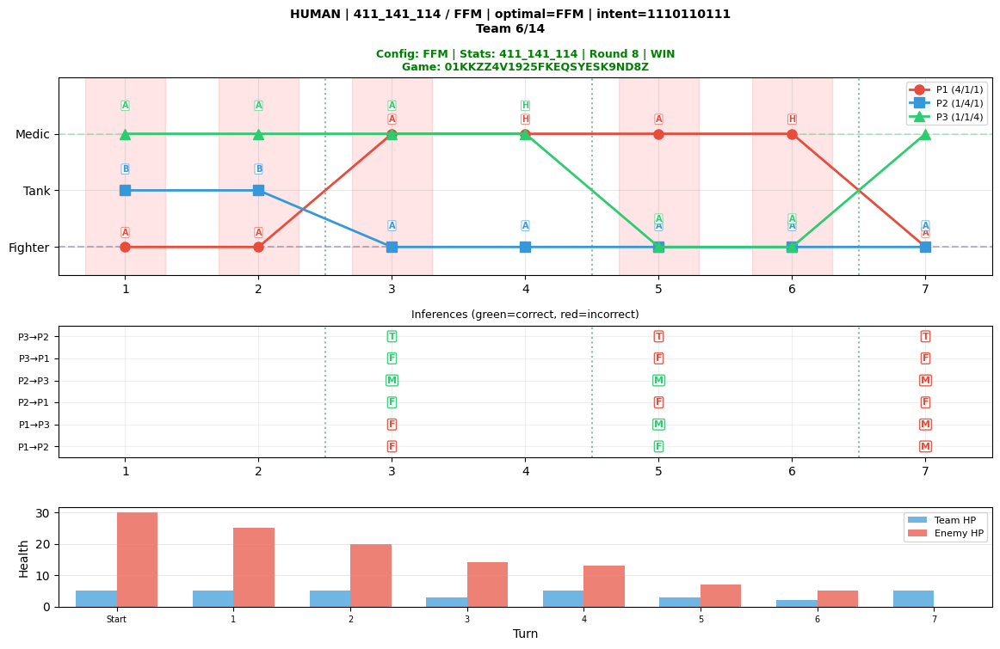

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


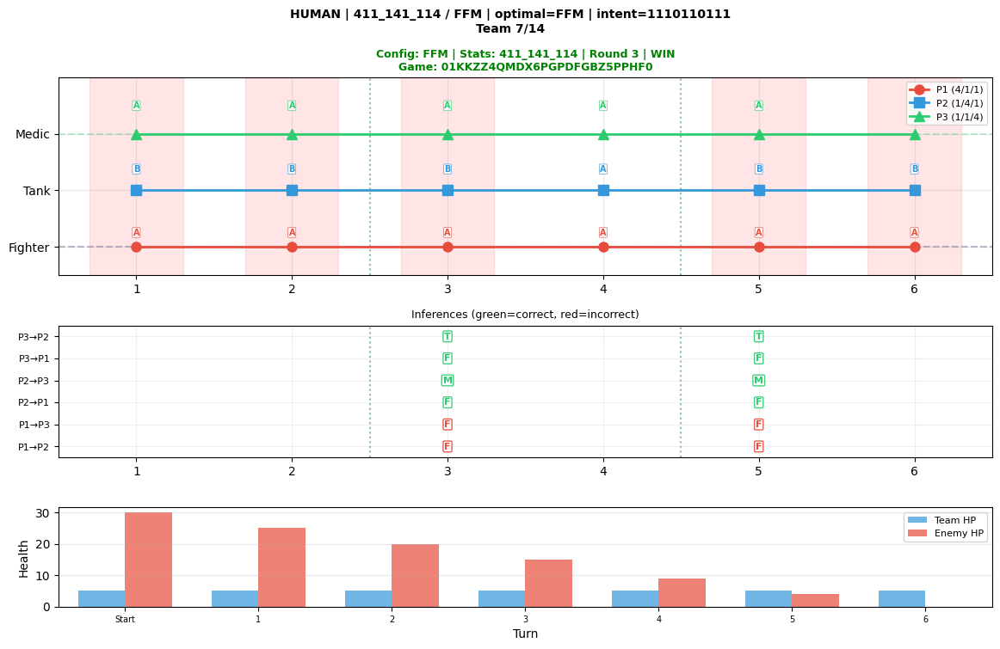

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


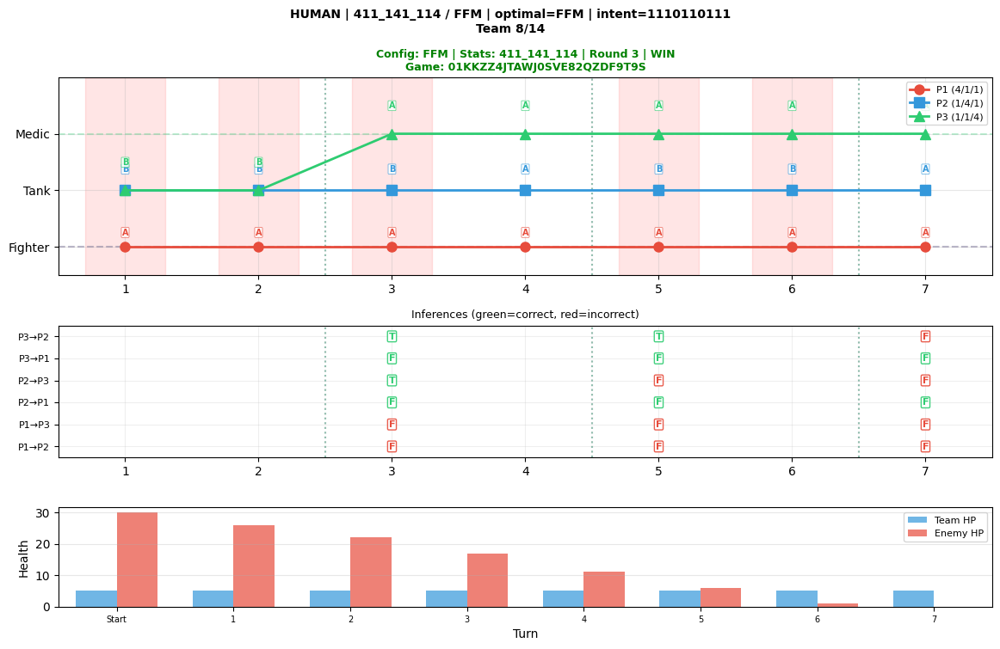

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


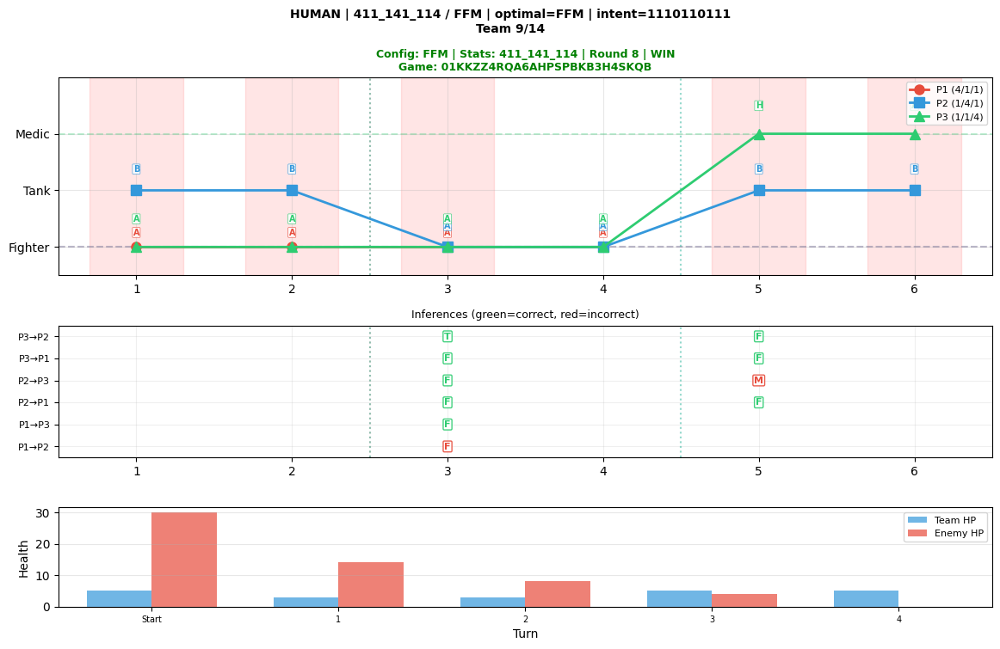

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


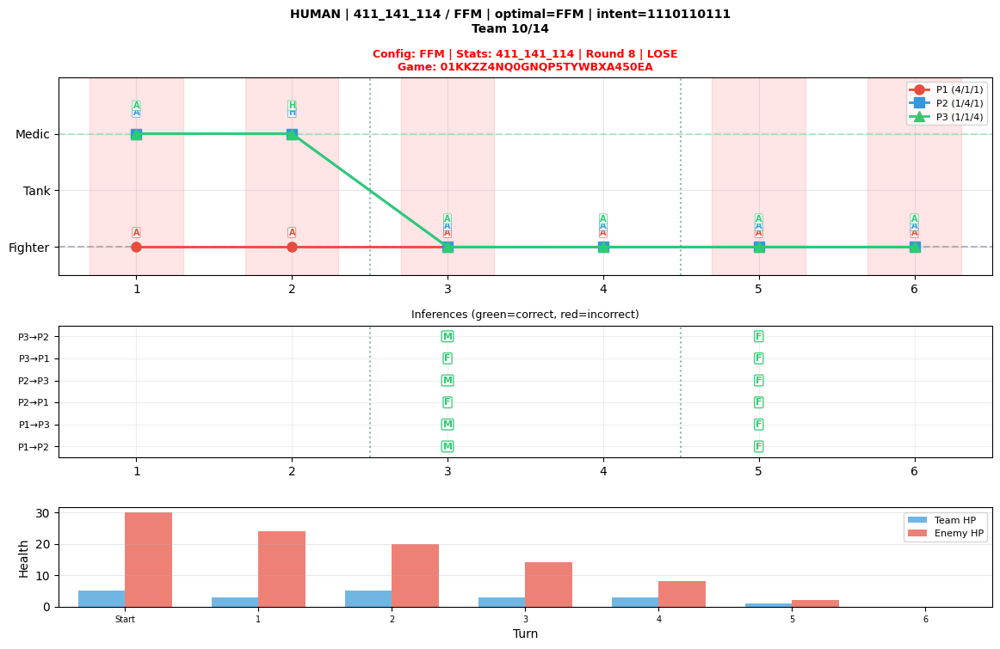

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


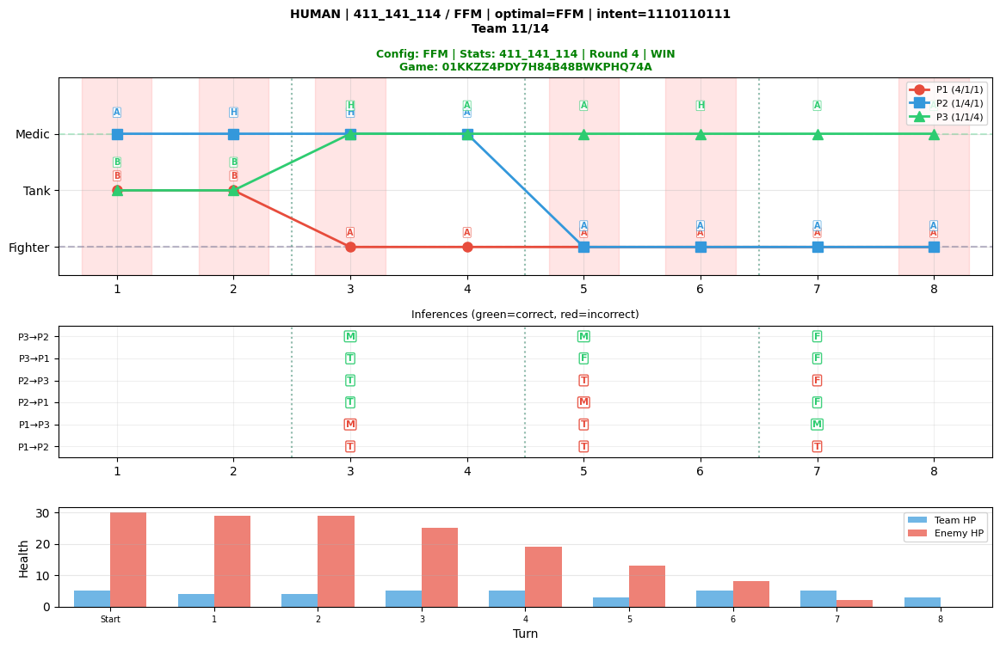

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


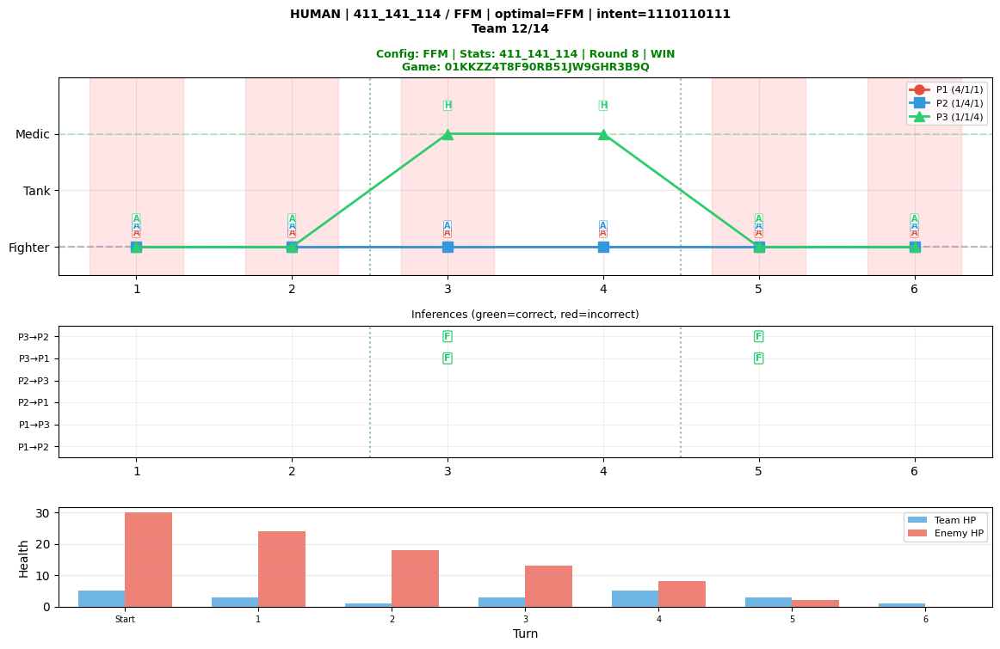

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


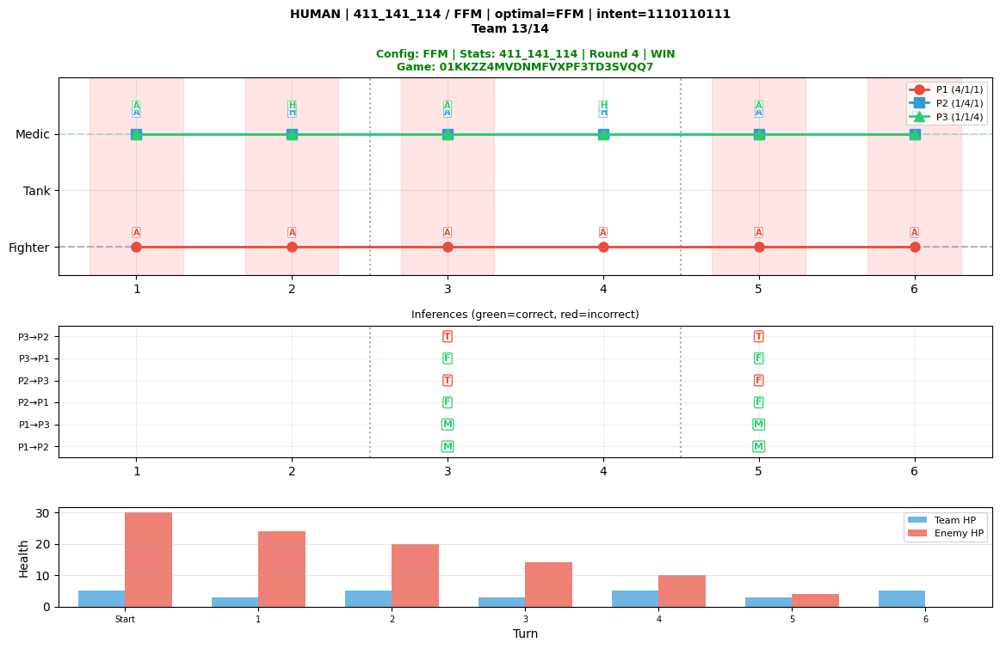

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


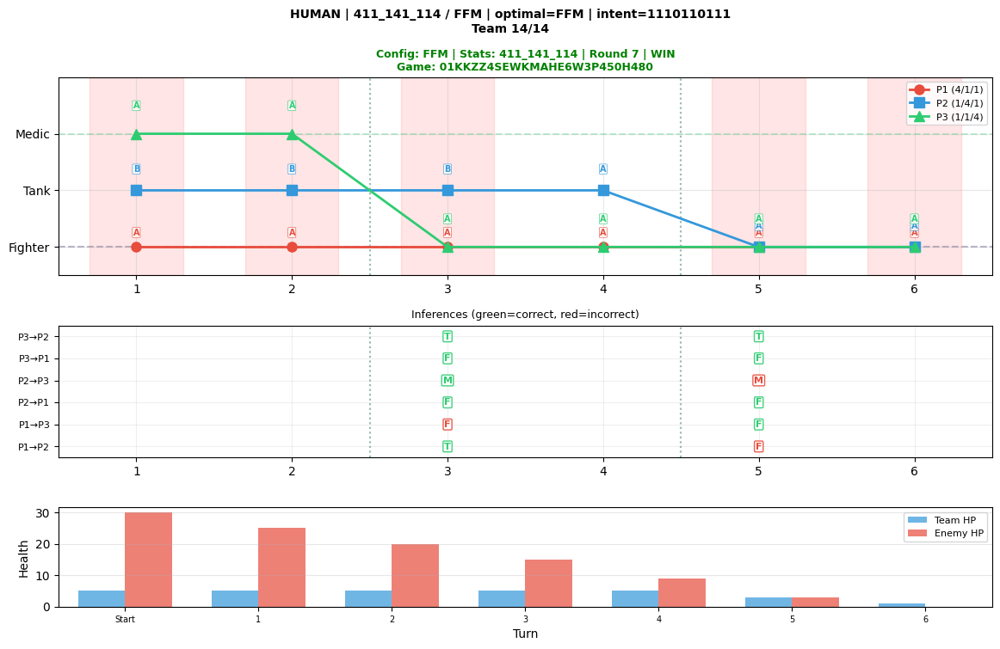

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



411_141_114 / FTF: 14 teams
  Win rate: 11/14 (79%)


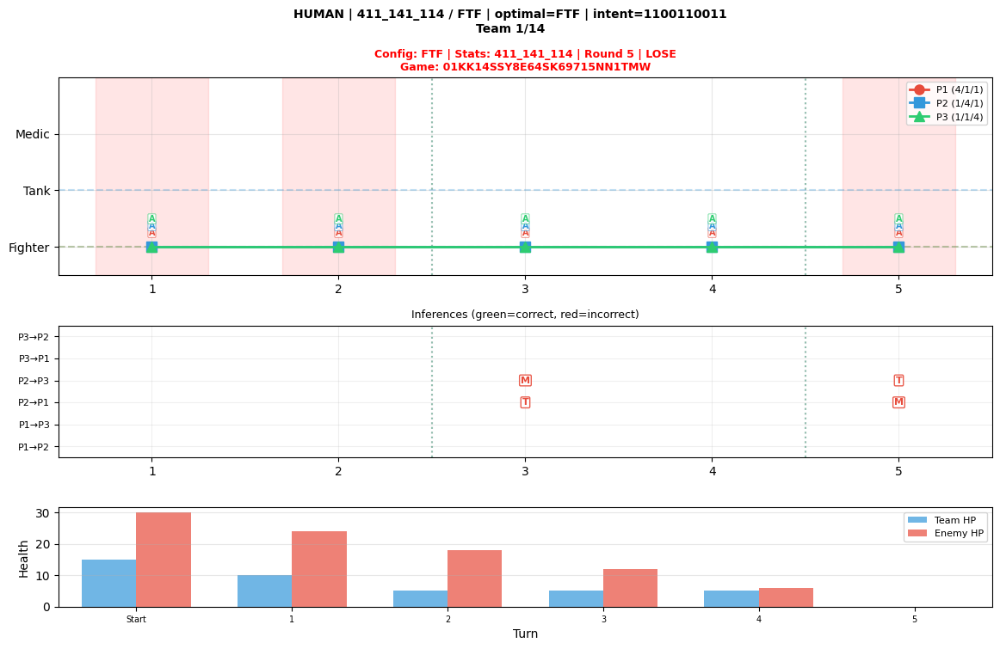

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


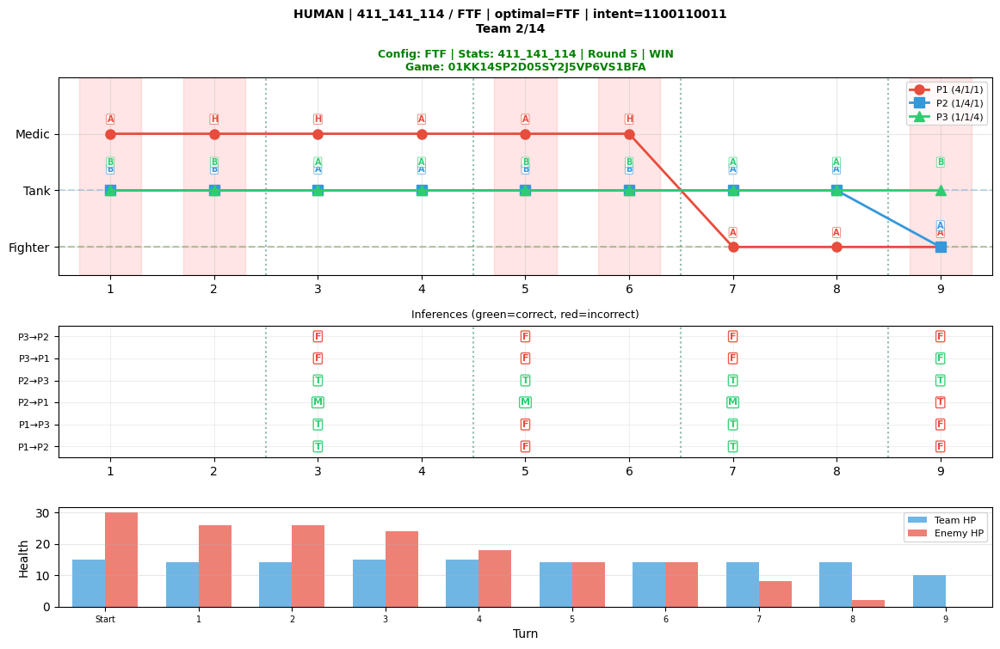

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


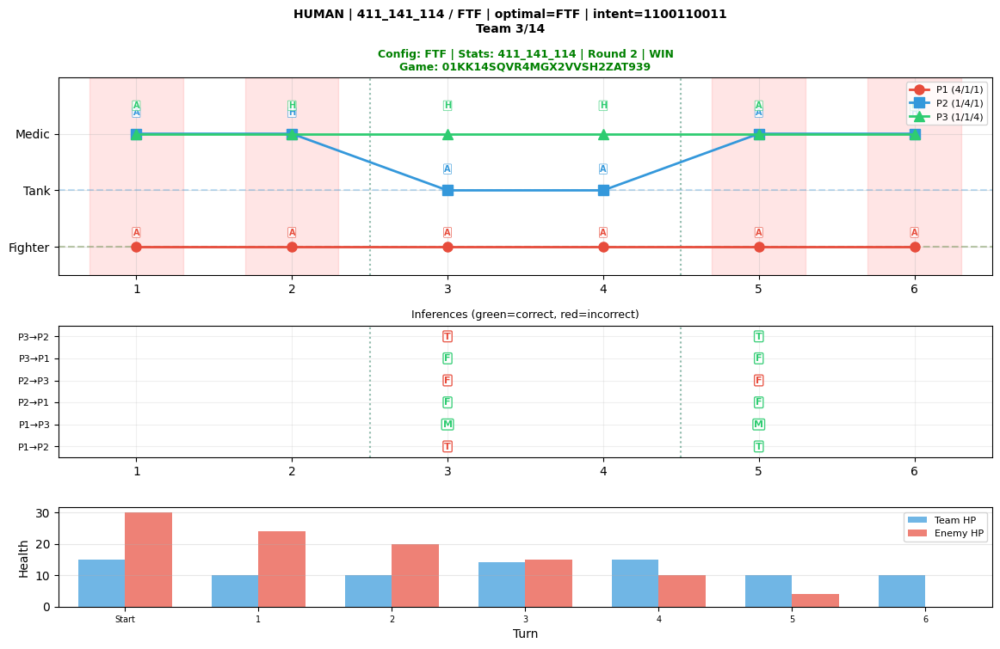

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


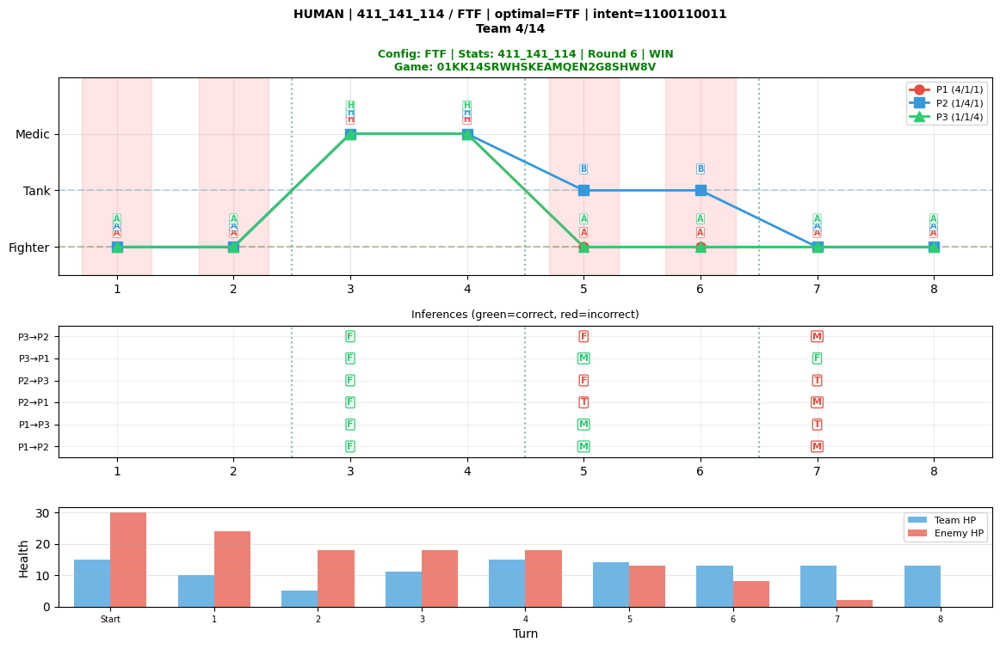

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


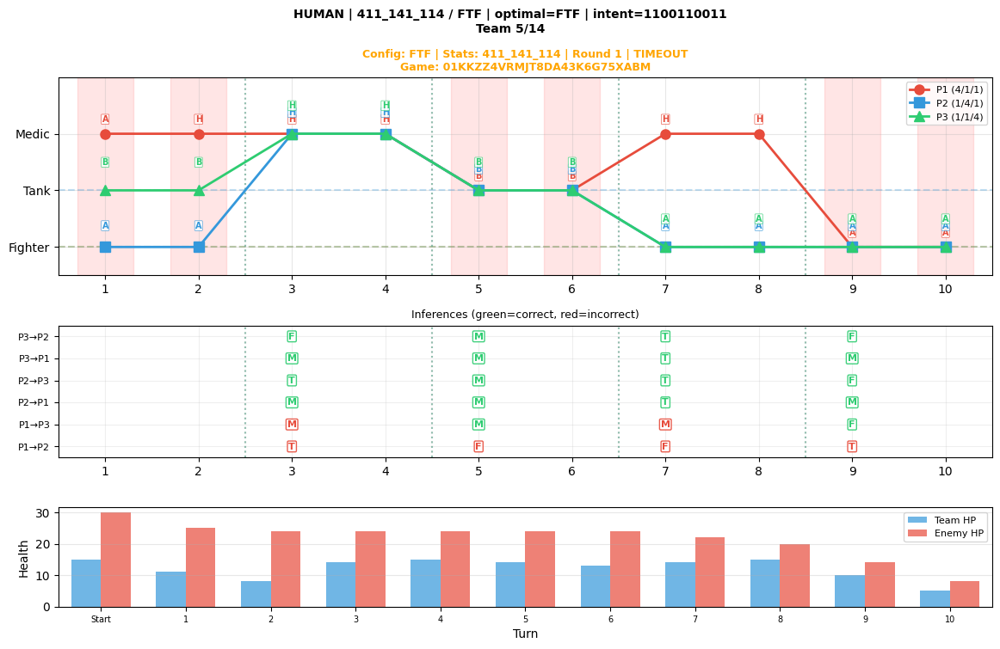

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


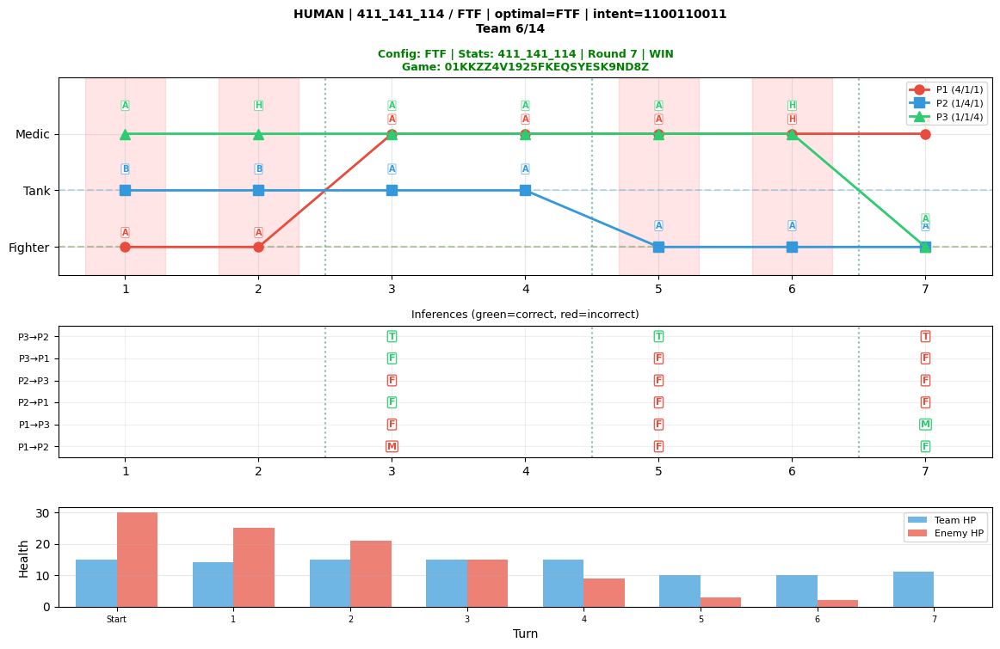

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


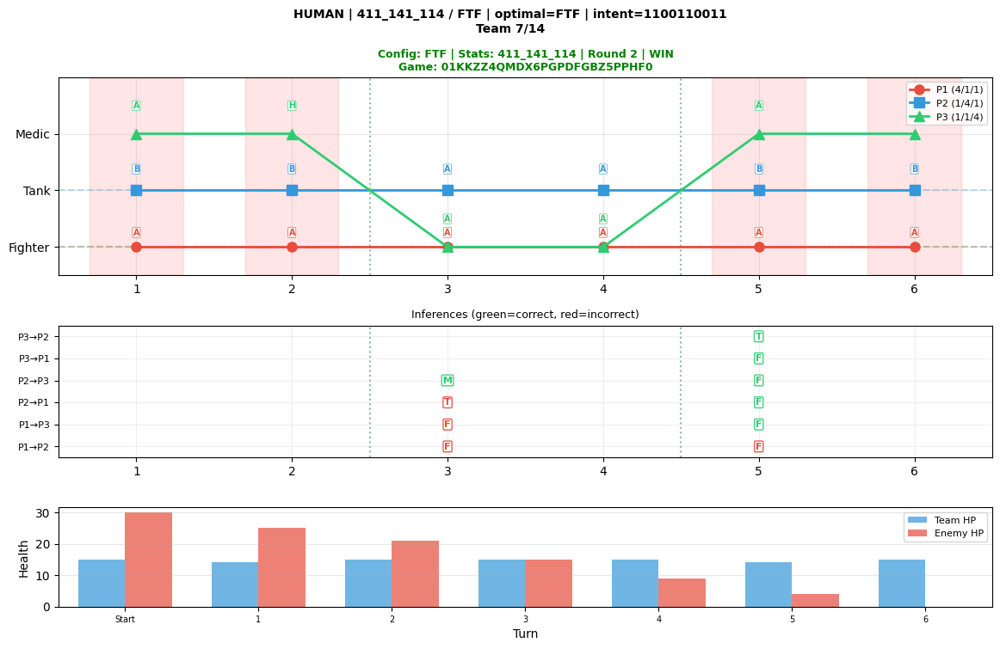

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


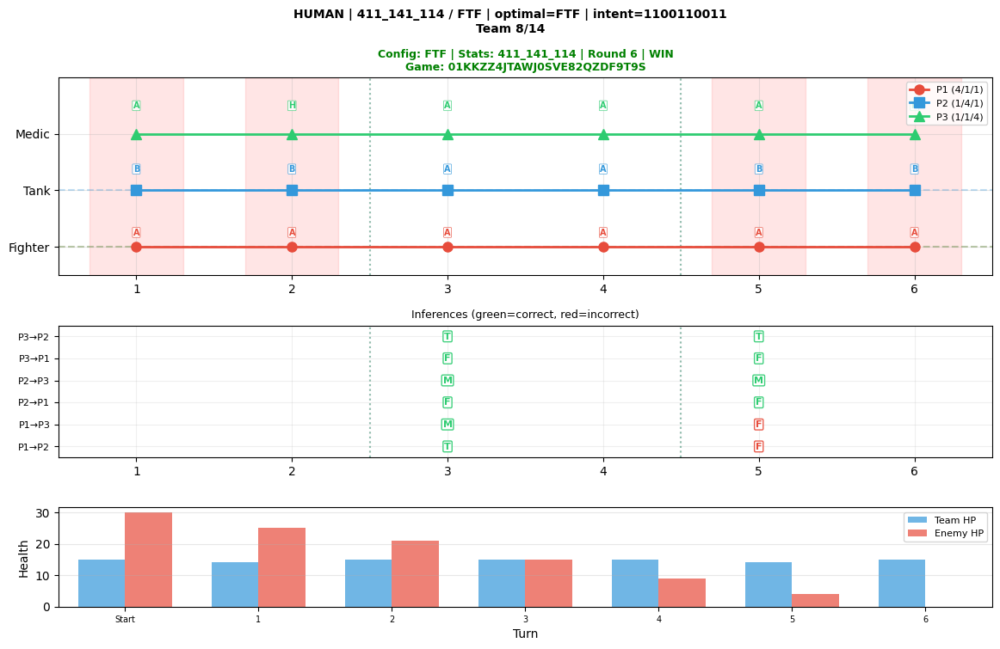

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


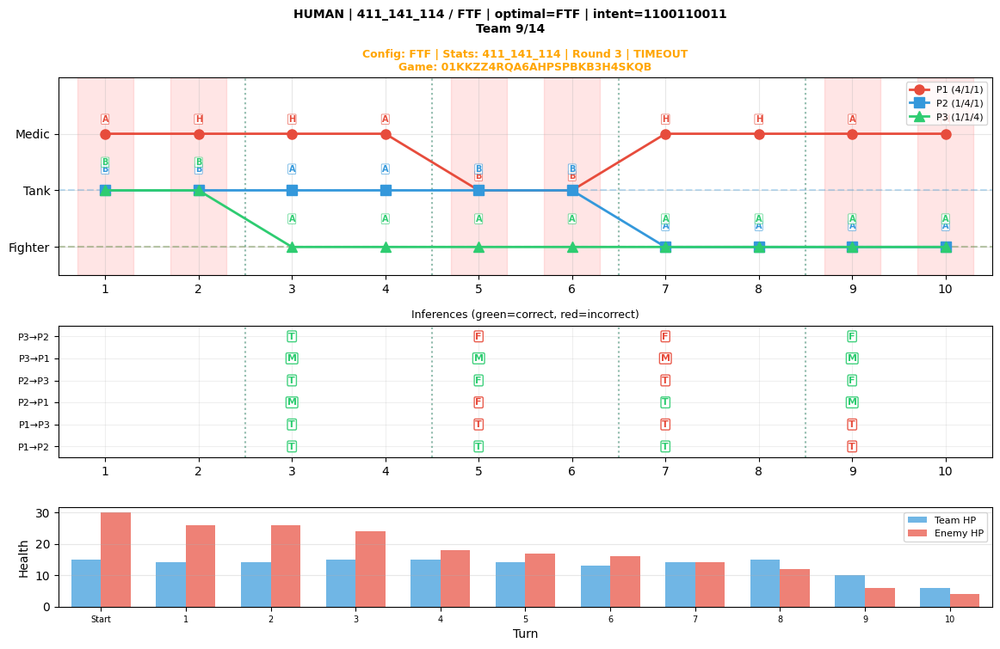

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


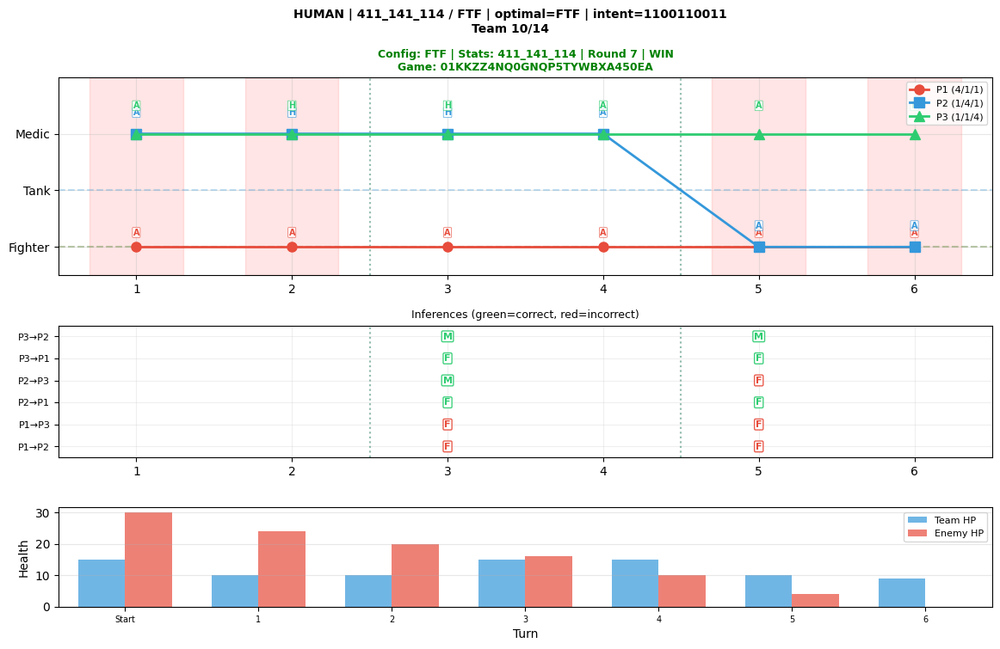

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


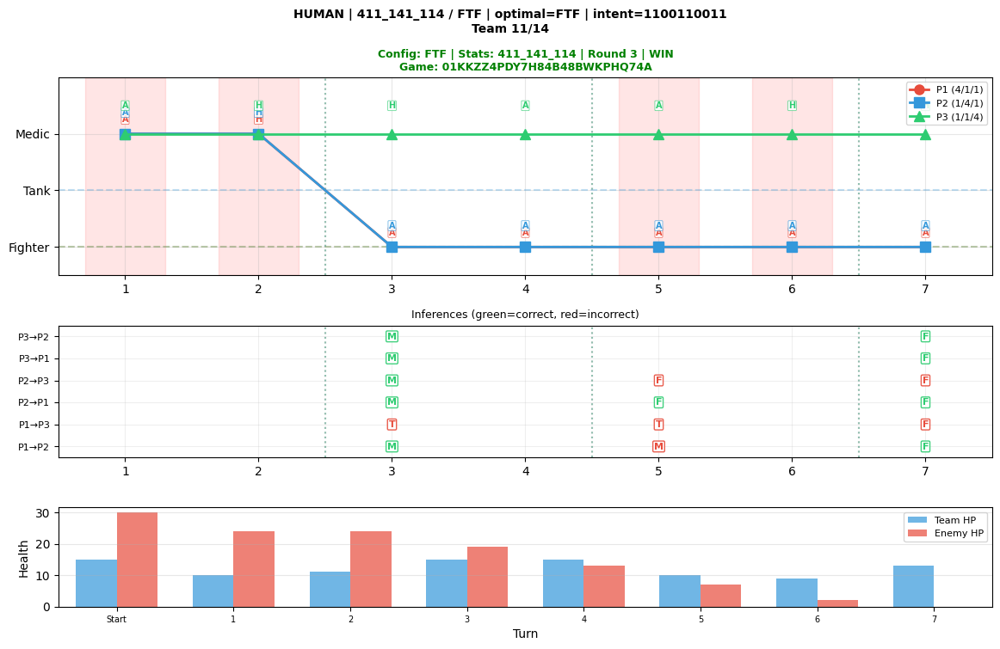

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


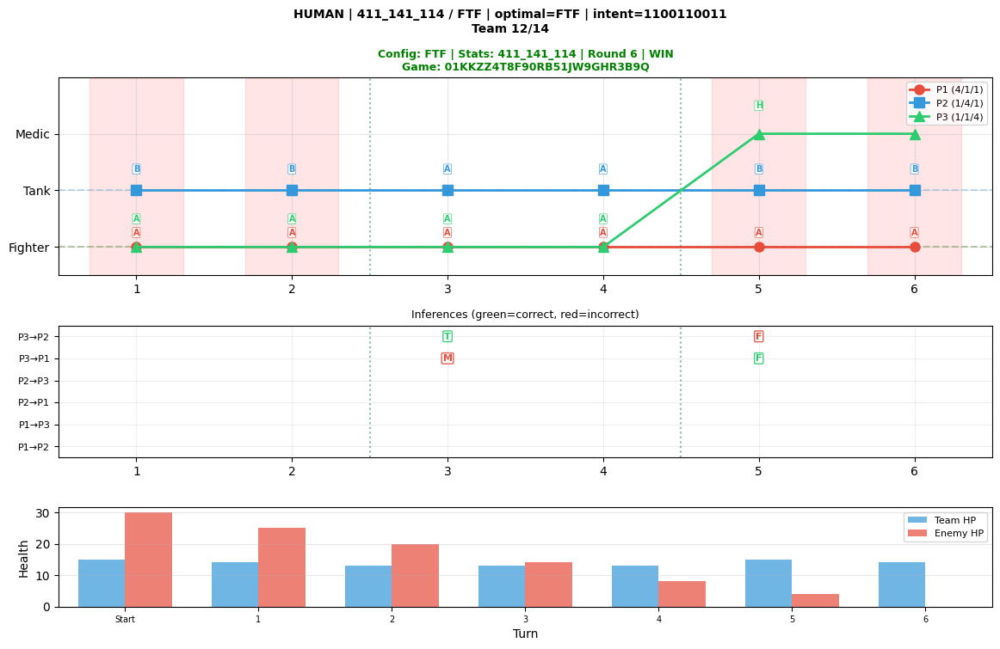

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


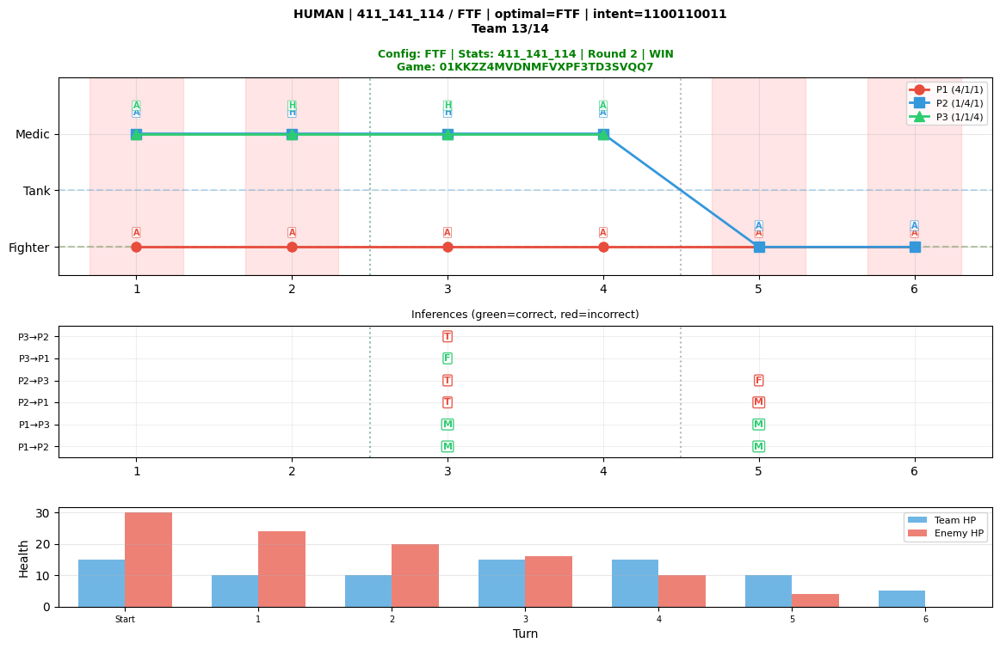

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


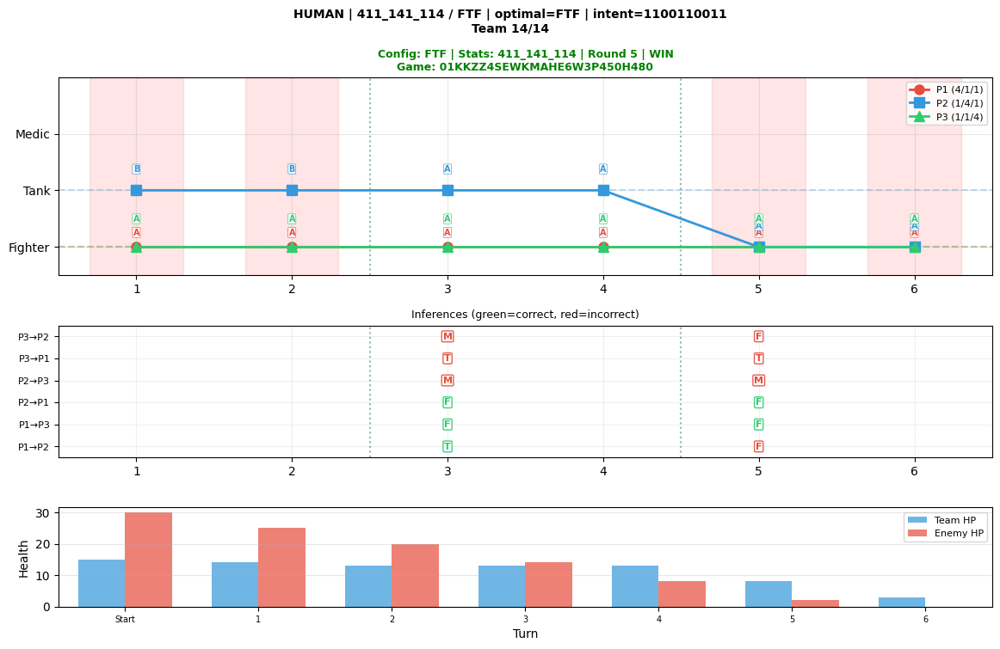

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



411_141_114 / FTM: 14 teams
  Win rate: 7/14 (50%)


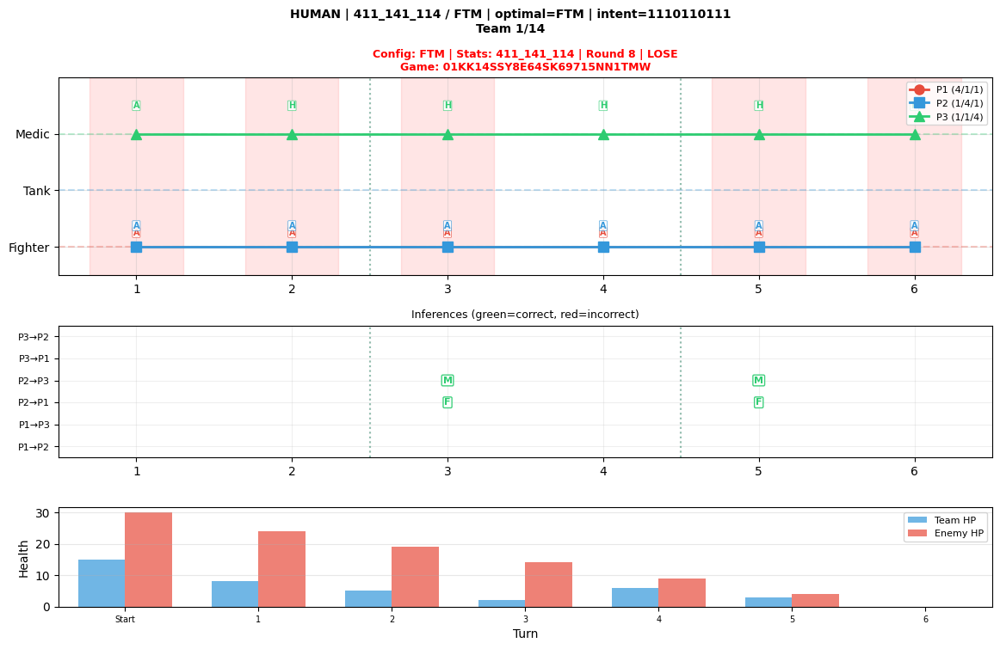

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


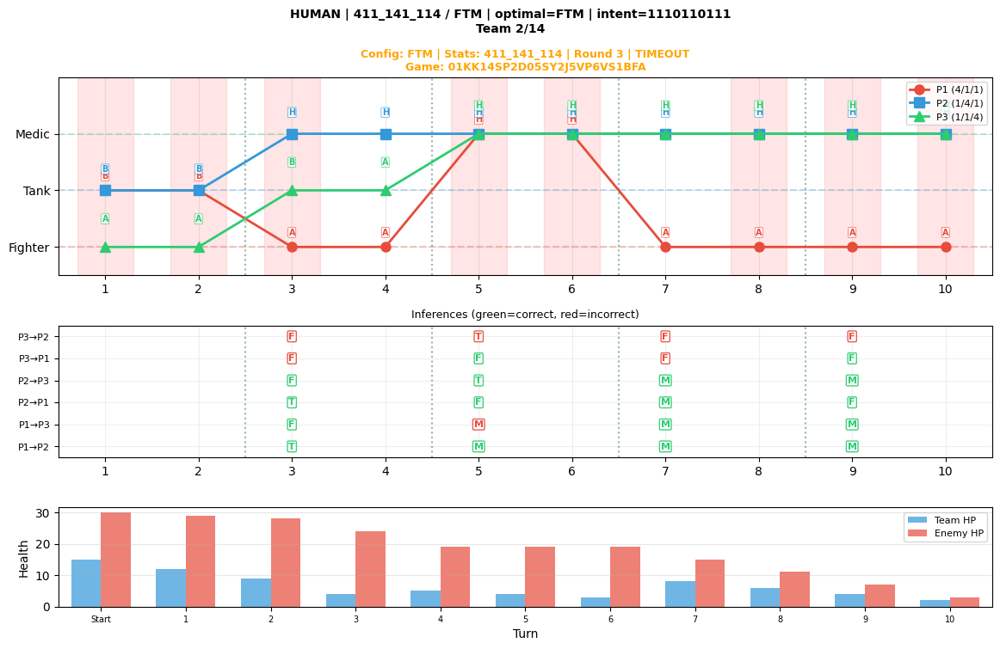

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


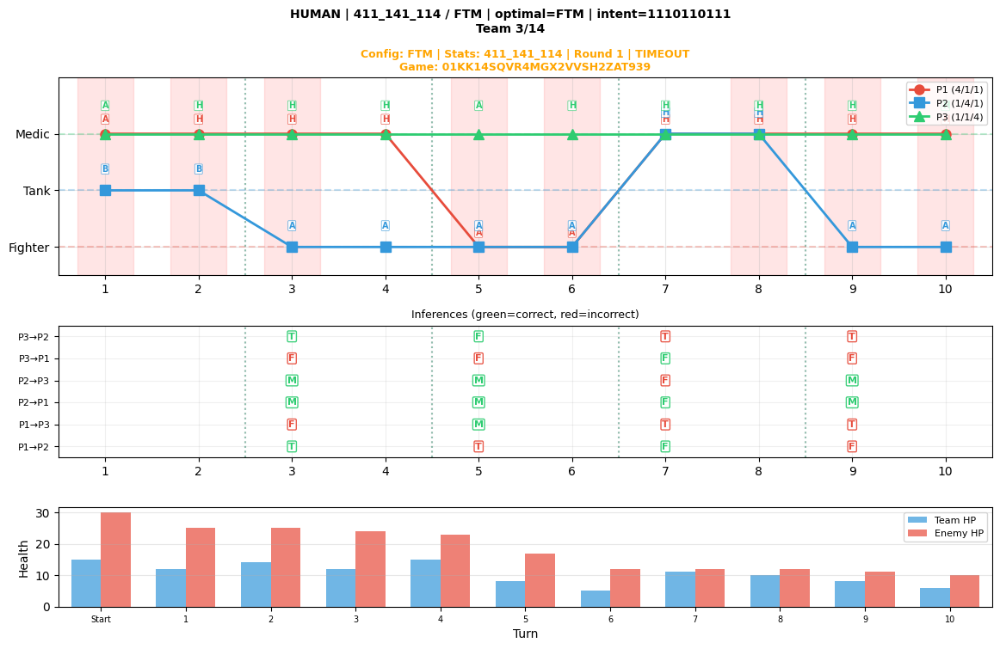

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


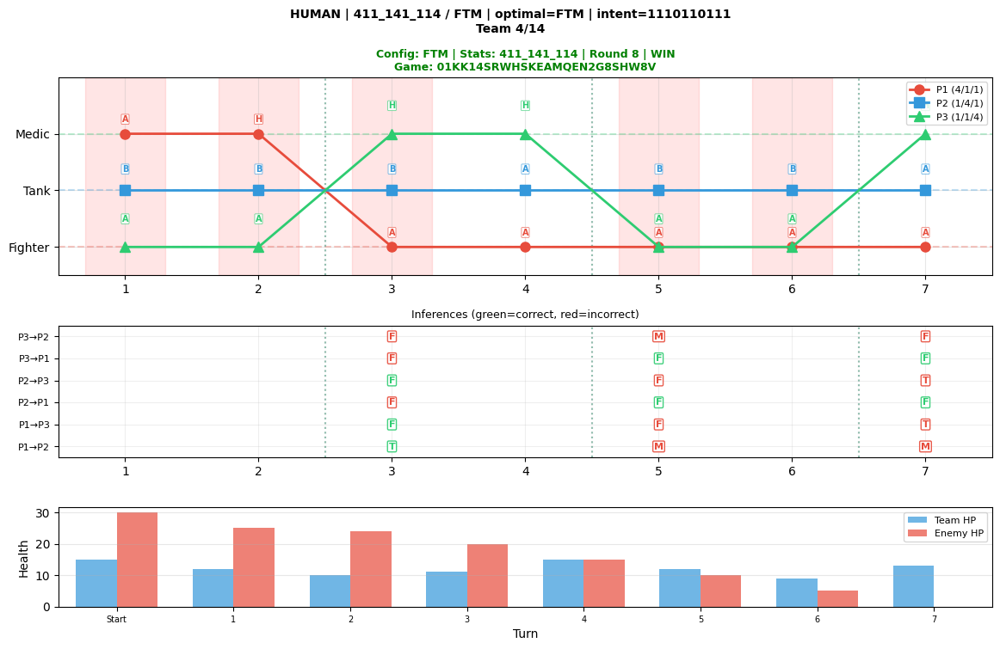

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


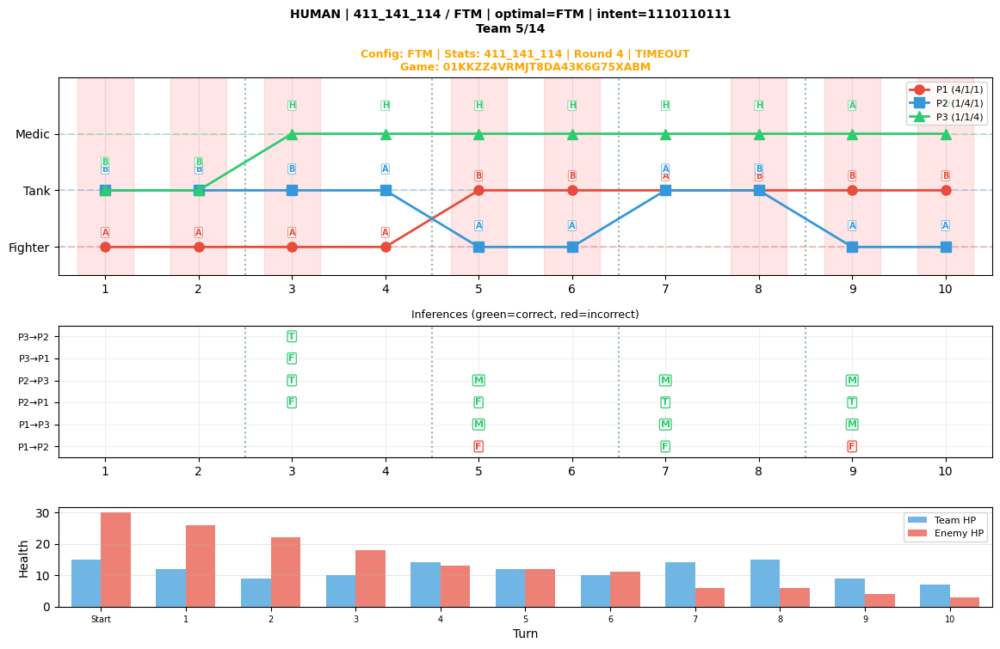

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


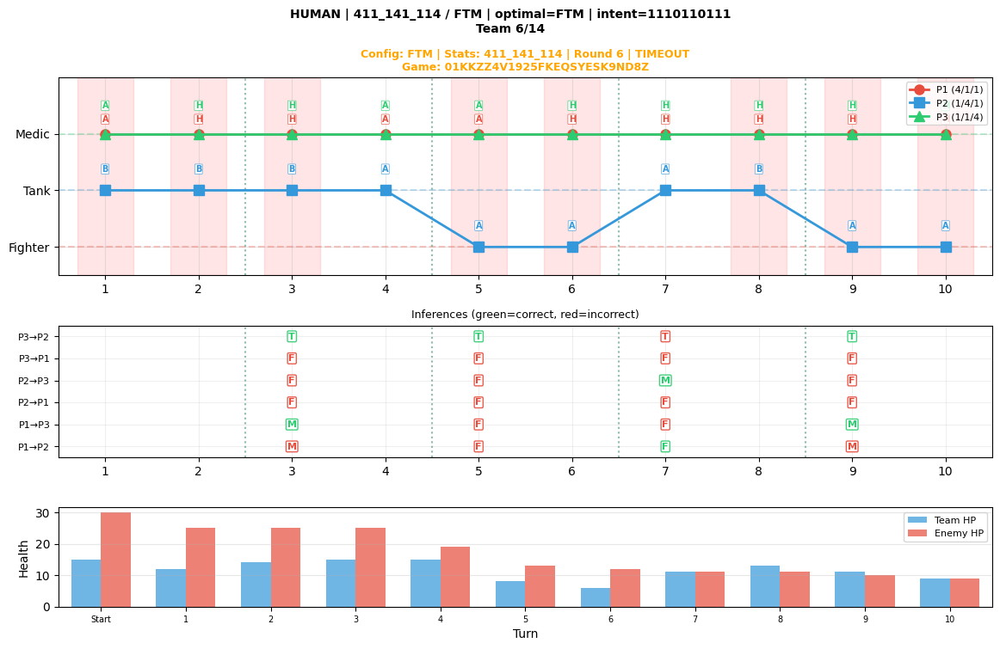

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


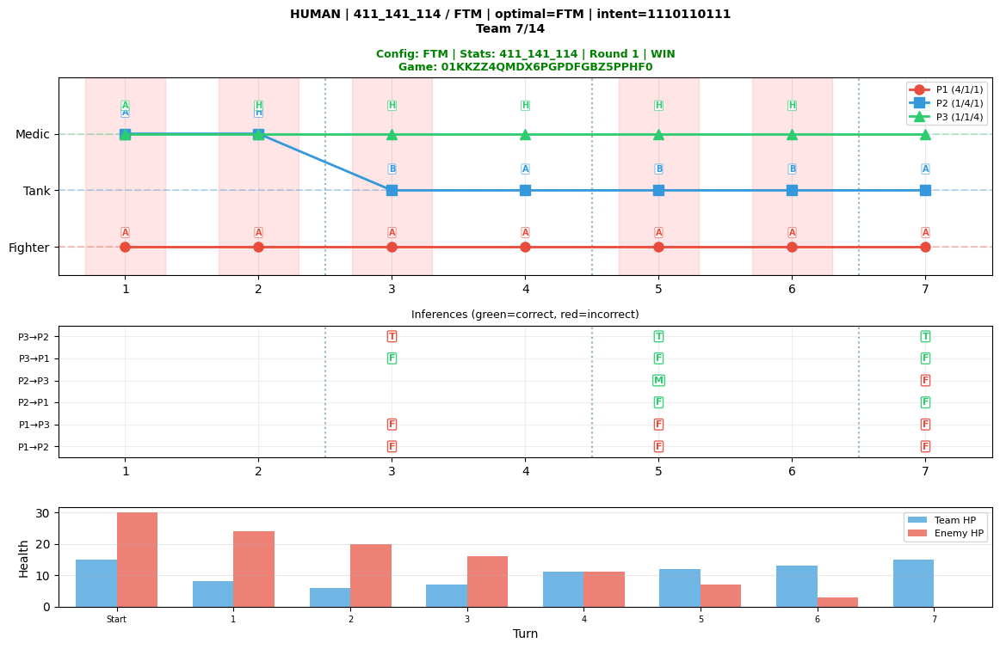

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


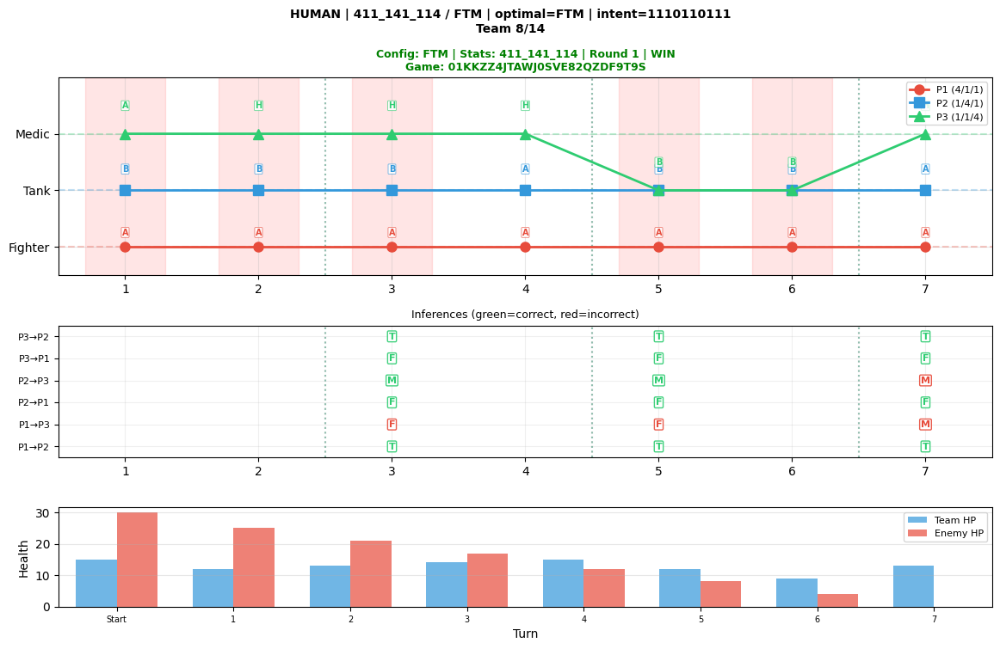

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


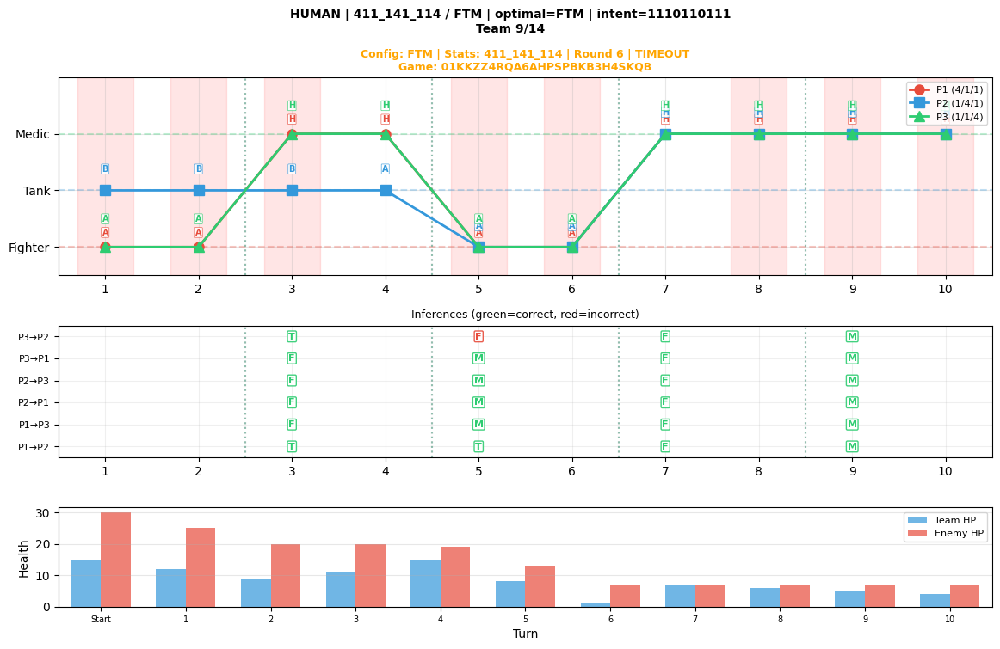

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


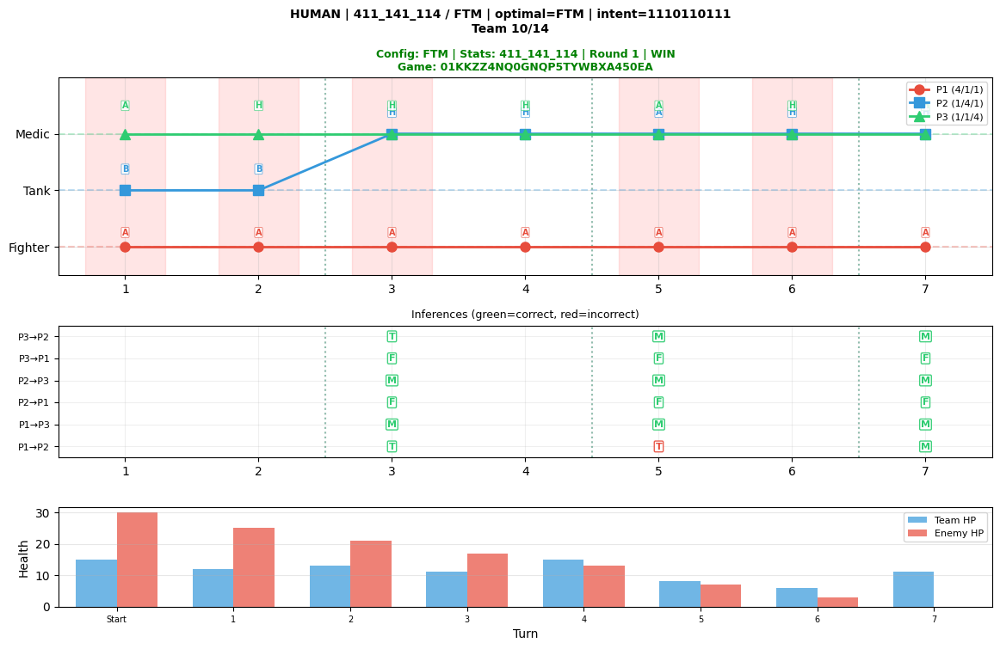

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


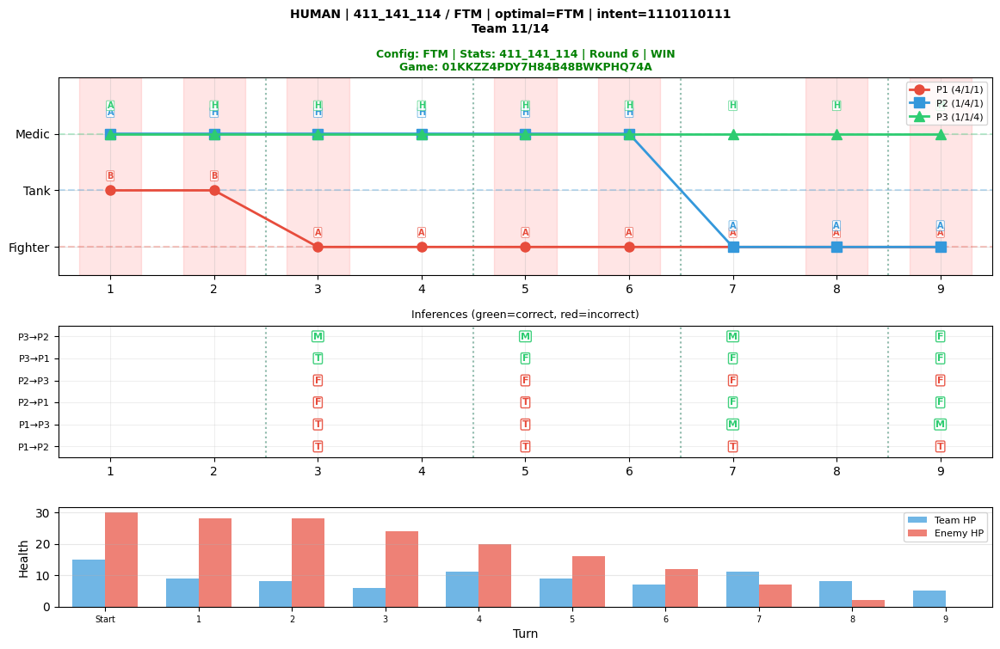

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


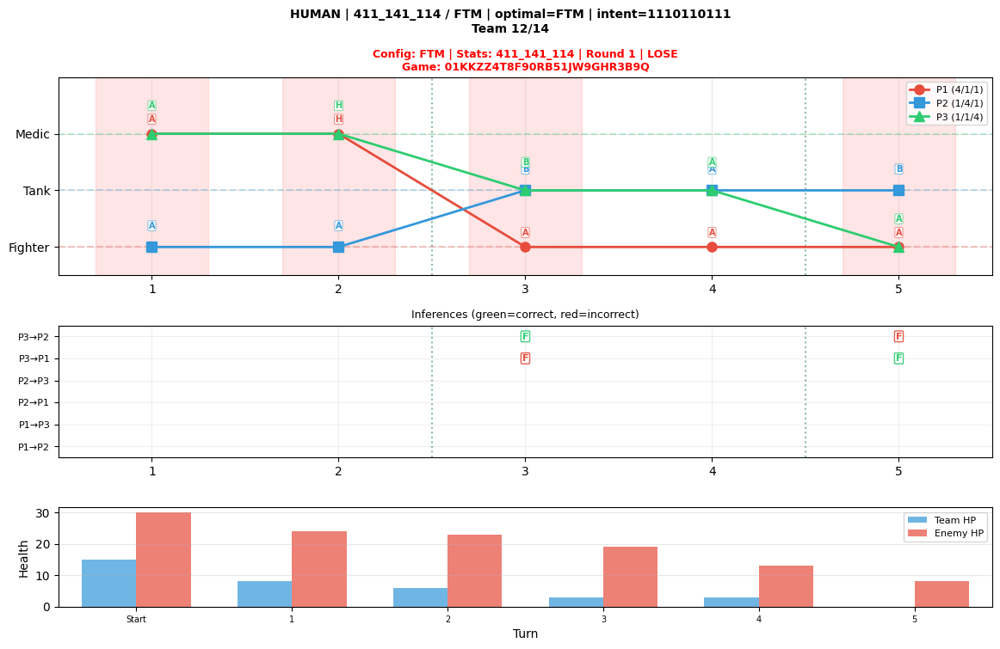

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


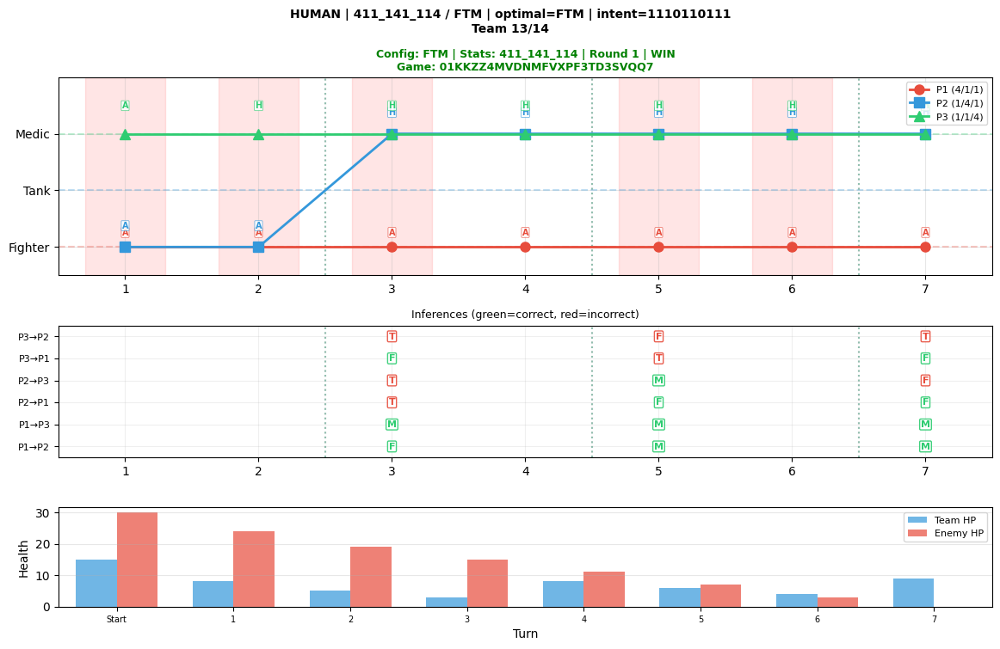

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


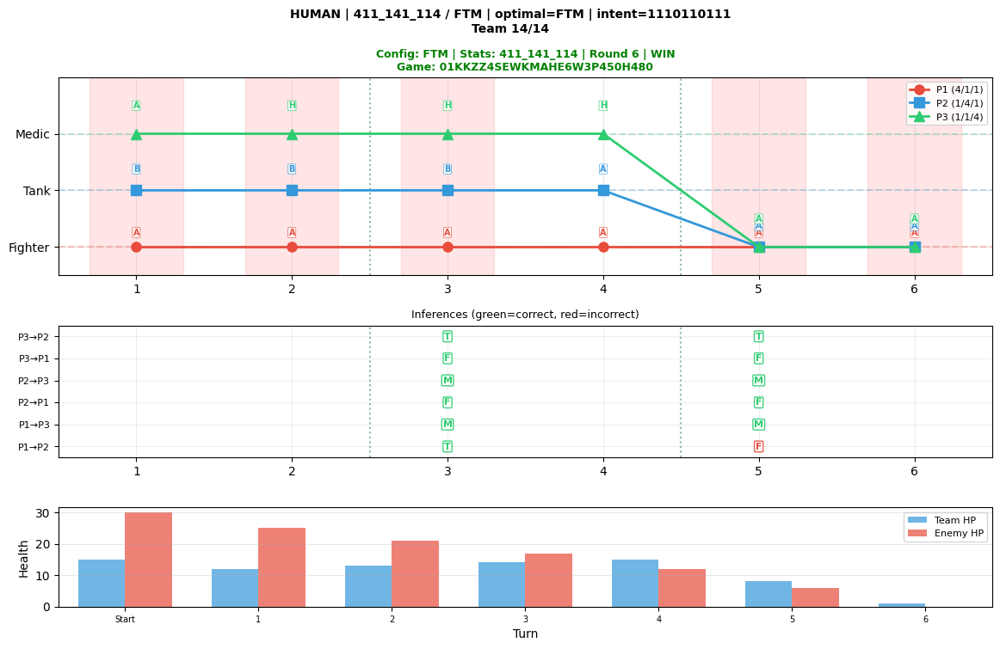

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



411_222_222 / FMM: 14 teams
  Win rate: 14/14 (100%)


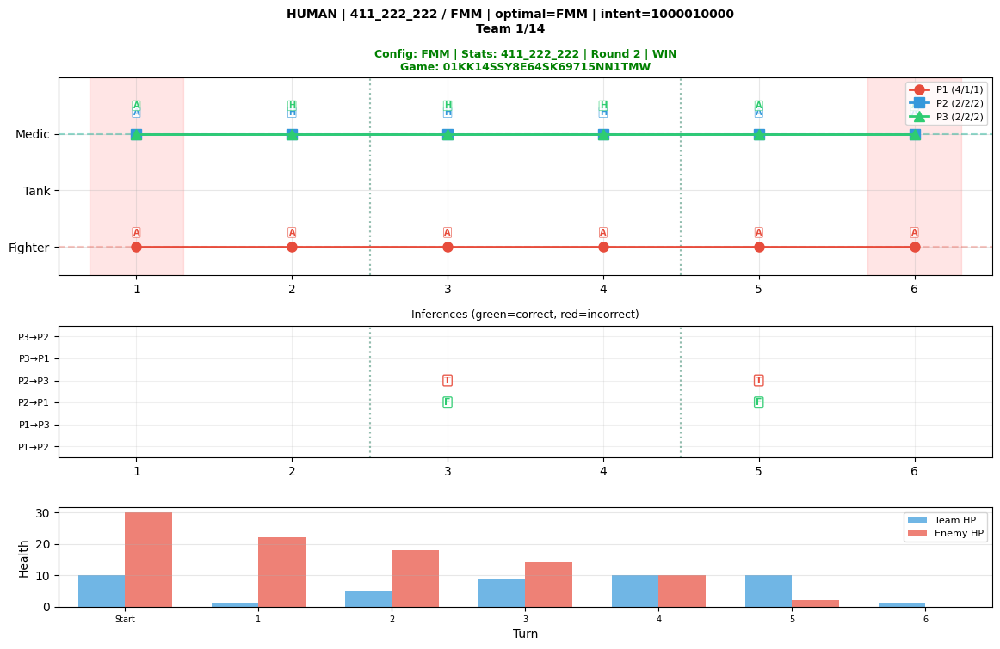

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


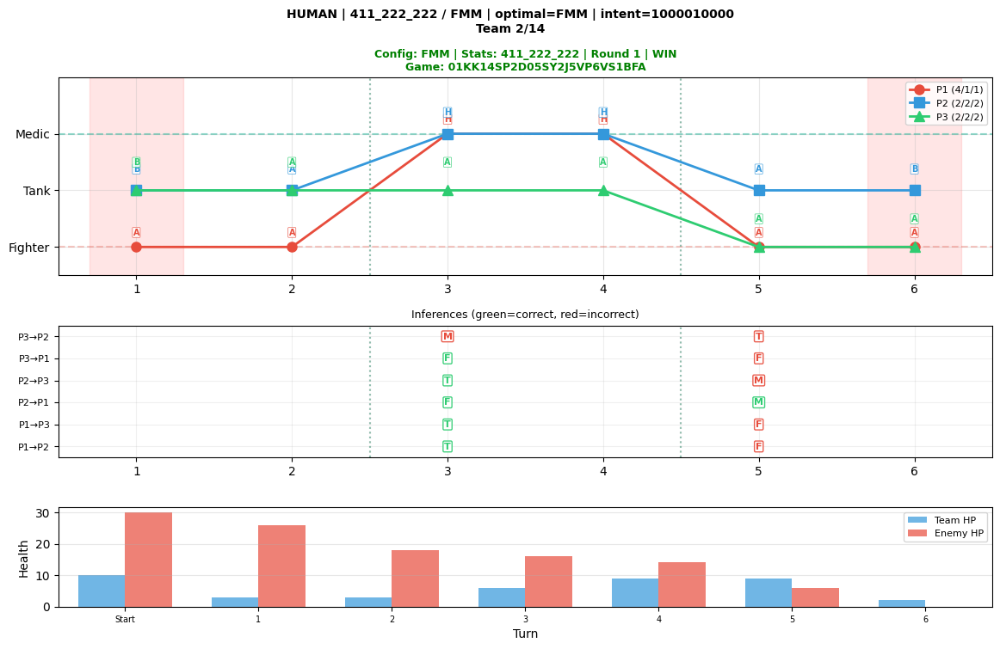

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


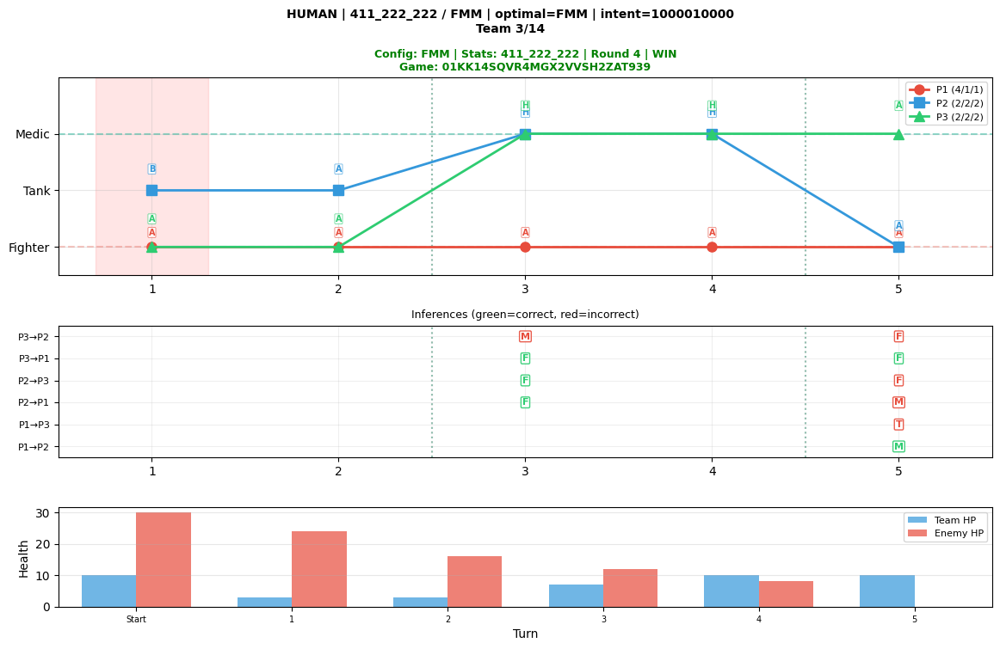

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


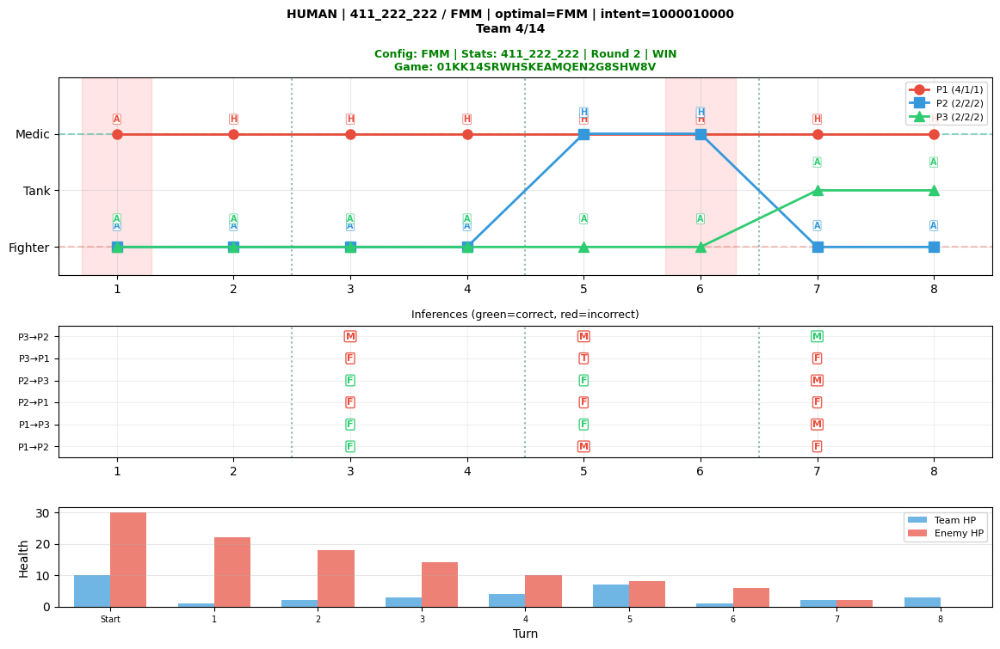

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


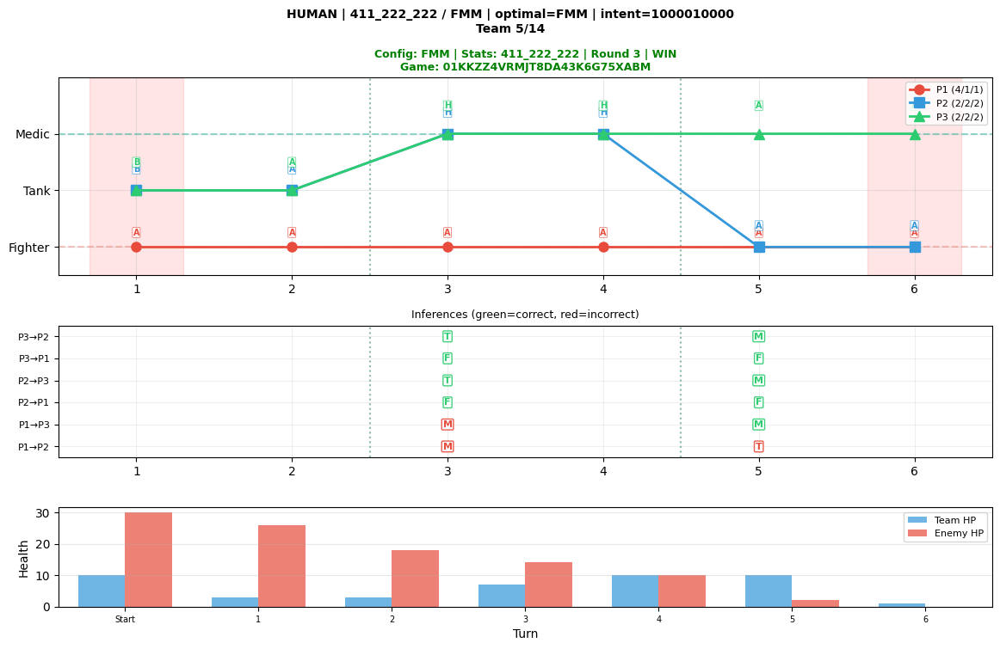

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


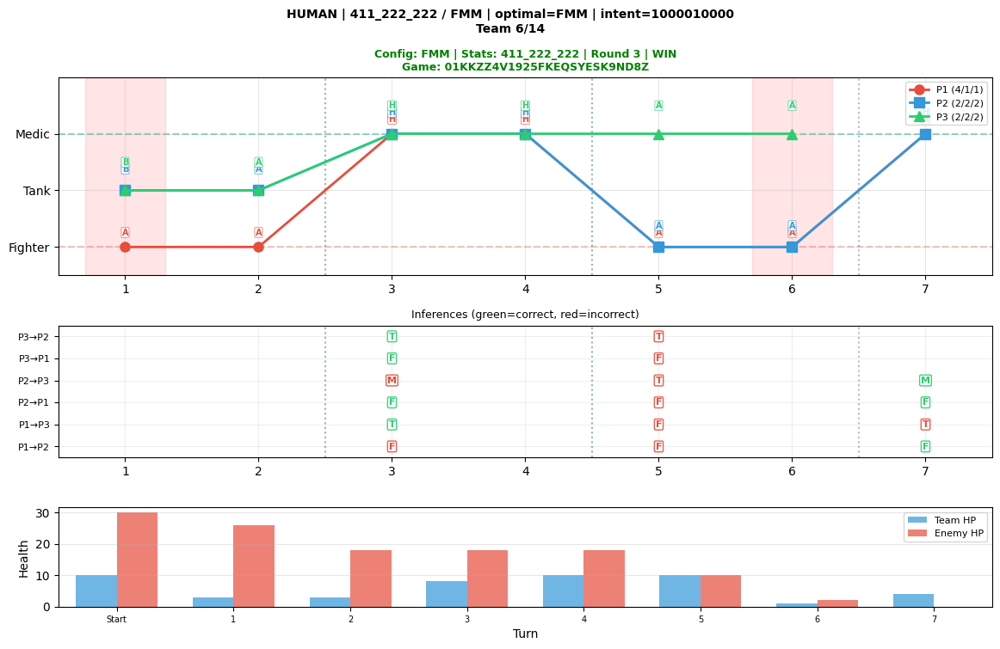

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


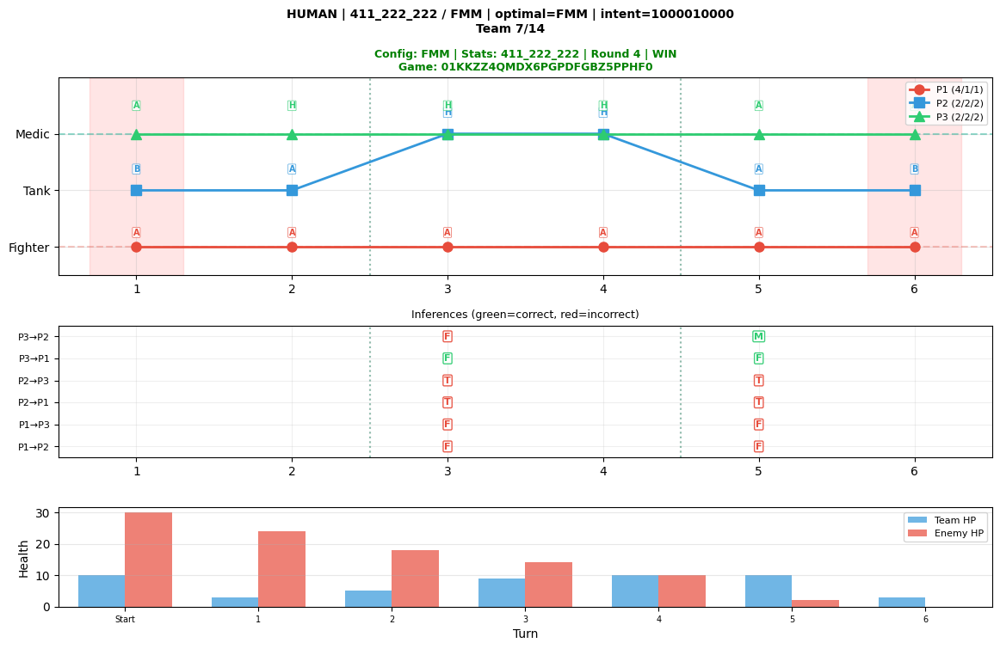

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


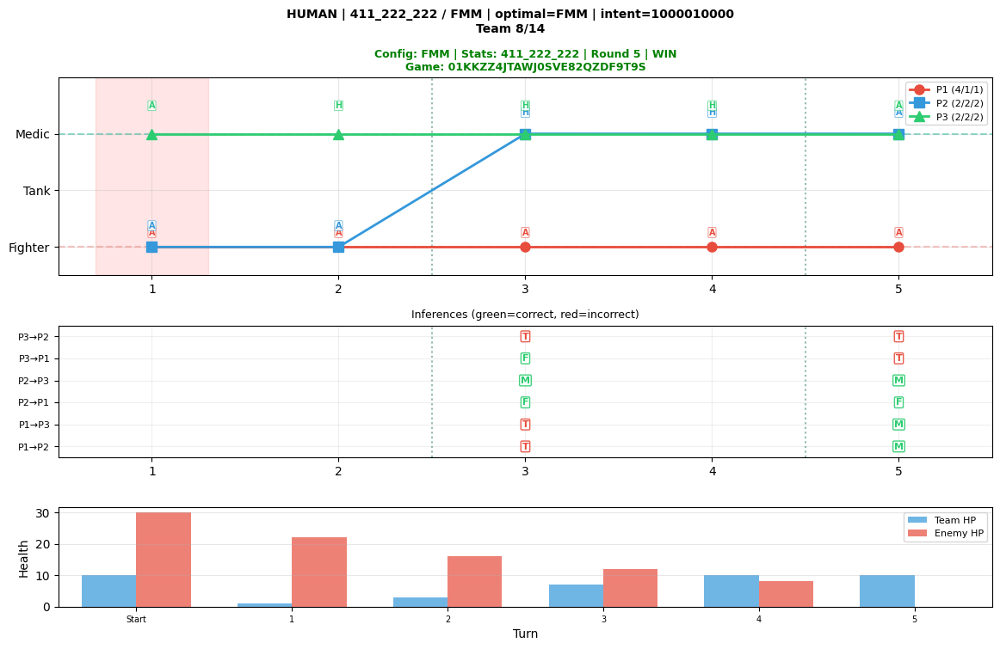

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


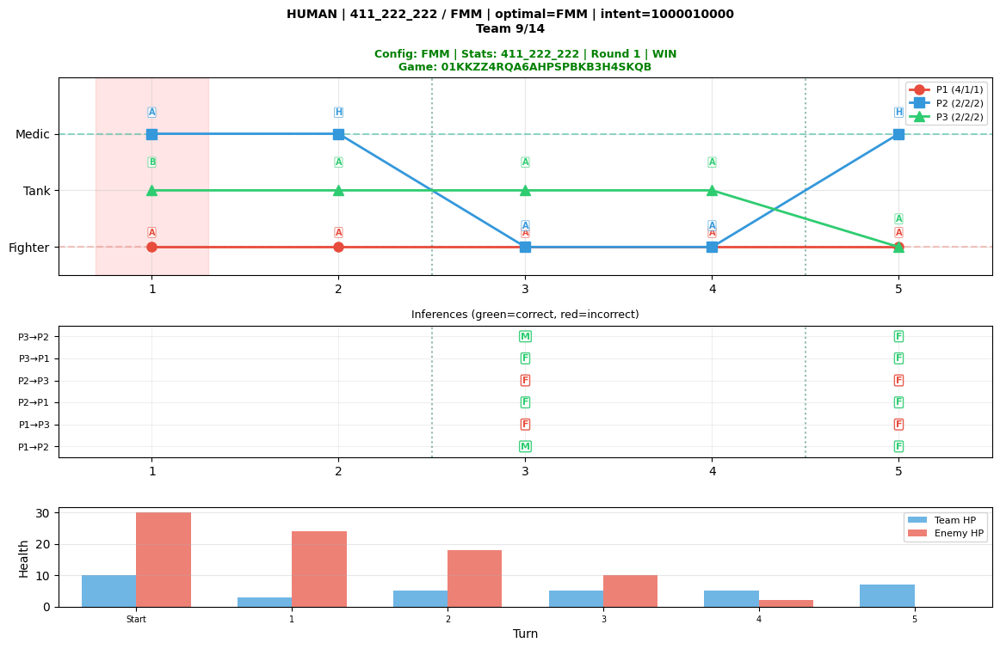

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


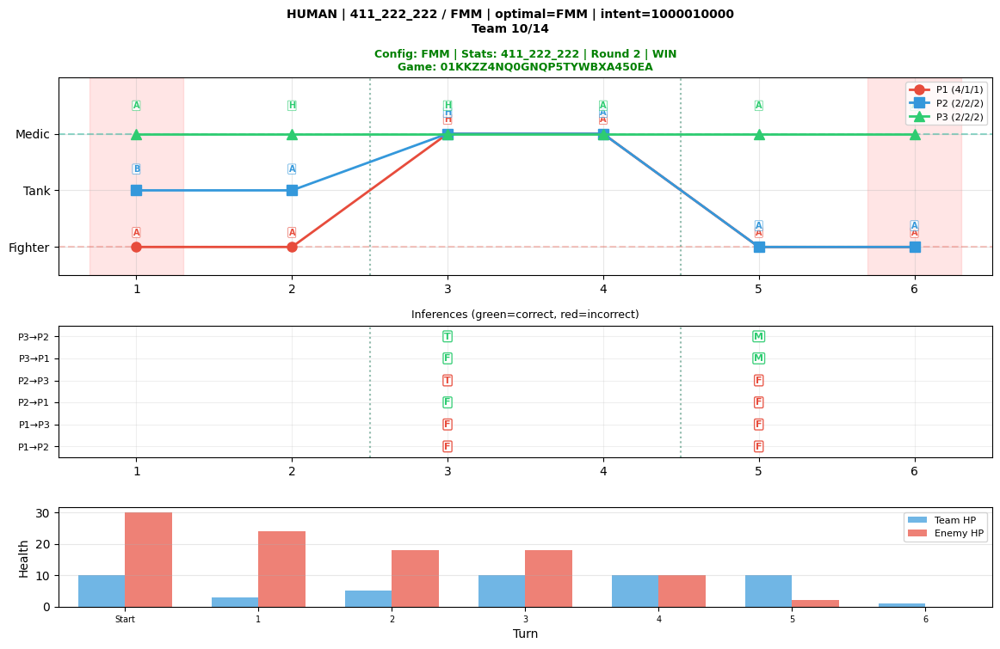

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


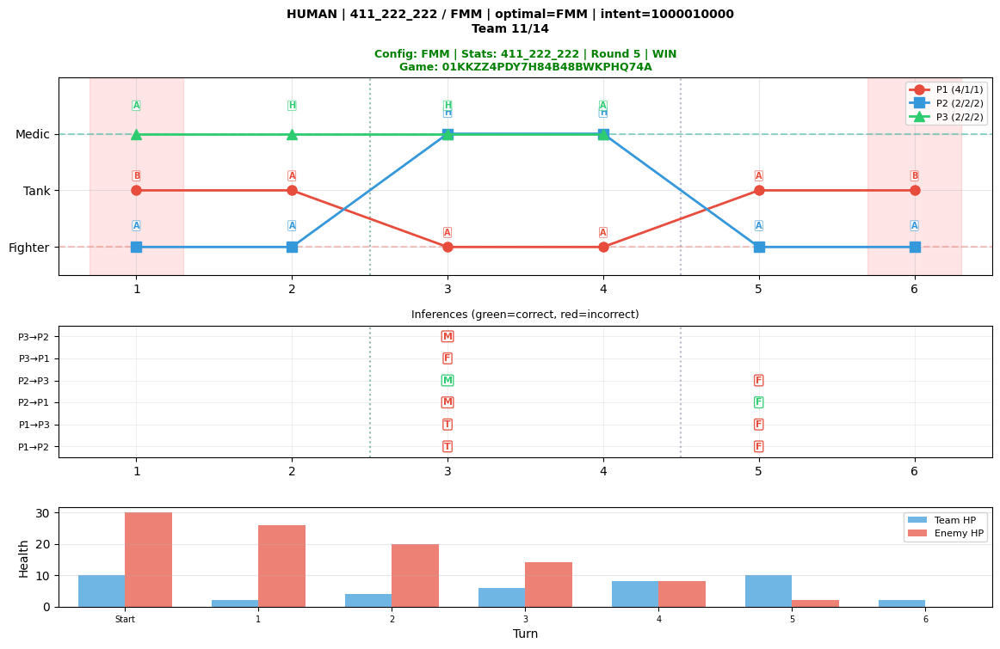

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


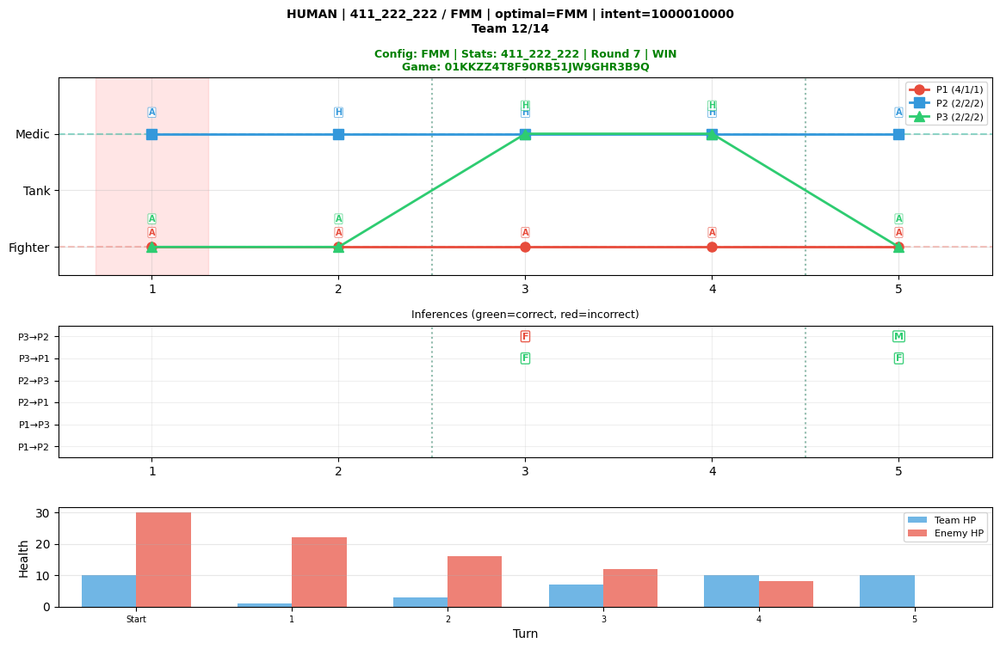

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


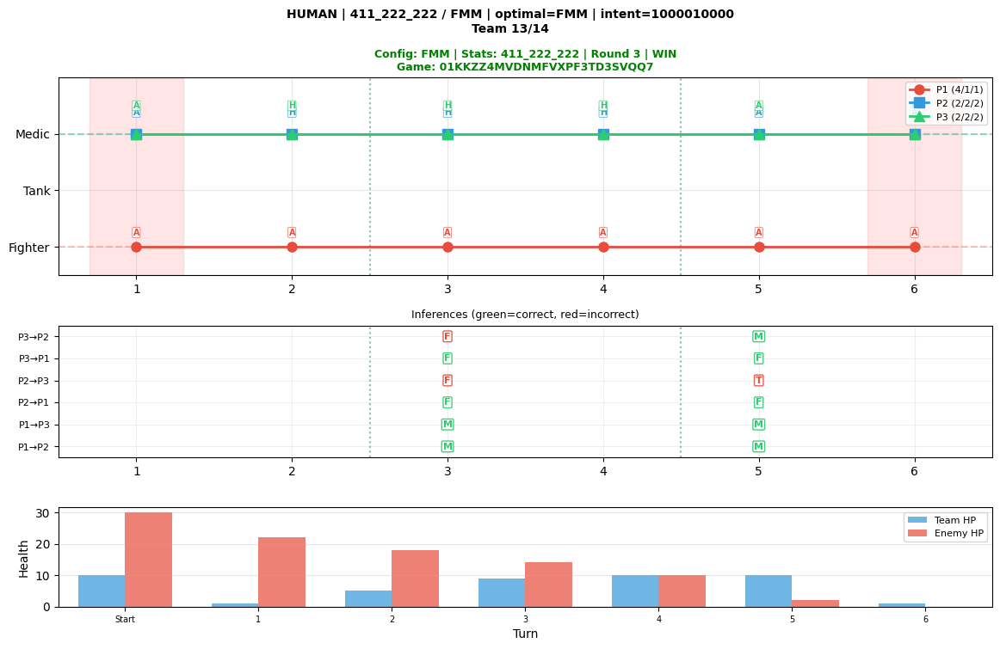

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


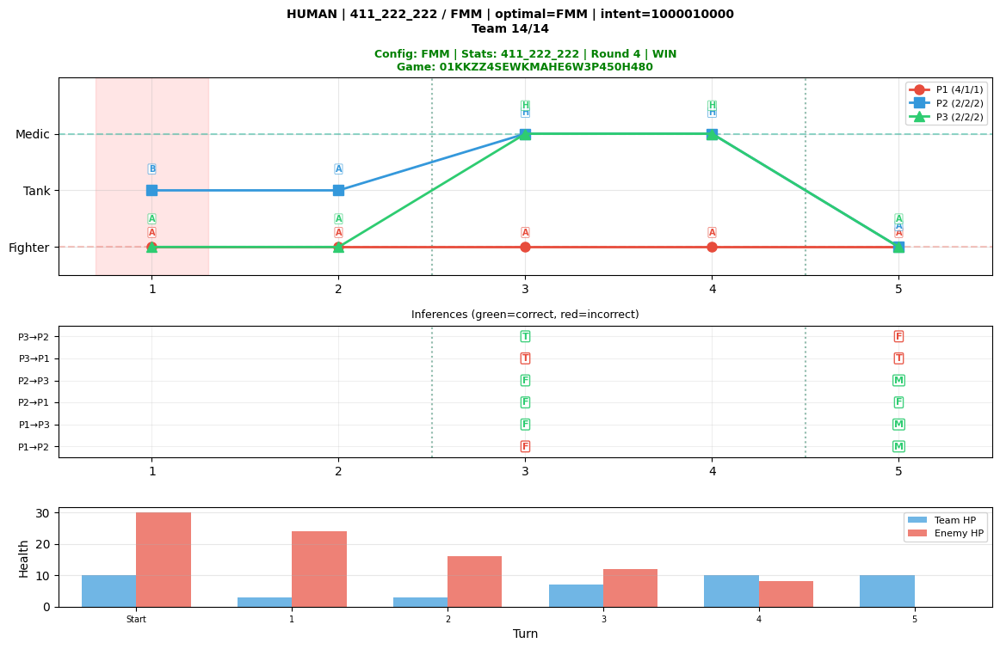

In [18]:
human_teams = group_into_teams(records, 'human')

for config_key in sorted(human_teams.keys()):
    teams = human_teams[config_key]
    print(f'\n{config_key}: {len(teams)} teams')
    plot_config_overview(config_key, teams, round_type='human')

### Bot rounds


114_222_222 / MFF_TMM: 9 teams
  Win rate: 4/9 (44%)


/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


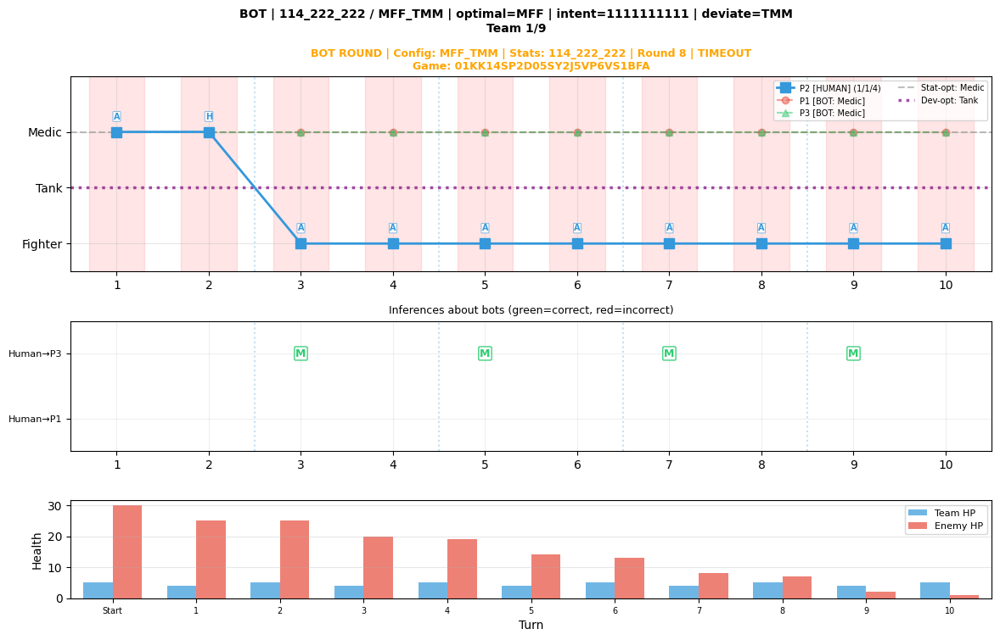

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


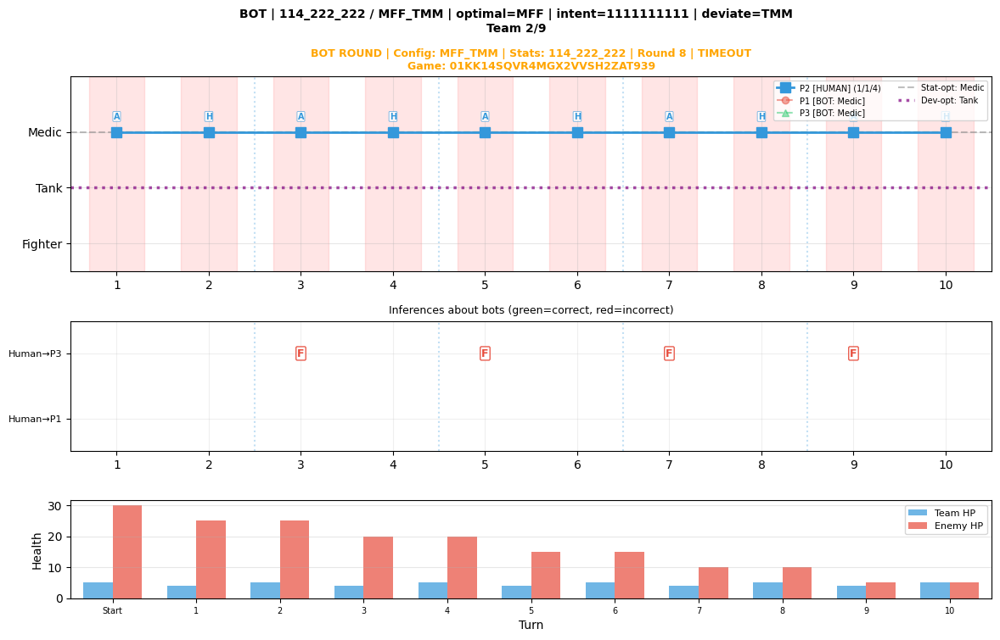

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


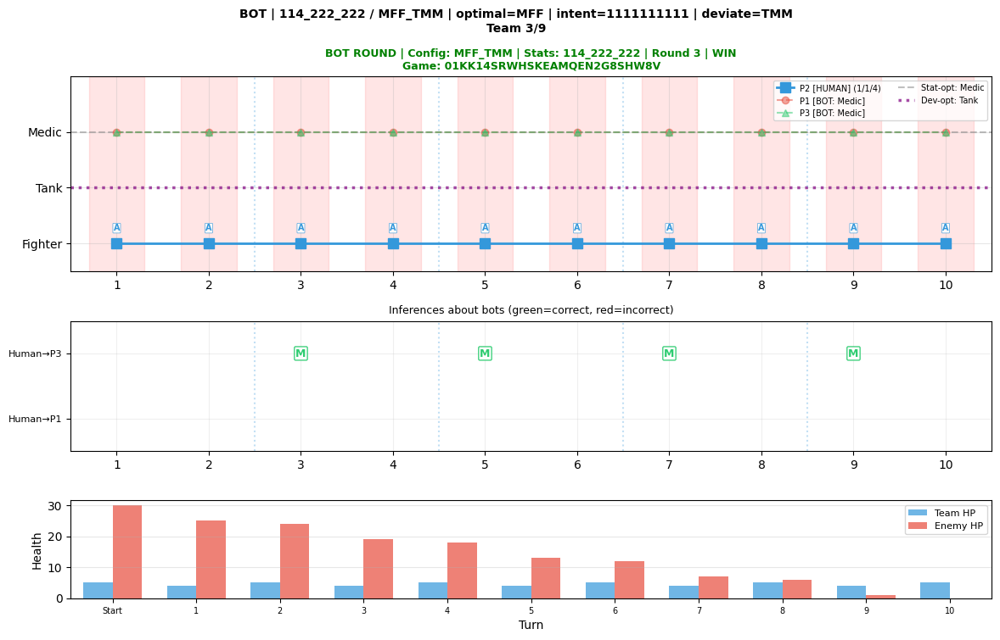

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


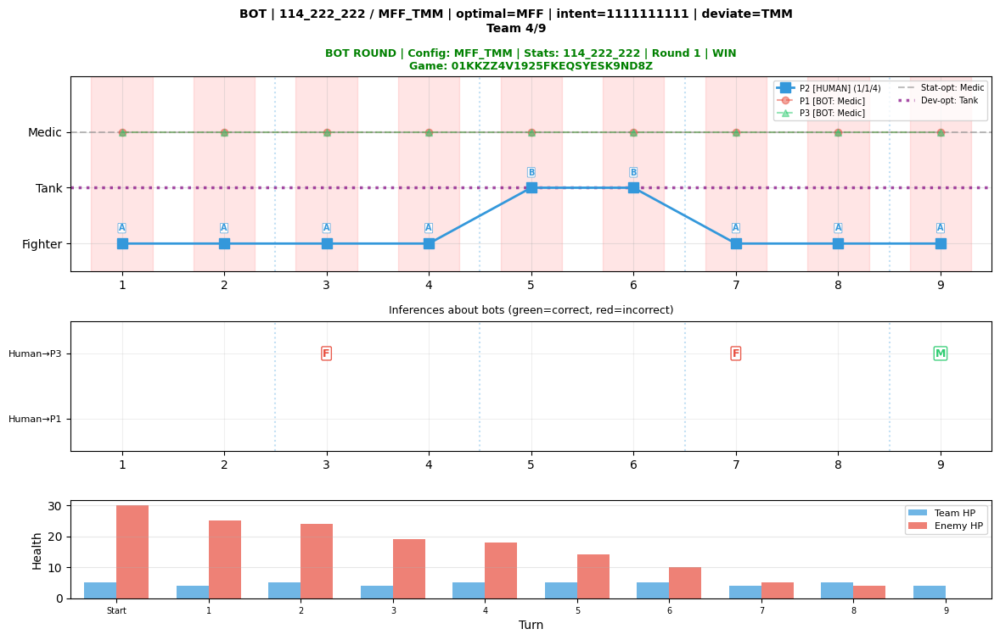

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


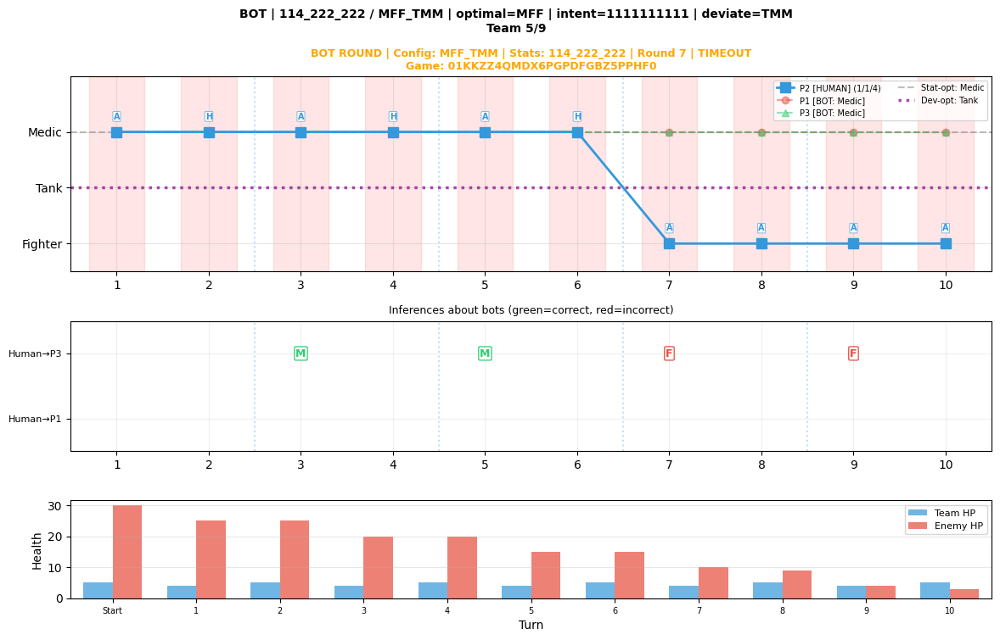

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


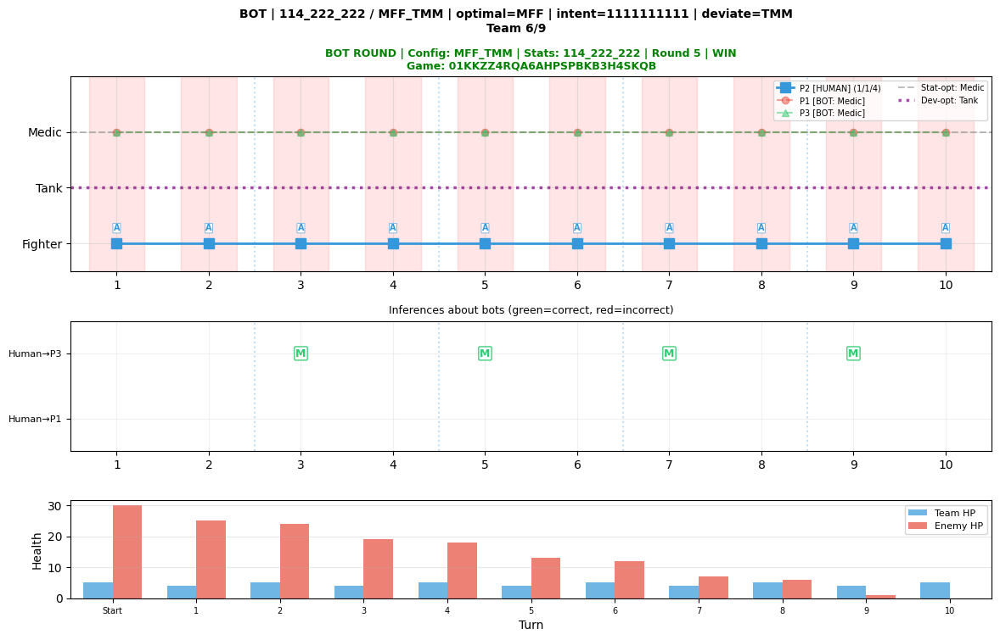

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


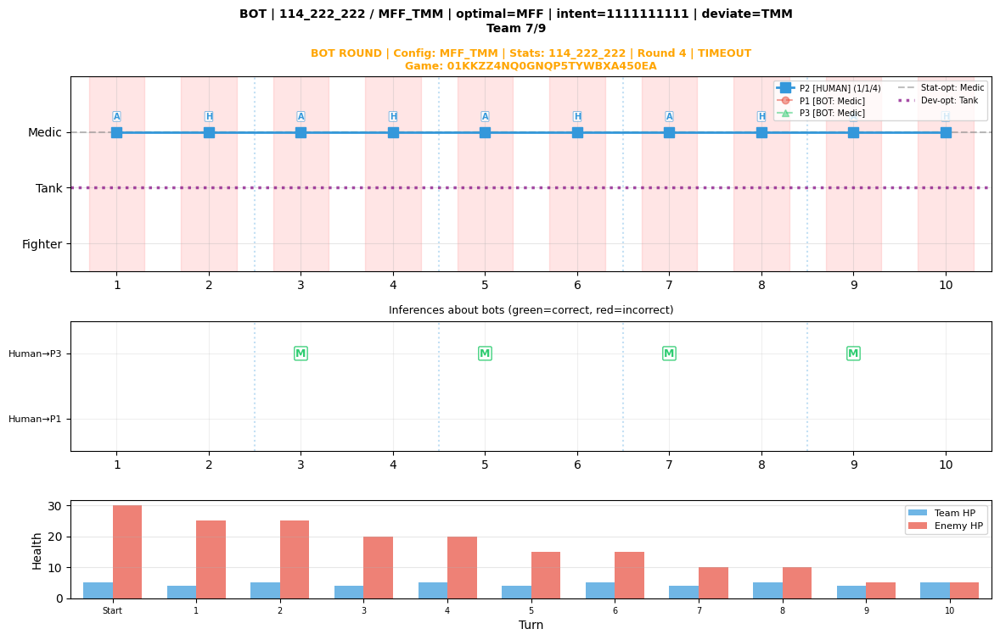

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


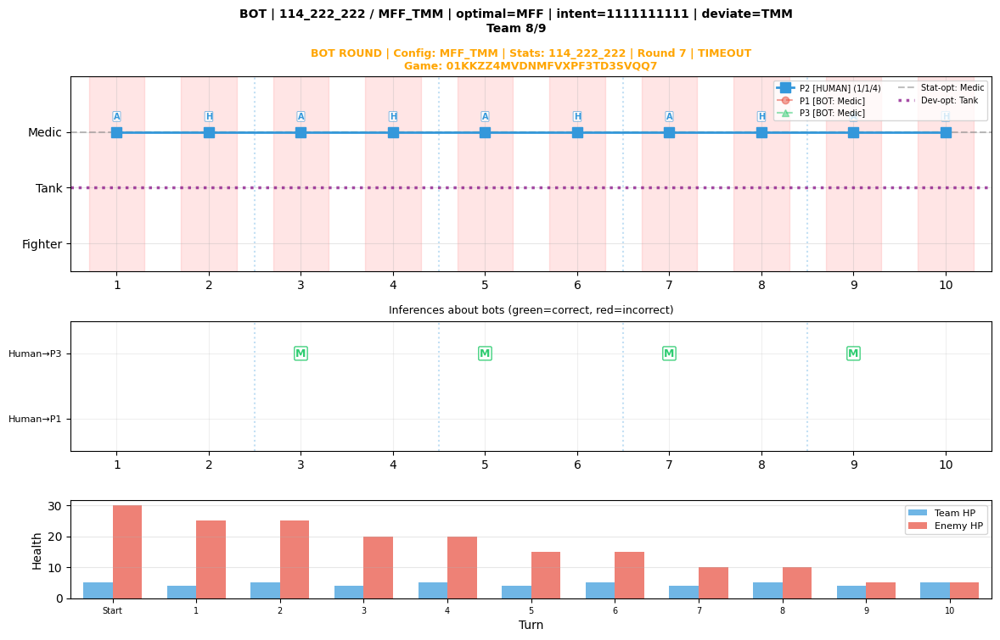

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


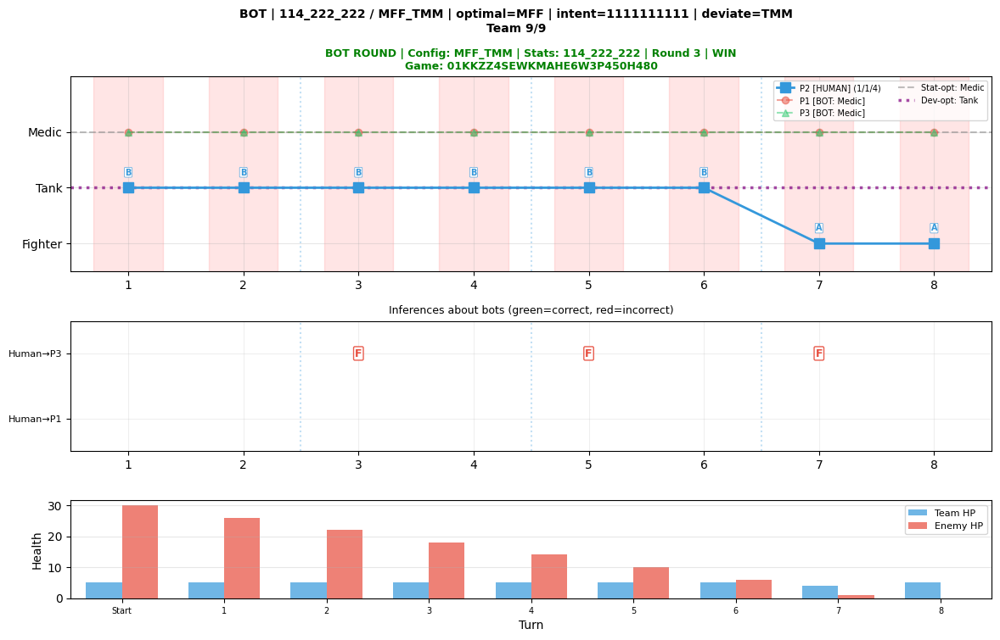


141_222_222 / TFF_FMT: 4 teams
  Win rate: 0/4 (0%)


/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


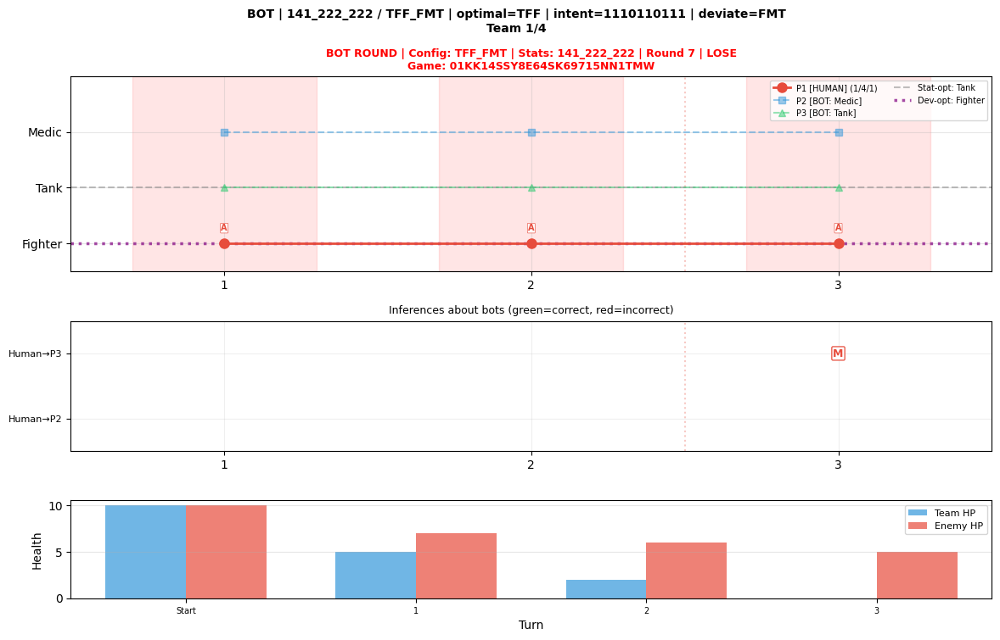

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


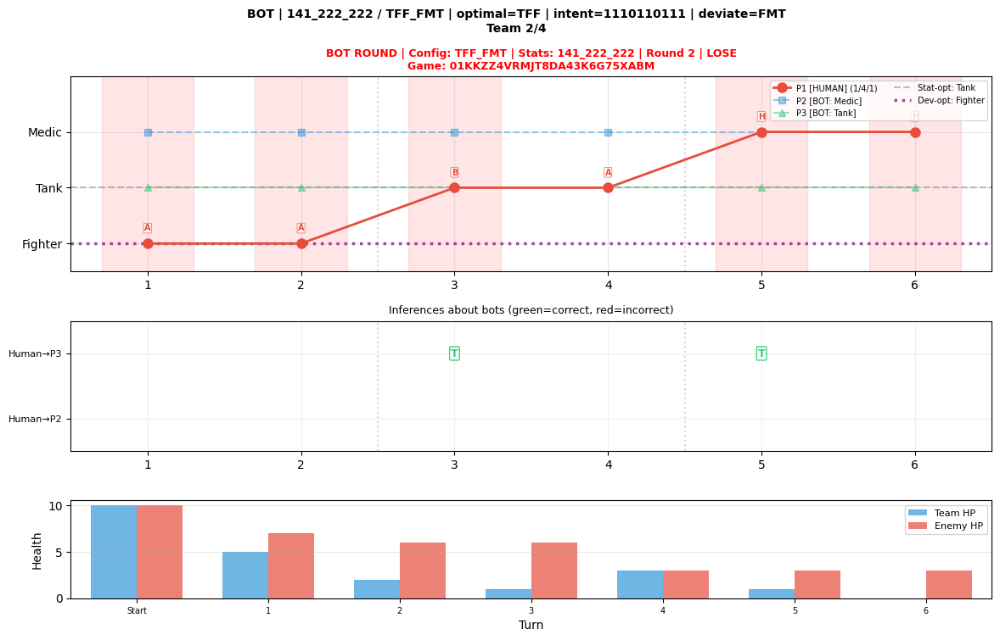

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


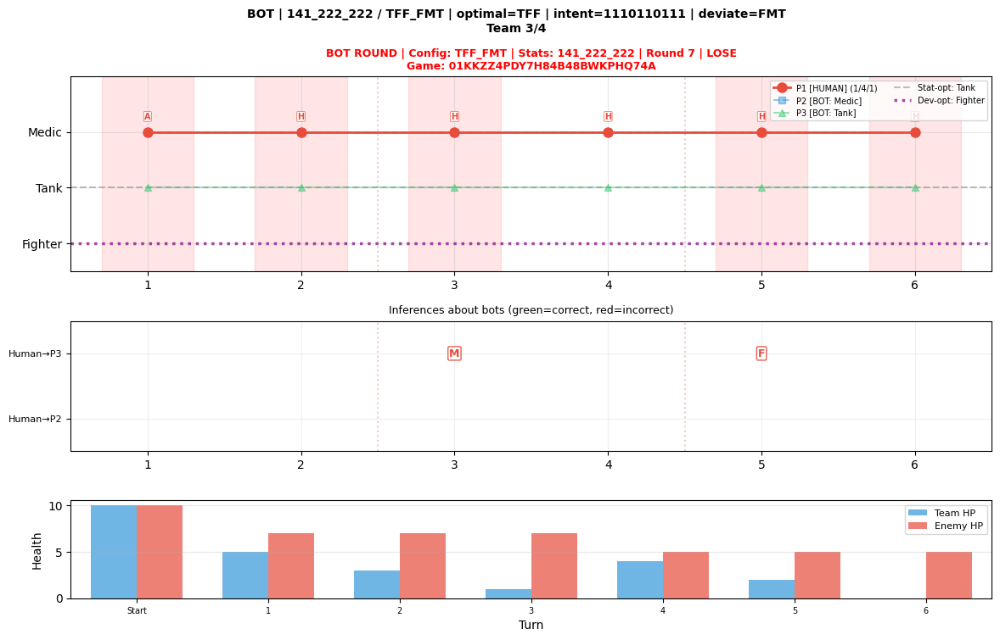

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


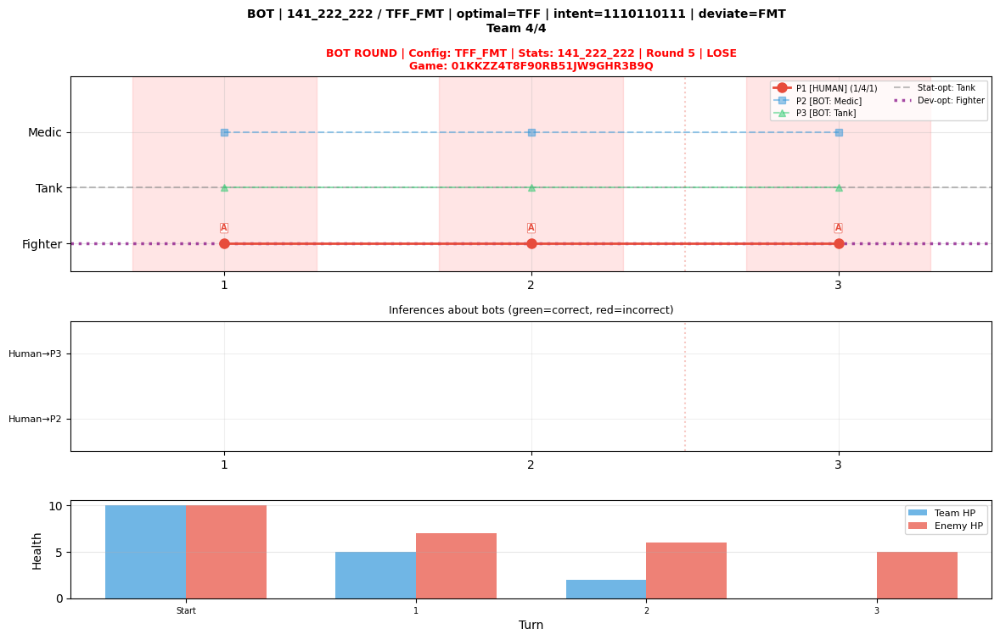

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()



141_222_222 / TMM_FFT: 1 teams
  Win rate: 0/1 (0%)


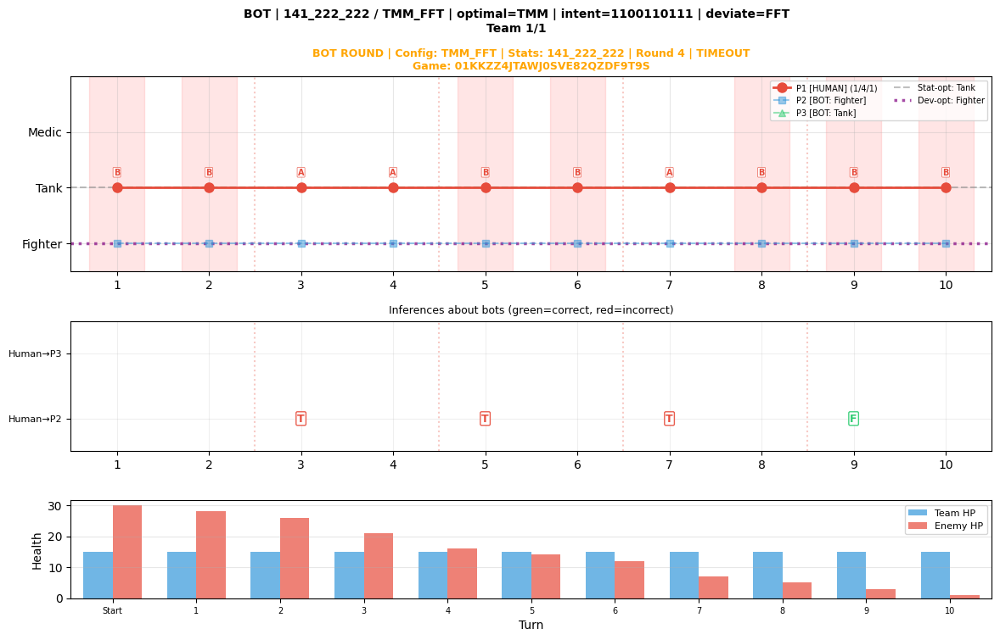


411_222_222 / FFF_MMT: 1 teams
  Win rate: 0/1 (0%)


/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


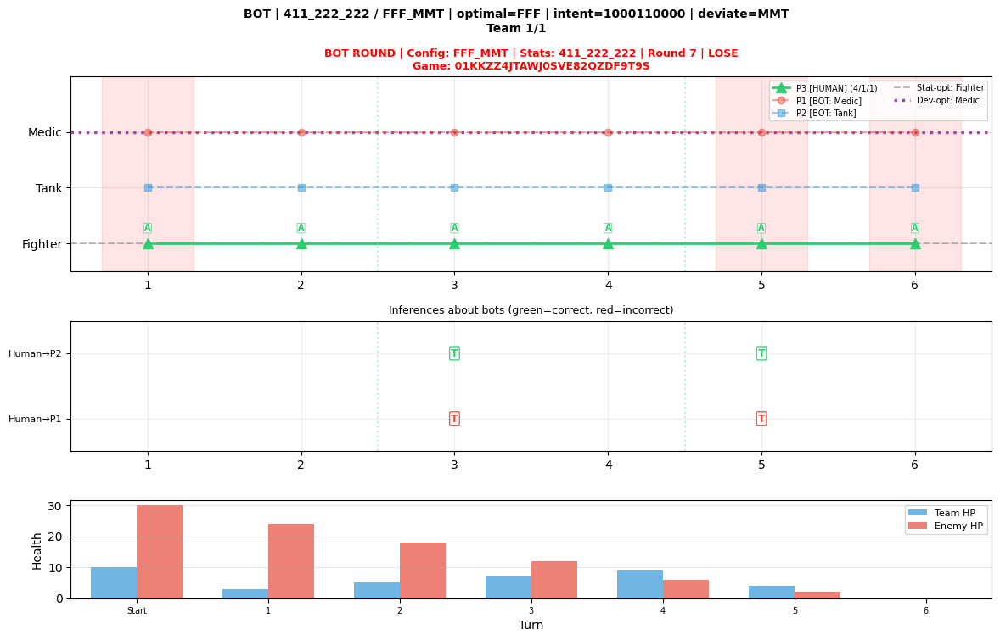


411_222_222 / FMM_MFT: 9 teams
  Win rate: 4/9 (44%)


/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


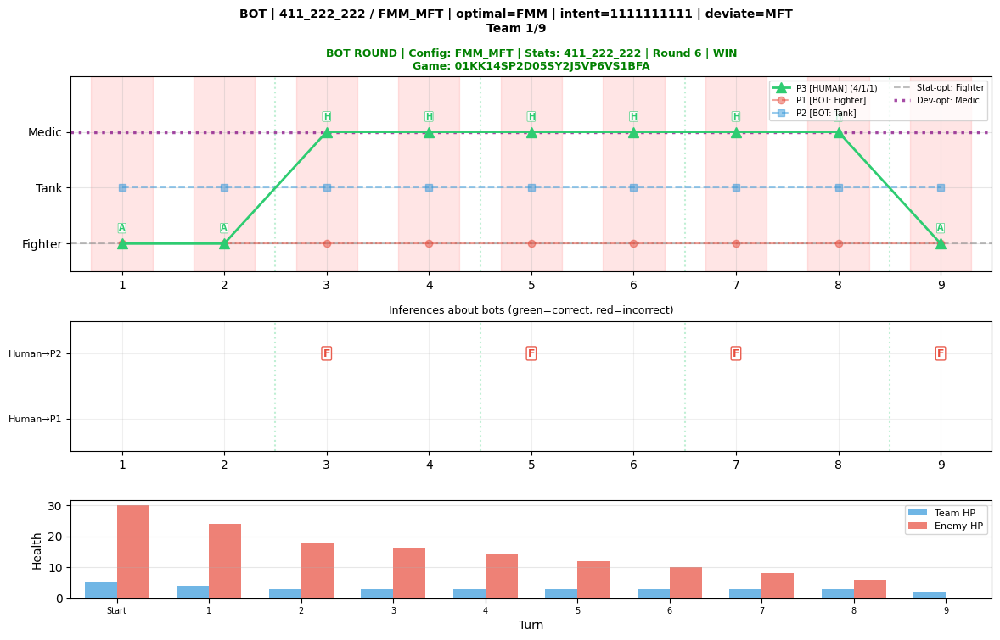

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


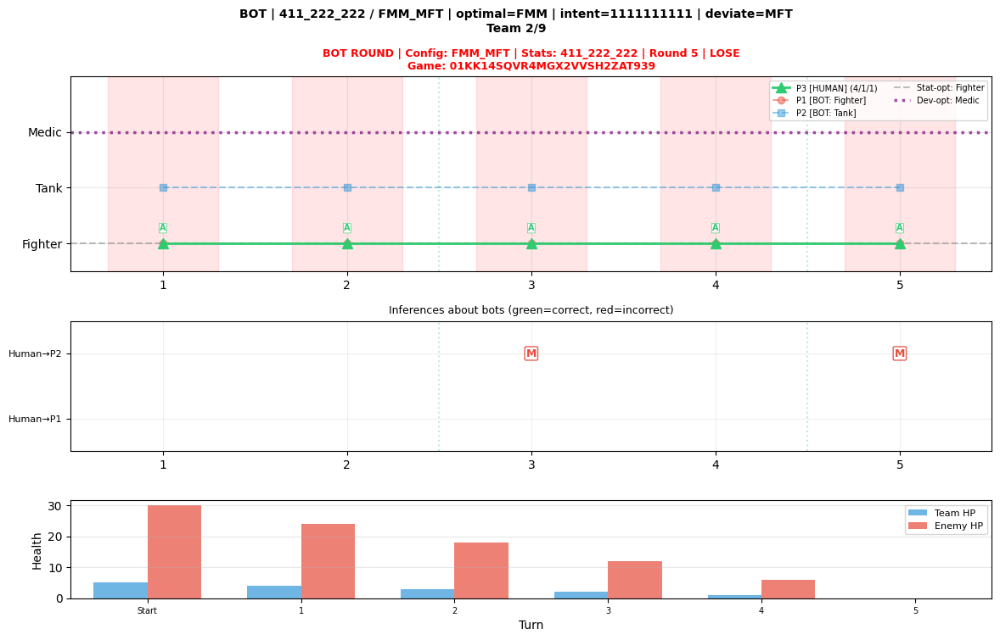

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


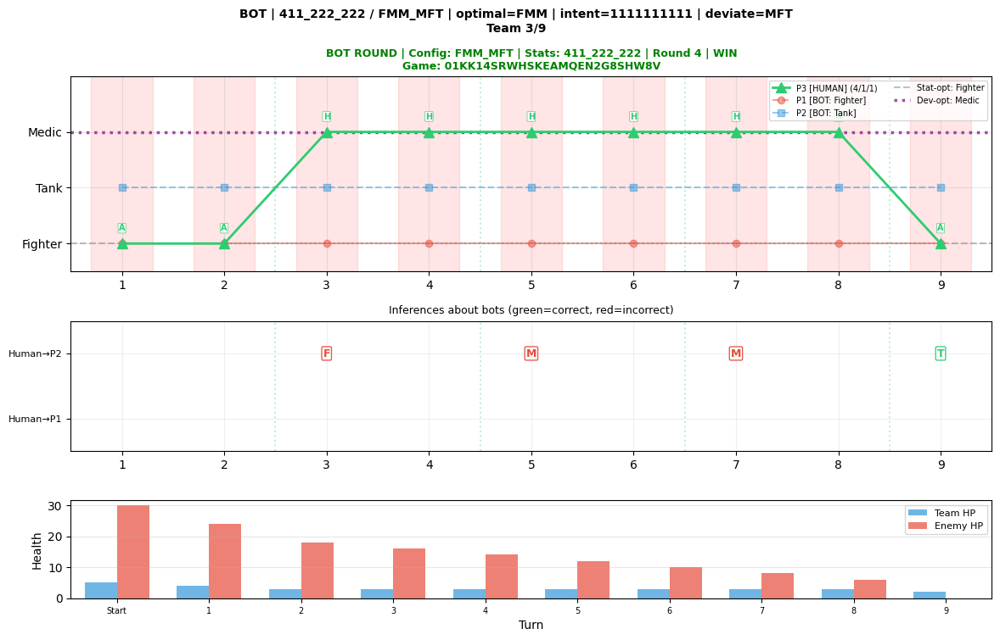

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


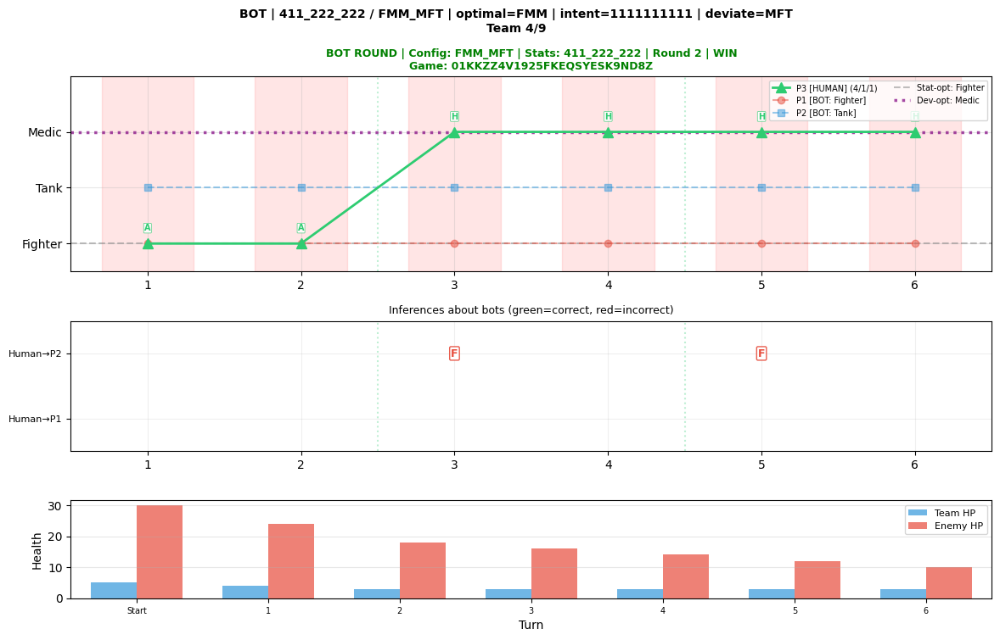

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


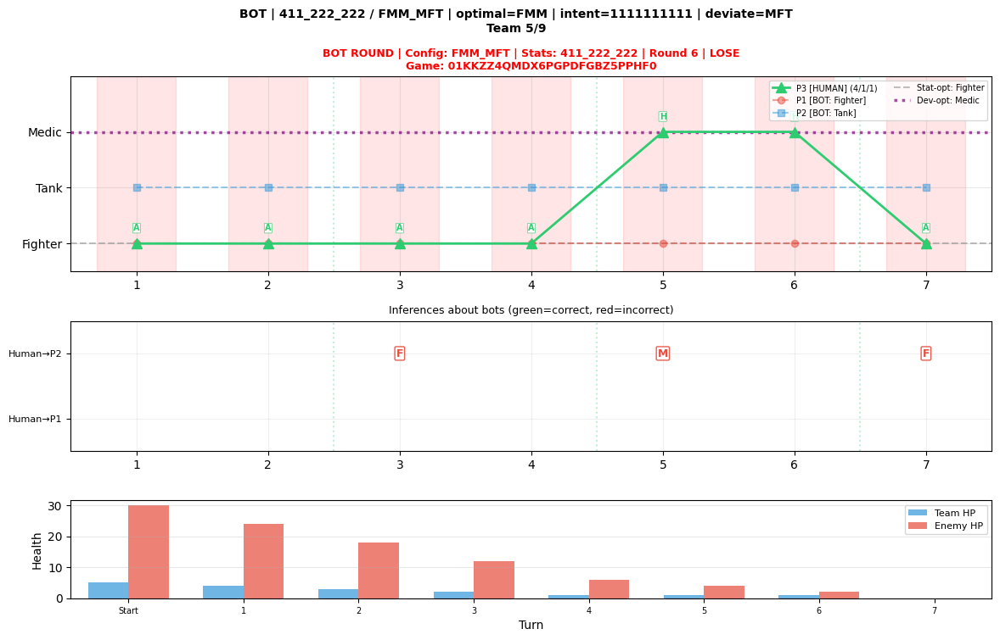

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


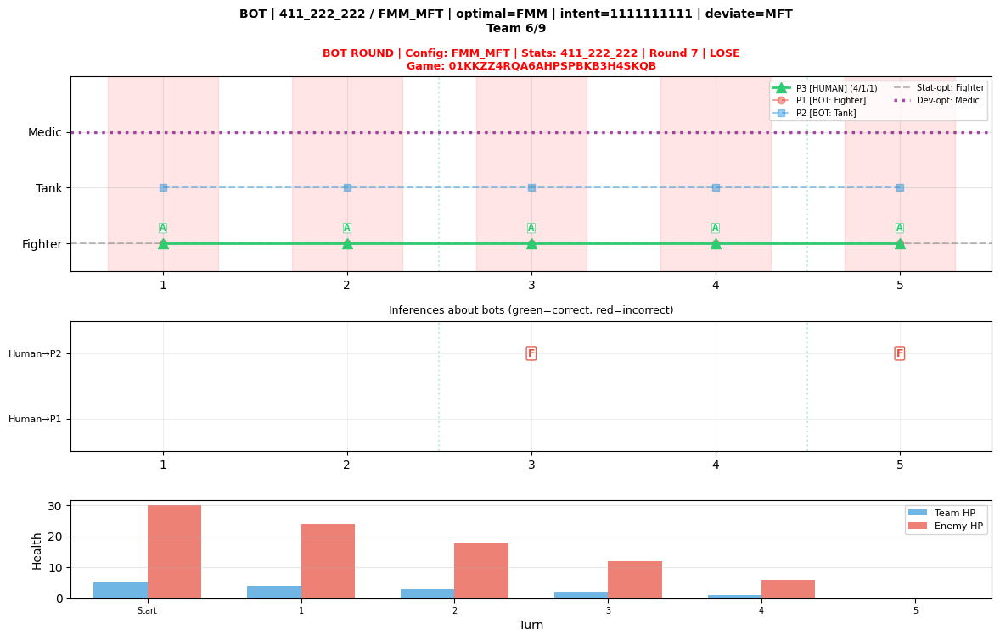

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


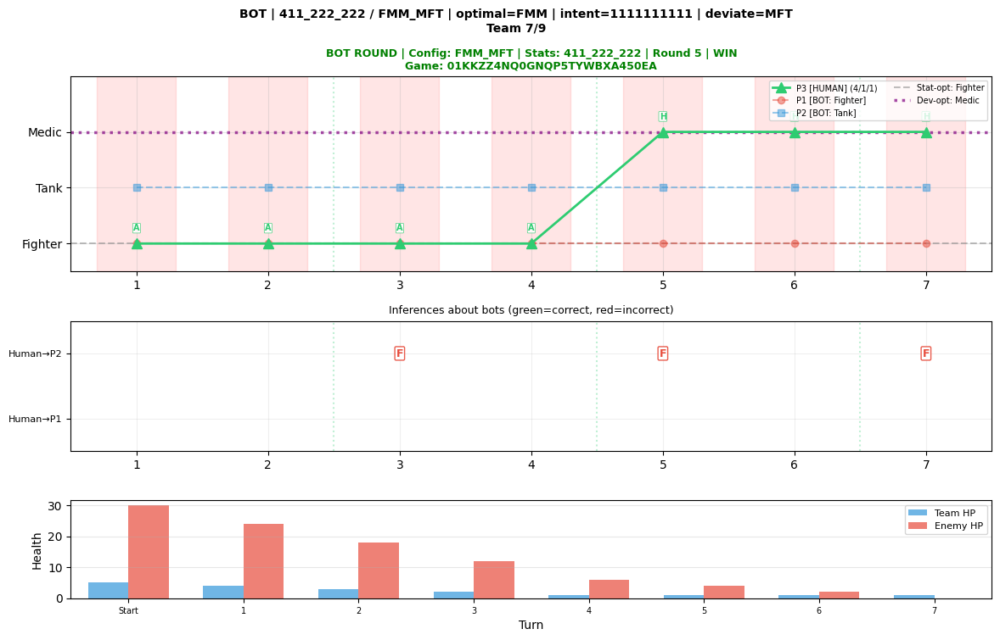

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


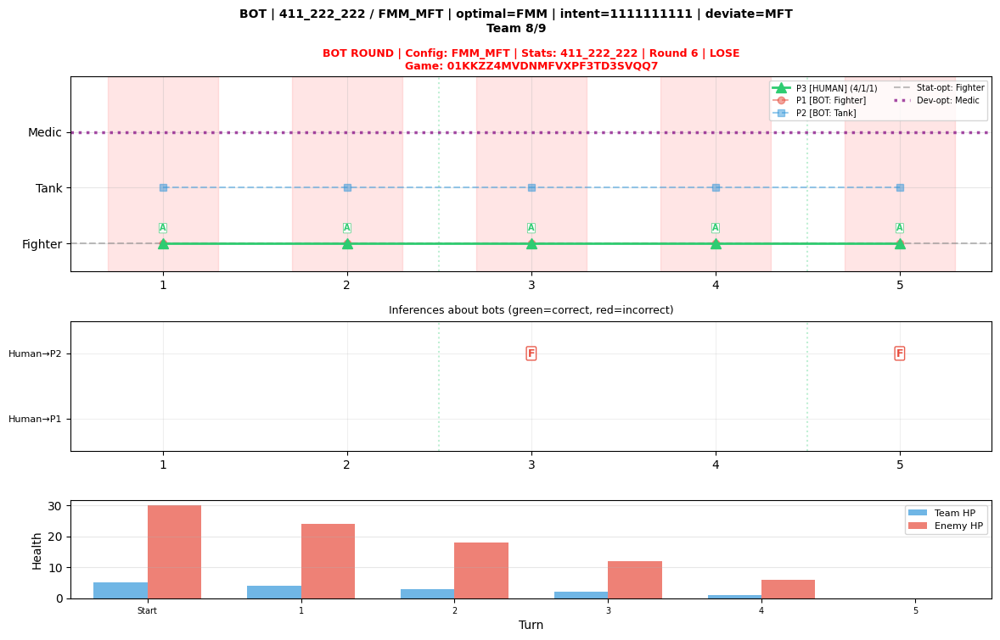

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


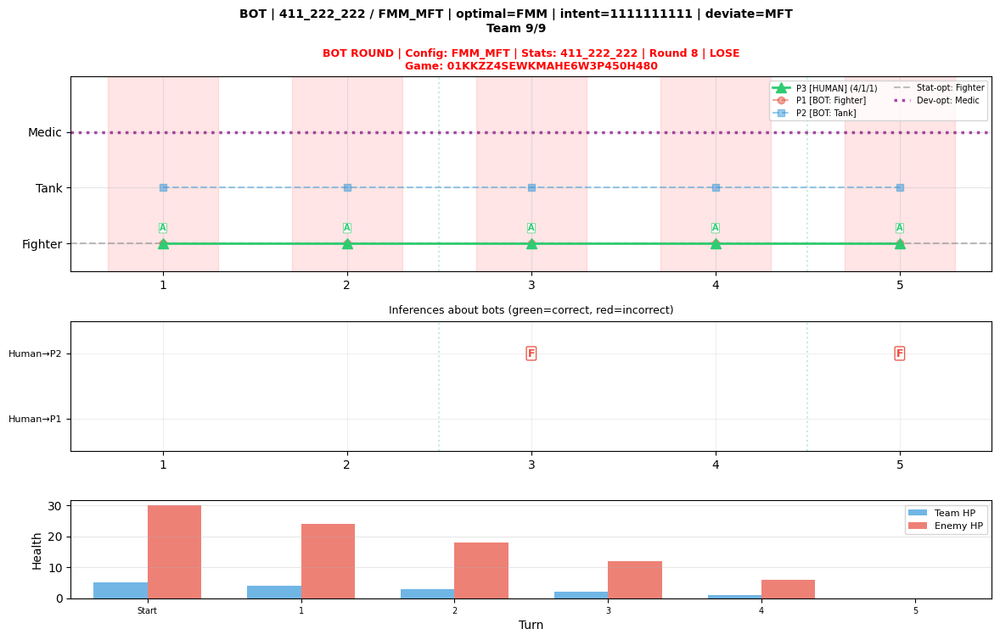


411_222_222 / FMT_TMM: 4 teams
  Win rate: 1/4 (25%)


/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


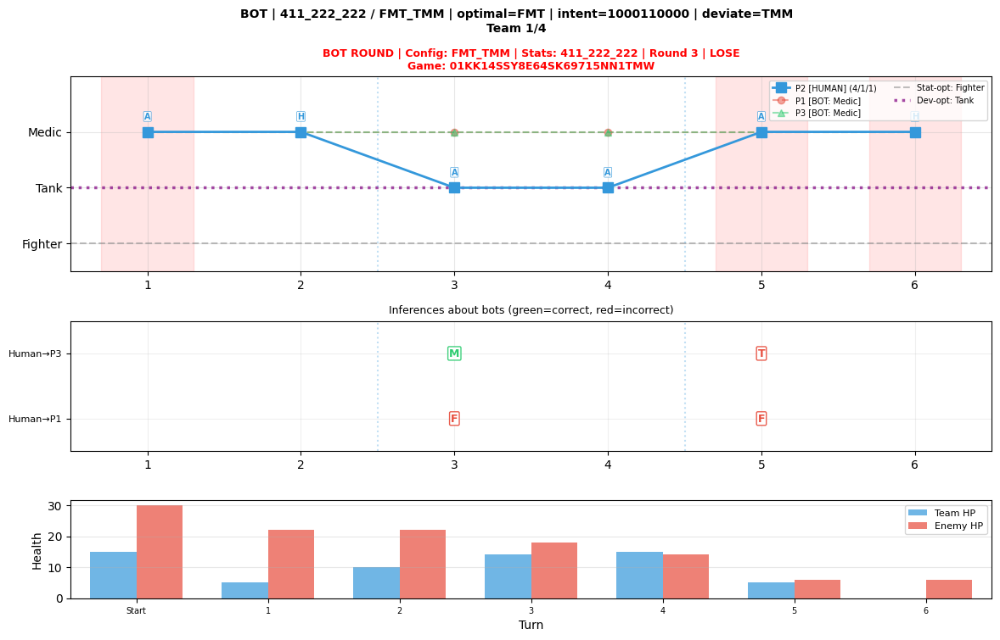

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


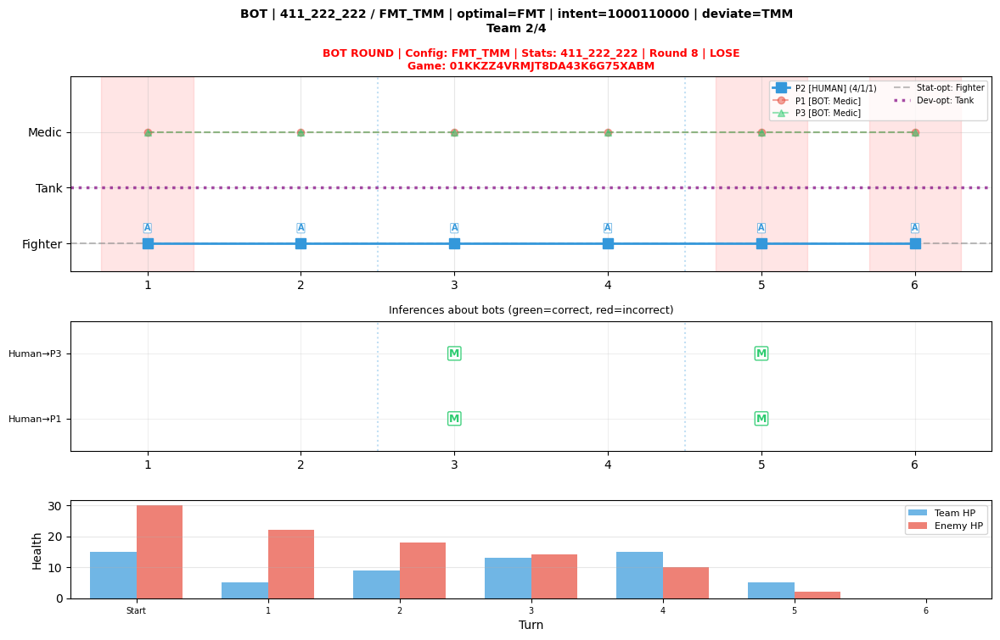

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


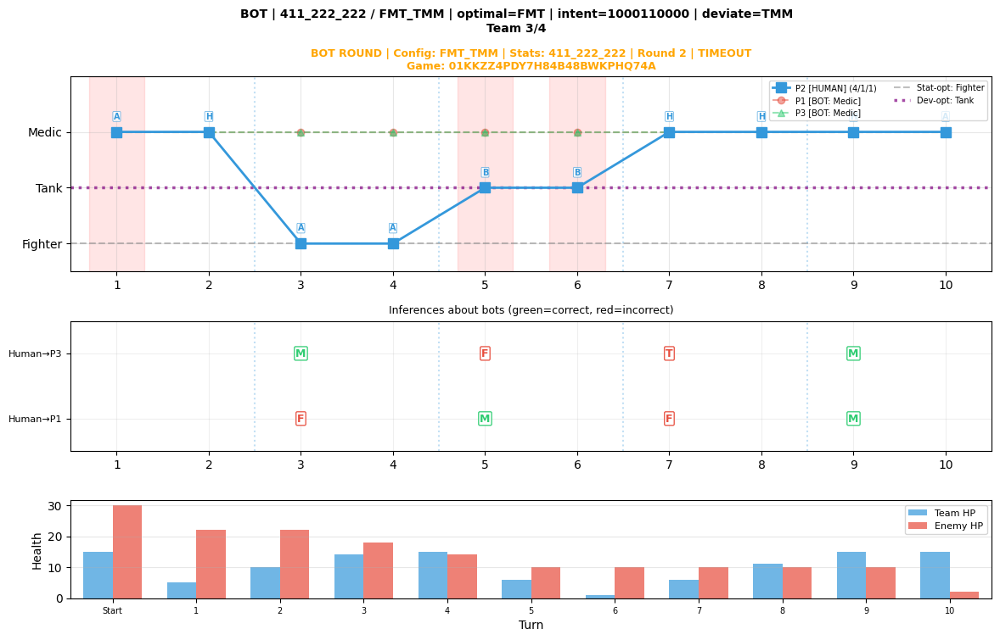

/var/folders/k7/5725k24n2rjc6qbn3ybrpqfh0000gn/T/ipykernel_91925/1255384360.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


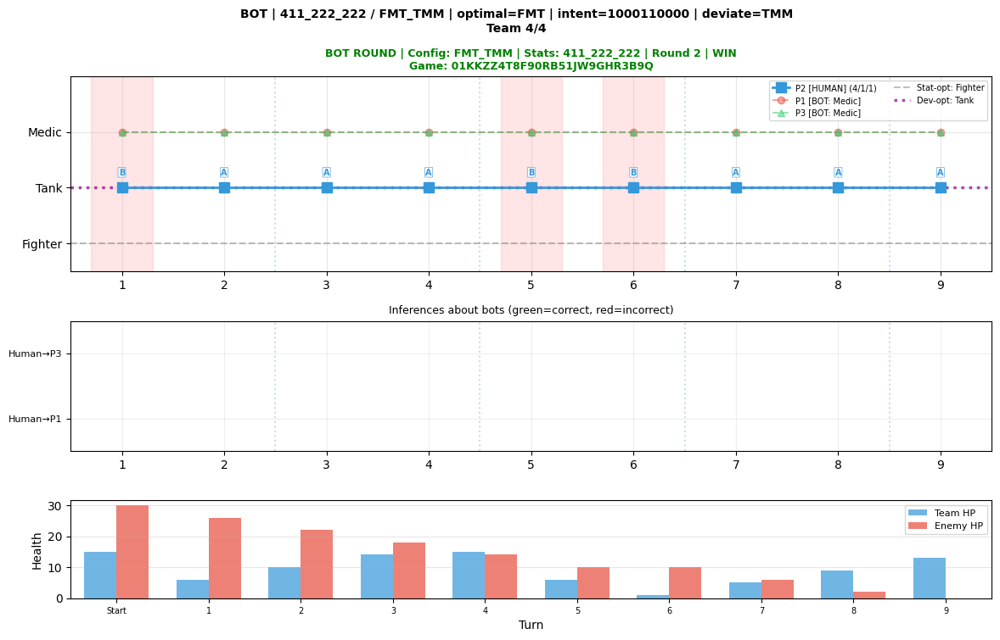

In [19]:
bot_teams = group_into_teams(records, 'bot')

for config_key in sorted(bot_teams.keys()):
    teams = bot_teams[config_key]
    print(f'\n{config_key}: {len(teams)} teams')
    plot_config_overview(config_key, teams, round_type='bot')